# Notebook 1 — Preparação e Limpeza de Dados

# Capstone Project | Liga <a class="anchor" id="Cpstone"></a>

**Authors:**\
Maria Margarida Mouteira Guerreiro Romero Antelo <a20243063@pbs.up.pt>\
Mariana Chaves Santos <a20243060@pbs.up.pt>\
Mónica Isabel da Silva Simões <a20250187@pbs.up.pt>\
Hugo Miguel Carvalho da Silva Glória <a20250093@pbs.up.pt>\
Rui Alexandre Paiva Santos <a20160686@pbs.up.pt>
>
> Publication Date: November 2025

**Table of contents:**
1. [Setup working directories](#folder_structure)
2. [Import required modules](#required_modules)
3. [Declare database manager helping functions](#db_manager)
4. [Declare technician assignment function](#logical_operators)
5. [Declare random intervencion close](#comparison_operators)
6. [Main program](#main)

---

## Setup working directories <a class="anchor" id="folder_structure"></a>
---

In [167]:
import sys 
import os 
from dotenv import load_dotenv, find_dotenv

dotenv_path = find_dotenv(usecwd=True)
if dotenv_path:
    load_dotenv(dotenv_path, override=False)
    print(f"✓ .env loaded (without overriding existing Docker variables): {dotenv_path}")
else:
    print("⚠ No .env found.")

# Determinar o diretório raiz do projeto
current_dir = os.getcwd()  
project_root = os.path.dirname(current_dir)
    
# Define paths baseados na estrutura do container
PythonScriptsPath = os.path.join(project_root, 'Python')
DataFilesPath = os.path.join(project_root, 'Base de Dados')
NotebooksPath = os.path.join(project_root, 'notebooks')
log_path = os.path.join(project_root, 'logs')

# Criar diretório de logs se não existir
os.makedirs(log_path, exist_ok=True)

# Carregar .env se existir
dotenv_path = os.path.join(project_root, '.env')
if os.path.exists(dotenv_path):
    load_dotenv(dotenv_path)
    print("✓ Loaded environment variables from .env file.")

# Adicionar paths ao sys.path
paths_to_add = [
    ('PythonScriptsPath', PythonScriptsPath),
    ('project_root', project_root),
    ('NotebooksPath', NotebooksPath)
]

# DataFilesPath normalmente não precisa estar no sys.path (é só para dados)
# Mas se tiver scripts Python lá, pode adicionar

for name, path in paths_to_add:
    if os.path.exists(path):
        if path not in sys.path:
            sys.path.insert(0, path)
            print(f"✓ Added '{name}' to path: {path}")
    else:
        print(f"⚠ '{name}' não existe: {path}")


# Crie o ficheiro __init__.py no seu notebook
init_file_path = os.path.join(PythonScriptsPath, '__init__.py')

if not os.path.exists(init_file_path):
    with open(init_file_path, 'w') as f:
        pass  # Cria um ficheiro vazio
    print(f"✓ Ficheiro __init__.py criado em: {init_file_path}")


# Verificação de configuração
print(f"\n{'='*60}")
print("CONFIGURAÇÃO DE PATHS")
print(f"{'='*60}")
print(f"Working directory:   {os.getcwd()}")
print(f"Project root:        {project_root}")
print(f"Notebooks:           {NotebooksPath}")
print(f"Python scripts:      {PythonScriptsPath}")
print(f"Data files:          {DataFilesPath}")
print(f"Logs:                {log_path}")
print(f"{'='*60}\n")


✓ .env loaded (without overriding existing Docker variables): /home/jovyan/.env
✓ Loaded environment variables from .env file.

CONFIGURAÇÃO DE PATHS
Working directory:   /home/jovyan/notebooks
Project root:        /home/jovyan
Notebooks:           /home/jovyan/notebooks
Python scripts:      /home/jovyan/Python
Data files:          /home/jovyan/Base de Dados
Logs:                /home/jovyan/logs




## Import required modules <a class="anchor" id="required_modules"></a>
---

In [168]:
# Personalized imports
from HelperFunctions import (
    Logger as log,
    DataCleaning as dc,
    FileOperations as fo,
    DataAnalysis as da,
    Distance as dist,
    DatabaseManager as dbm,
    LigaSchedule as ls,
    WeatherInformation as wi
)
import HelperFunctions as hf

# Standard library imports
import getpass
from collections import defaultdict, Counter
from datetime import timedelta, datetime, time
from itertools import combinations

# Third-party imports
import geopandas as gpd
import pandas as pd
import numpy as np
from geopy.distance import geodesic # type: ignore
from IPython.display import display # type: ignore
from statsmodels.stats.multitest import multipletests # type: ignore
from typing import Optional, List, Dict, Any



## Define program variables and setup db connection <a class="anchor" id="operators"></a>
---

In [169]:
# Definição de variáveis. Caso não existam as variáveis de sistema, o programa vai assumir as default, e pedir o user e a pass no prompt
try:
    pbs_host = os.environ.get('PBS_CAPSTONE_HOST') 
    pbs_port = int(os.environ.get('PBS_CAPSTONE_PORT'))  # type: ignore
    pbs_db = os.environ.get('PBS_CAPSTONE_DB', 'liga')
    pbs_user = os.environ.get('PBS_CAPSTONE_USER')
    if pbs_user is None:
        pbs_user = userdata.get('PBS_CAPSTONE_USER') # type: ignore
        if pbs_user is None:
          pbs_user = input("Enter user: ") 
    pbs_password = os.environ.get("PBS_CAPSTONE_PASS")
    if pbs_password is None: 
        pbs_password = userdata.get('PBS_CAPSTONE_PASS') # type: ignore
        if pbs_password is None:
            # If you don't have defined your environment variable,
            # then add it manually
            # Never type your password as plain text
            pbs_password=getpass.getpass("Enter password: ") # type: ignore

    # Configuração da base de dados
    DB_CONFIG = {
        'host': pbs_host,
        'user': pbs_user,
        'password': pbs_password,
        'database': pbs_db,
        'port': pbs_port,
        'charset': 'utf8mb4'
    }

except Exception as e:
    print(f"Erro: {e}")



## Main program <a class="anchor" id="main"></a>
---

In [170]:
# Cria uma instância do DatabaseManager

db_logger = log.setup_logger('comandos_bd', log_dir=log_path)
db_manager = dbm(DB_CONFIG, db_logger, joint_query_file='JoinTablesQuery.sql', sql_base_path=DataFilesPath)

# Cria o log do programa principal
logger_main = log.setup_logger('main', log_dir=log_path)

df_merged = pd.DataFrame()

try:
    # 1. Primeiro, certificar que a base de dados está configurada (tabelas existem).
    # A conexão será estabelecida automaticamente por setup_database, se necessário
    if db_manager.setup_database():
        logger_main.info("Configuração da base de dados concluída com sucesso.")

        # 2. Agora, use a mesma instância do DatabaseManager para buscar os DataFrames
        # A conexão será estabelecida automaticamente por get_dataframe, se necessário
        logger_main.info("Tentando obter DataFrames das tabelas usando get_dataframe()...")

        # A query com o joint para estas tabelas já está definida por defeito na HelperFunctions
        df_merged = db_manager.get_dataframe_from_query()

        if df_merged is not None:
            logger_main.info("DataFrames obtidos com sucesso.")
            print(f"\nData loading succes. Table information:\n {df_merged.dtypes}")
            da.quick_summary(df_merged, show_plots=False)
            print("\nDataFrame preview:")
            display(df_merged.head(5))
        else:
            logger_main.info(f"Carregamento do DataFrame: {df_merged} sem sucesso.")
            raise ValueError("A execução foi interrompida porque o DataFrame não foi carregado corretamente.")
    else:
        logger_main.error("Falha na configuração da base de dados. Não foi possível prosseguir para obter os DataFrames.")
        raise ValueError("A execução foi interrompida porque o DataFrame não foi carregado corretamente.")
except Exception as e:
    logger_main.error(f"Erro: {e}")
    raise
finally:
    db_manager.disconnect() # Desconecte após o uso de todos os DataFrames

INFO - O log '/home/jovyan/logs/comandos_bd.log' é recente. O novo conteúdo será anexado.
INFO - O log '/home/jovyan/logs/main.log' é recente. O novo conteúdo será anexado.


ValueError: A execução foi interrompida porque o DataFrame não foi carregado corretamente.

In [ ]:
# Clean duration and Code features, as they have no meaning in the analysis
if df_merged is not None and not df_merged.empty:
    df_merged.drop(['Duration', 'Codigo'], inplace=True, axis=1)

## Exploratory Data Analysis
---


Allianz Cup Data Summary:
QUICK DATA SUMMARY
Shape: (869, 13)
Memory usage: 0.45 MB

Data Types:
object             10
float64             1
timedelta64[ns]     1
int64               1
Name: count, dtype: int64

Missing Values:
         Missing Count   Missing %
Jornada            869  100.000000
Hora                20    2.301496
Station            869  100.000000
Rat                869  100.000000
Shr                869  100.000000
Rch                869  100.000000

Numeric Columns Summary:
       Jornada                       Hora   Espetadores
count      0.0                        849    869.000000
mean       NaN  0 days 17:47:41.484098939   3875.348677
std        NaN  0 days 02:04:34.563037808   7346.360318
min        NaN            0 days 11:00:00      0.000000
25%        NaN            0 days 16:00:00    461.000000
50%        NaN            0 days 17:30:00    889.000000
75%        NaN            0 days 19:45:00   2736.000000
max        NaN            0 days 21:15:00  49652.000

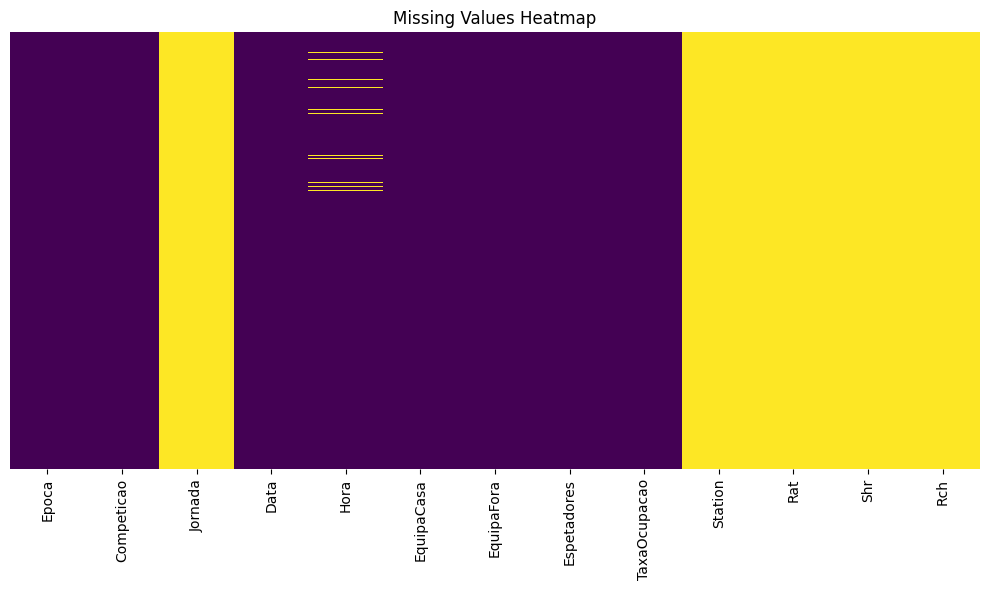

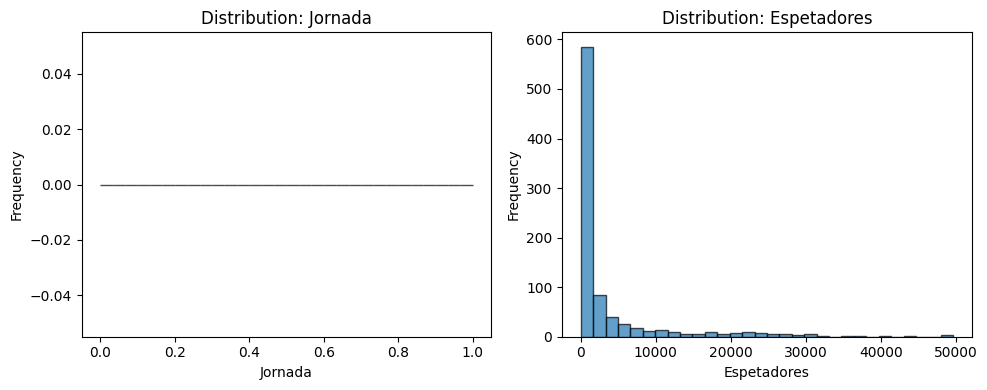

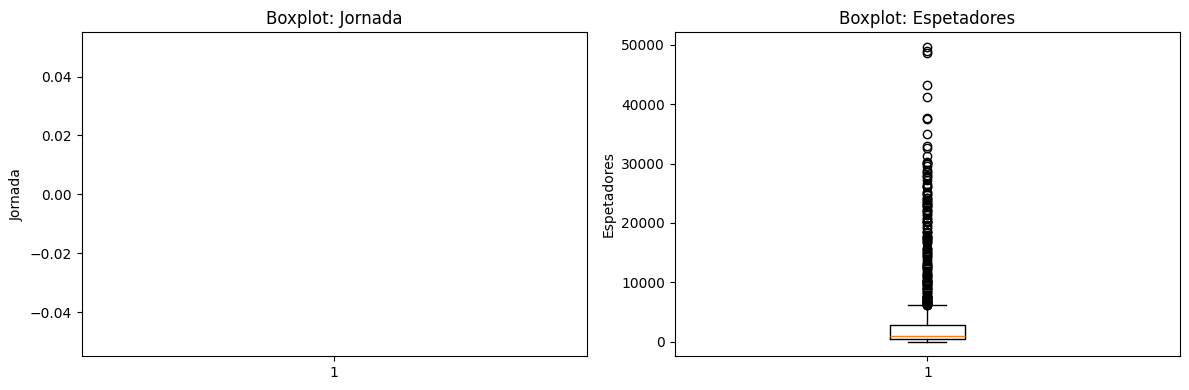

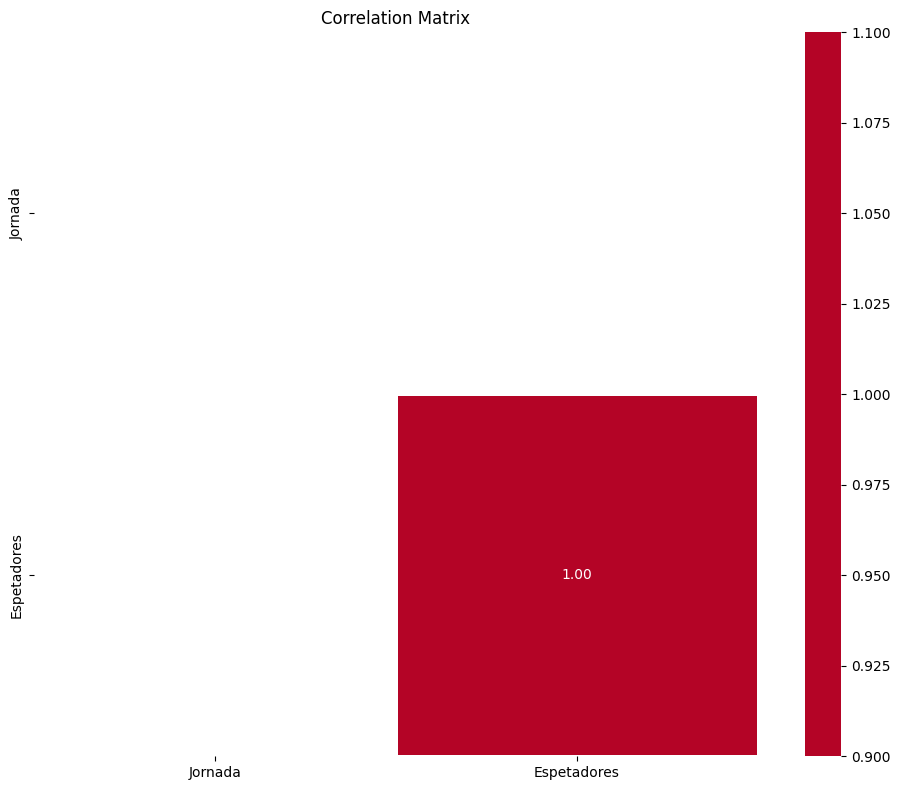


'Hora' appears to be time of day


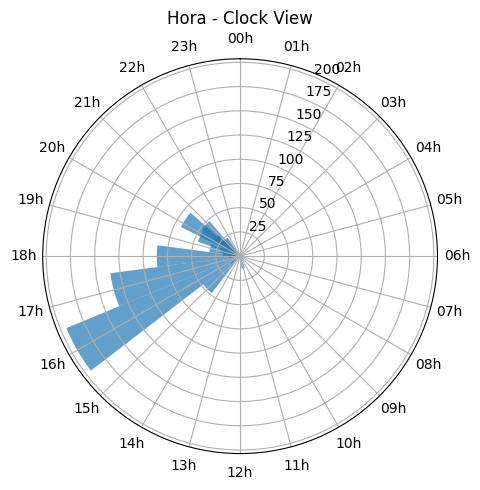

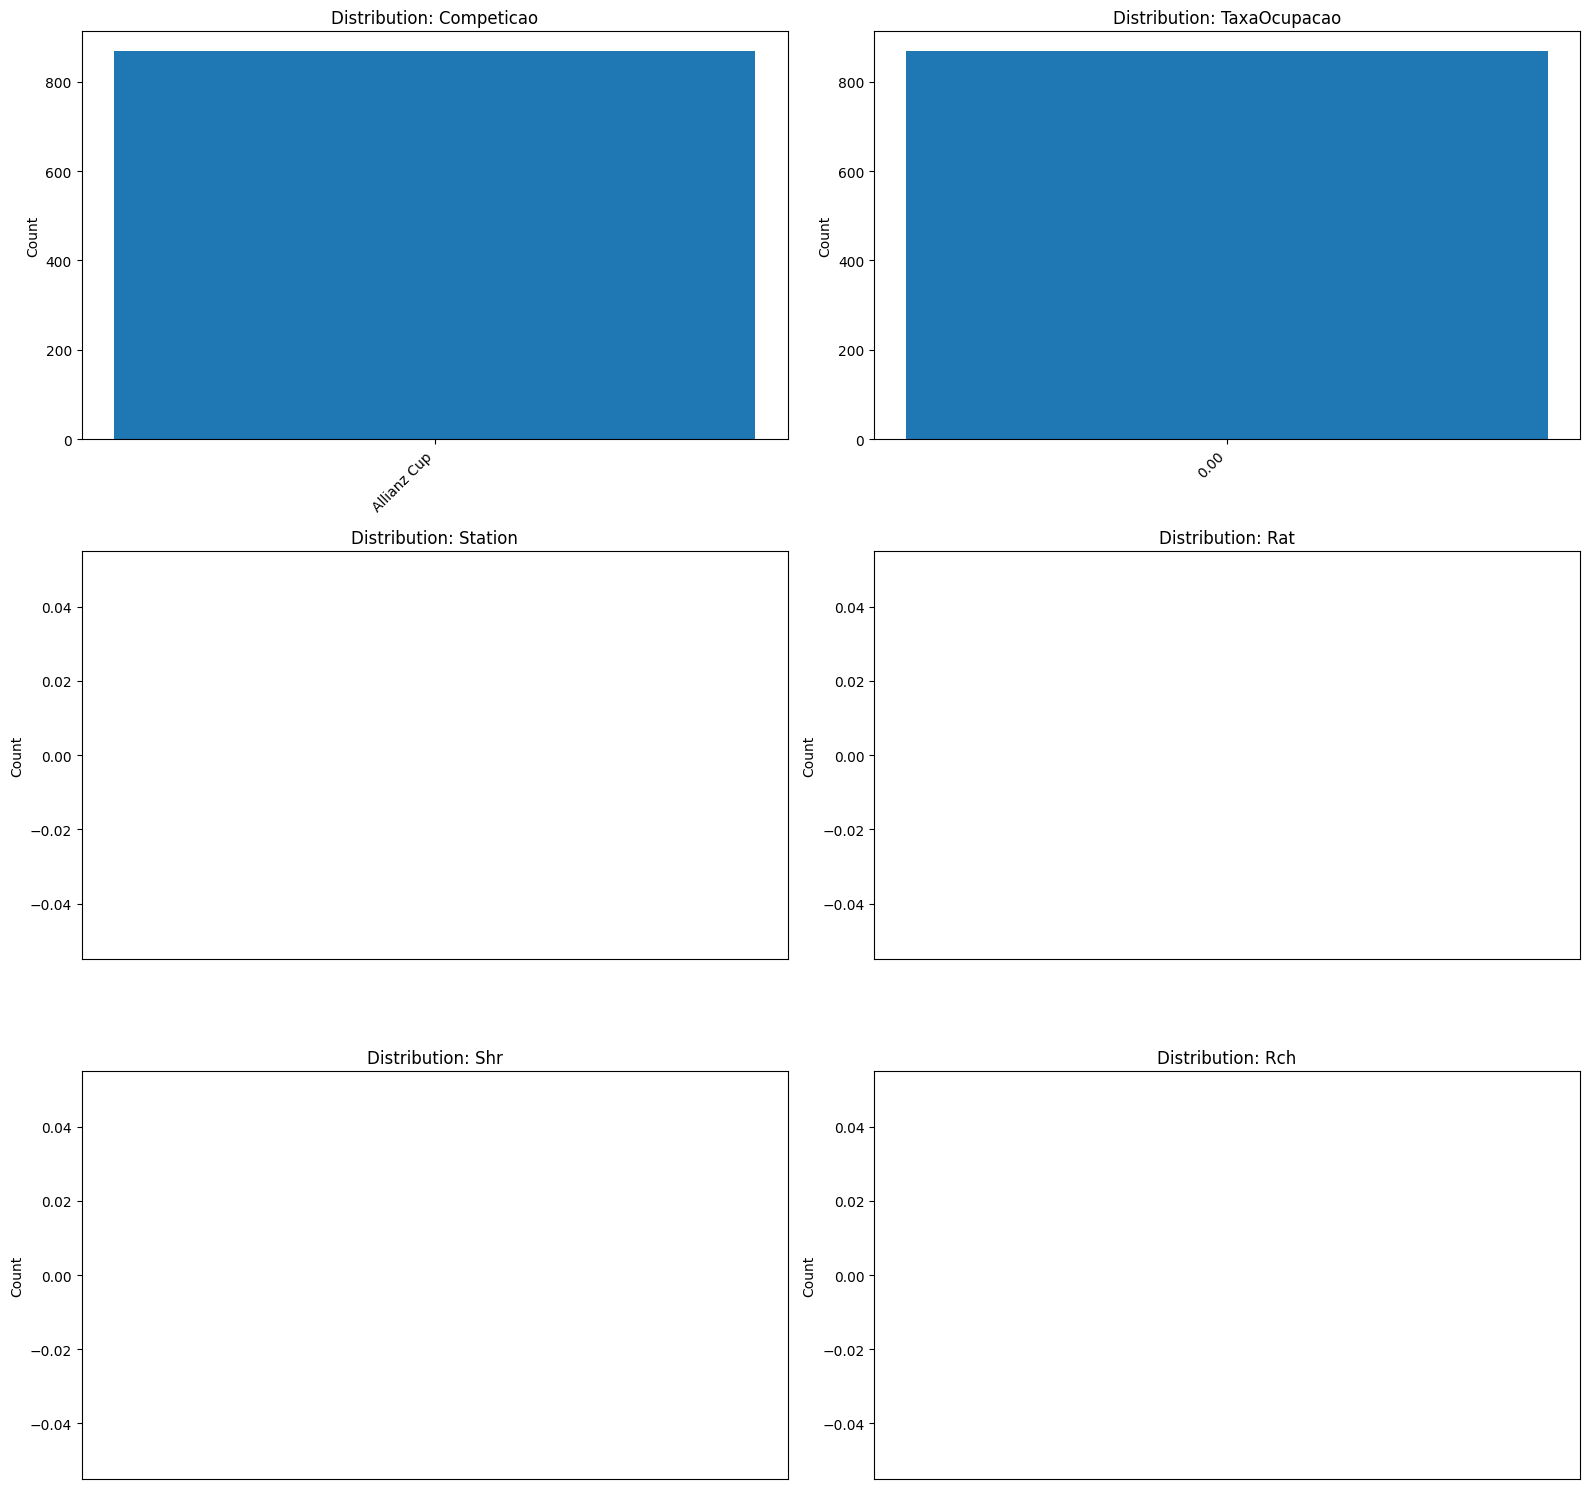


Liga Portugal Betclic Data Summary:
QUICK DATA SUMMARY
Shape: (3846, 13)
Memory usage: 2.28 MB

Data Types:
object             10
float64             1
timedelta64[ns]     1
int64               1
Name: count, dtype: int64

Missing Values:
         Missing Count  Missing %
Station           2353  61.180447
Rat               2353  61.180447
Shr               2353  61.180447
Rch               2353  61.180447

Numeric Columns Summary:
           Jornada                       Hora   Espetadores
count  3846.000000                       3846   3846.000000
mean     17.250390  0 days 18:22:08.190327613   9838.526781
std       9.697879  0 days 02:01:18.355649699  14523.292177
min       1.000000            0 days 11:45:00      0.000000
25%       9.000000            0 days 16:00:00   1643.000000
50%      17.000000            0 days 18:14:00   3411.500000
75%      26.000000            0 days 20:15:00   9688.750000
max      34.000000            0 days 21:45:00  64591.000000

Generating exploratory 

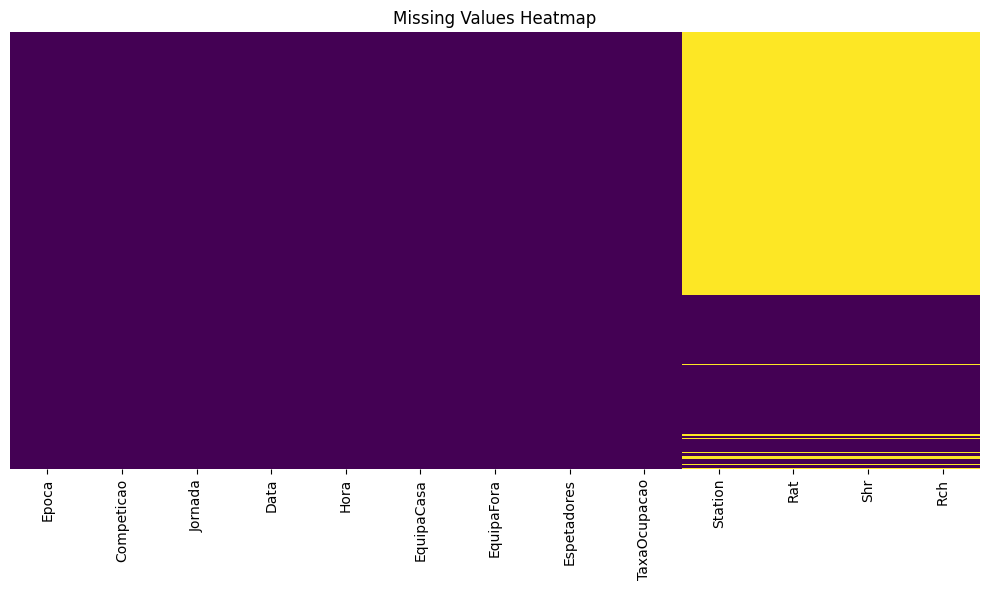

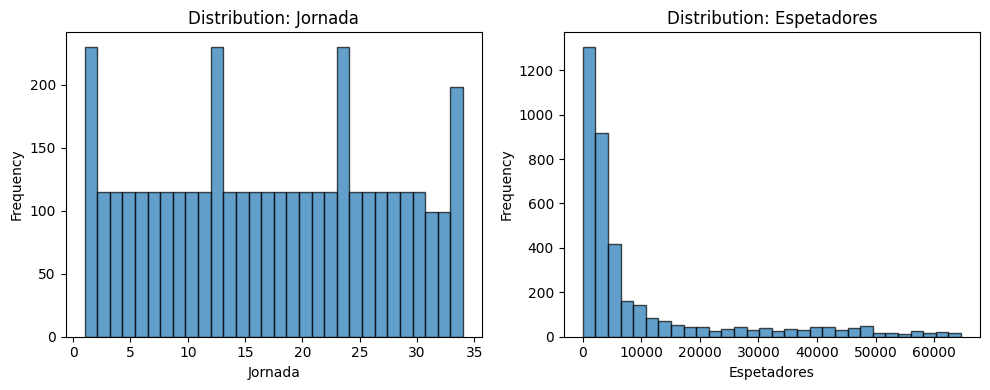

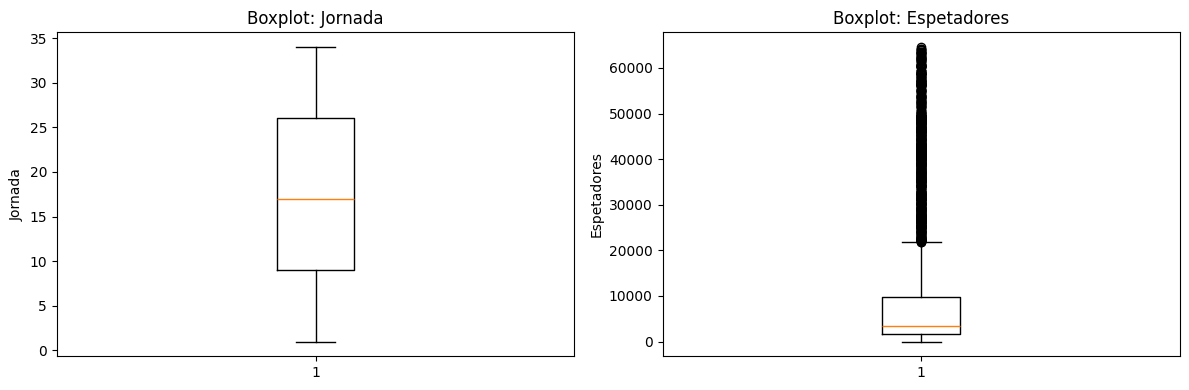

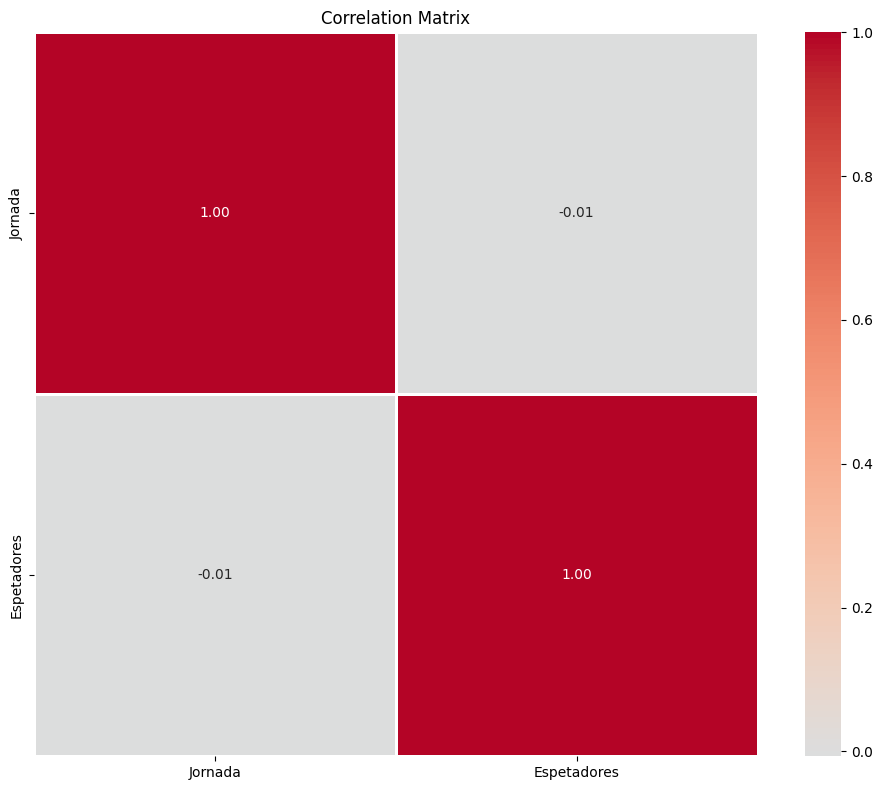


'Hora' appears to be time of day


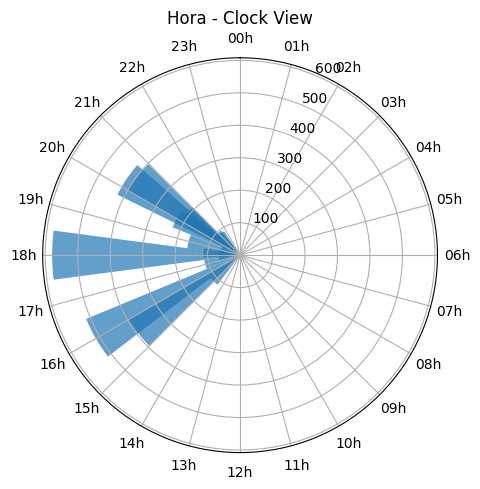

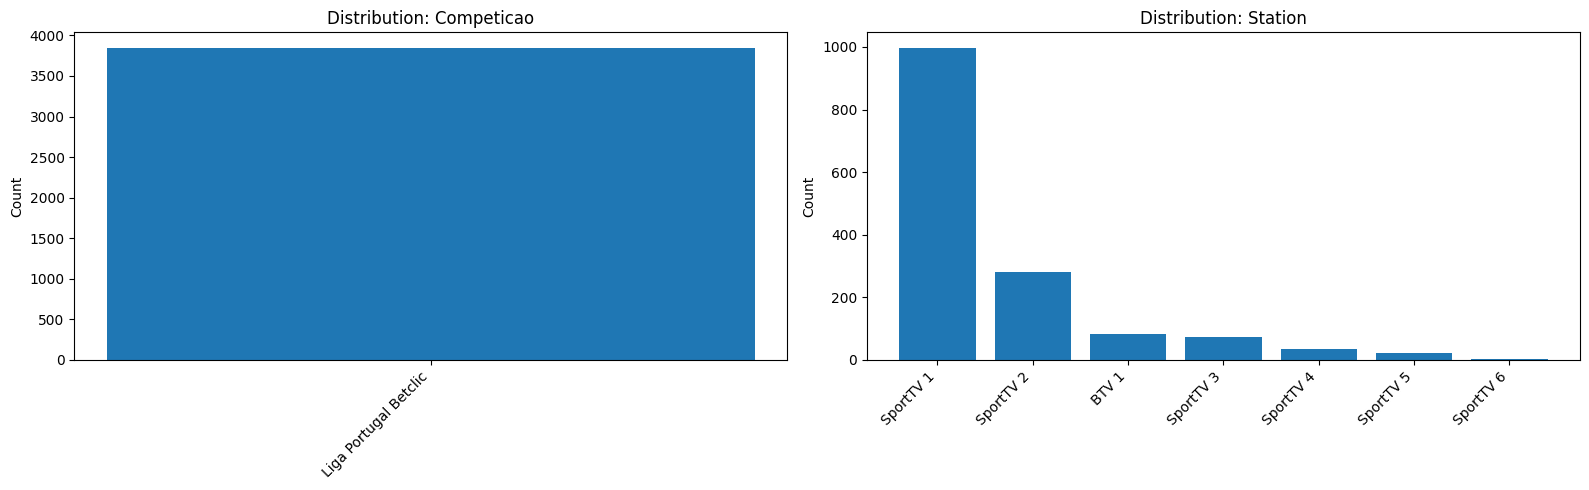


Liga Portugal Meu Super Data Summary:
QUICK DATA SUMMARY
Shape: (4921, 13)
Memory usage: 2.84 MB

Data Types:
object             10
float64             1
timedelta64[ns]     1
int64               1
Name: count, dtype: int64

Missing Values:
         Missing Count  Missing %
Station           3575  72.647836
Rat               3575  72.647836
Shr               3575  72.647836
Rch               3575  72.647836

Numeric Columns Summary:
           Jornada                       Hora   Espetadores
count  4921.000000                       4921   4921.000000
mean     19.903068  0 days 15:16:32.956716114    987.255842
std      11.679448  0 days 02:16:01.252338438   1095.011395
min       1.000000            0 days 10:15:00      0.000000
25%      10.000000            0 days 15:00:00    410.000000
50%      19.000000            0 days 15:30:00    681.000000
75%      29.000000            0 days 16:00:00   1137.000000
max      46.000000            0 days 21:15:00  20446.000000

Generating explorator

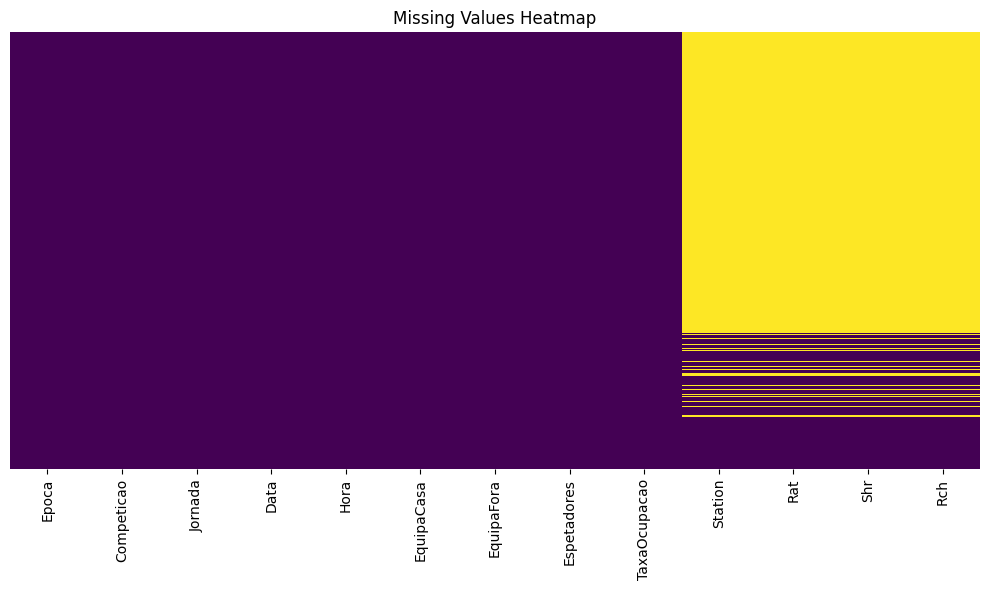

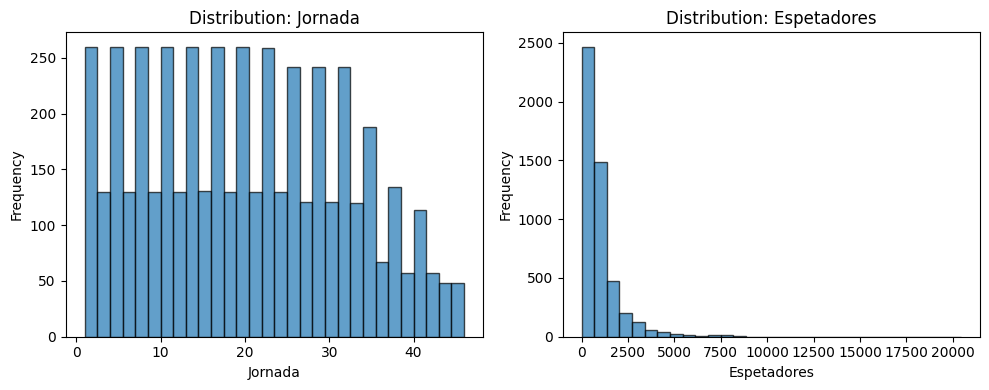

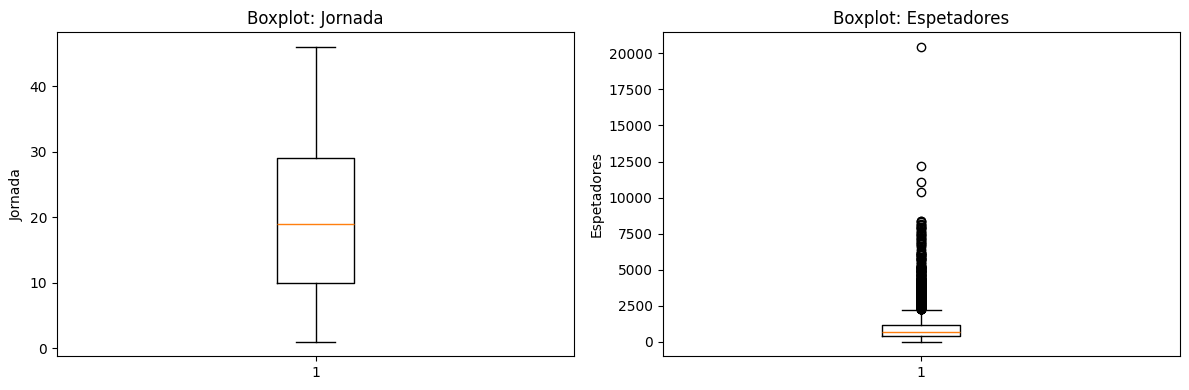

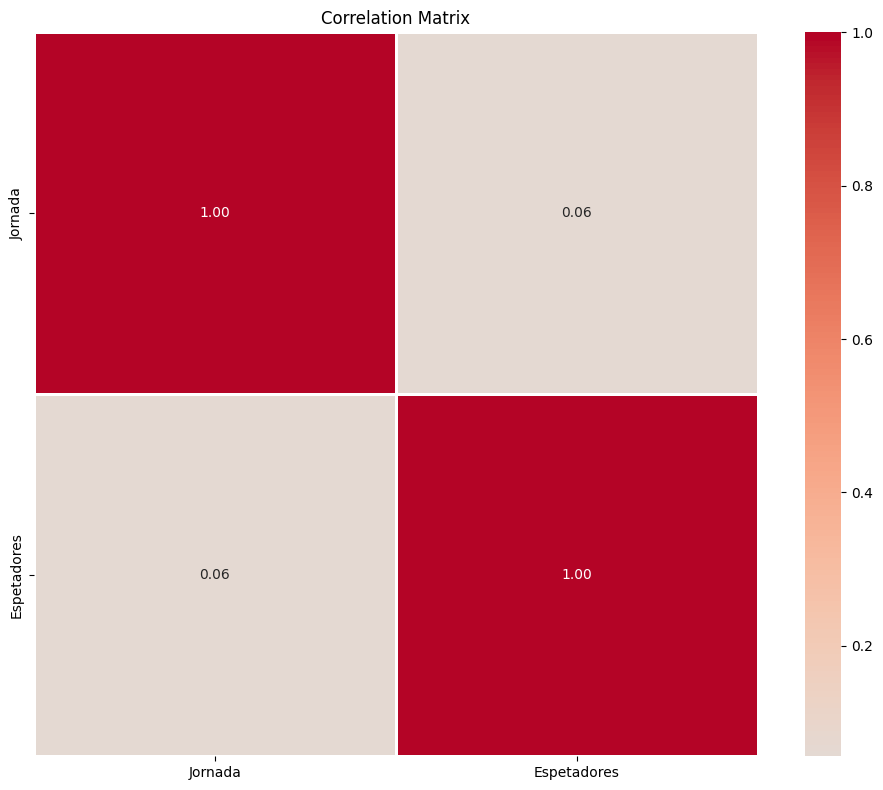


'Hora' appears to be time of day


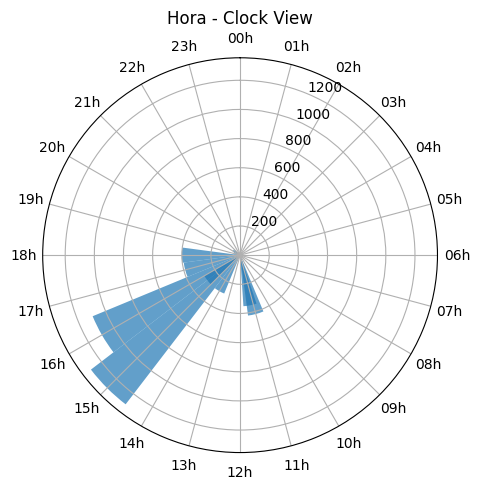

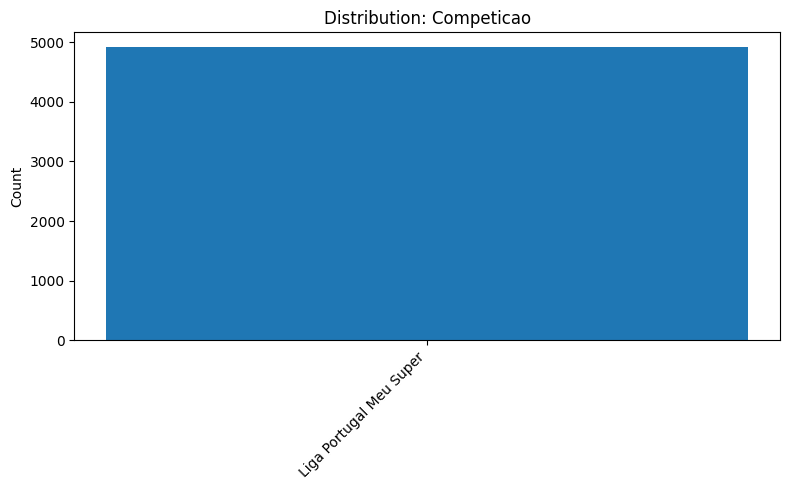

In [ ]:
if df_merged is not None and not df_merged.empty:
    for competicao in sorted(df_merged['Competicao'].unique()):
        df_competicao = df_merged[df_merged['Competicao'] == competicao]
        print(f"\n{competicao} Data Summary:")
        da.quick_summary(df_competicao)

## Data cleaning
---

In [ ]:
if df_merged is not None and not df_merged.empty:
    df_merged_copy = df_merged.copy()

    # Replace NaN values represented as None or 'None' with actual np.nan, adding consistency to missing data representation
    dc.replace_nan_values(df_merged_copy, [None, 'None'])

    # Change from CamelCase to snake_case column names
    df_merged_copy.columns = [dc.camel_to_snake(col) for col in df_merged_copy.columns]

    # Rename columns to English
    df_merged_copy.rename(
        columns={
            'epoca': 'season',
            'competicao': 'league',
            'jornada': 'round',
            'equipa_casa': 'home_team',
            'equipa_fora': 'away_team',
            'taxa_ocupacao': 'attendance_rate',
            'espectadores': 'attendance'
        },
        inplace=True
    )

    # Convert numeric columns to float
    colunas_decimais = ['rat', 'shr', 'rch', 'attendance_rate']

    for col in colunas_decimais:
        # Create a lowercased variable name based on the original column name
        col_clean_name = col + "_clean"
        df_merged_copy[col_clean_name] = df_merged_copy[col].apply(dc.convert_to_float)

    # Convert occupancy rate to decimal (divided by 100)
    df_merged_copy['attendance_rate'] = df_merged_copy['attendance_rate_clean'].div(100)

    
    # Convert to integer where possible, keeping NaN
    df_merged_copy['round'] = (
        pd.to_numeric(df_merged_copy['round'], errors='coerce')
        .astype('Int64')
    )
    df_merged_copy['attendance'] = (
        pd.to_numeric(df_merged_copy['espetadores'], errors='coerce')
        .astype('Int64')
    )



    # Create cleaned version of text columns: remove diacritics, convert to lowercase, normalize spaces
    colunas_texto = ['season', 'home_team', 'away_team', 'league', 'station']

    for col in colunas_texto:
        # Create a minimized variable name based on the original column name
        col_clean_name = col + "_clean"
        
        df_merged_copy[col_clean_name] = dc.clean_text_series(
            df_merged_copy[col],
            remove_diacritics=True,
            to_lowercase=True,
            normalize_spaces=True
        )

    df_merged_copy['season'] = df_merged_copy['season_clean']

    # Combine 'Data' and 'Hora' into a single column and convert to datetime
    df_merged_copy['hour'] = dc.timedelta_series_to_time(df_merged_copy['hora'])

    df_merged_copy['text_hour'] = pd.to_datetime(
        df_merged_copy['hour'],
        format='%H:%M:%S',
        errors='coerce'
    ).dt.strftime('%H:%M:%S')

    # Combine the 'Data' column (which is datetime.date) with the 'Hora' string
    # The 'Data' column is automatically converted to string by pandas.
    df_merged_copy['date_time'] = df_merged_copy['data'].astype(str) + ' ' + df_merged_copy['text_hour']

    # Convert the new column to datetime
    df_merged_copy['date_time'] = pd.to_datetime(
        df_merged_copy['date_time'],
        format='%Y-%m-%d %H:%M:%S',
        errors='coerce',
        utc=True
    )

    
    # Remove unnecessary columns
    colunas = ['attendance_rate_clean', 'season_clean', 'text_hour', 'rat', 'shr', 'rch', 'station',\
               'data', 'hour', 'competicao_clean', 'espetadores', 'hora']
    for col in colunas:
        df_merged_copy.drop(col, axis=1, inplace=True, errors='ignore')


    print("\nCleaned DataFrame preview:")
    if df_merged_copy is not None and not df_merged_copy.empty:
        for competicao in sorted(df_merged_copy['league'].unique()):
            df_competicao = df_merged_copy[df_merged_copy['league'] == competicao]
            print(f"\n{competicao} Data Preview:")
            display(df_competicao.head(5))


Cleaned DataFrame preview:

Allianz Cup Data Preview:


,season,league,round,home_team,away_team,attendance_rate,rat_clean,shr_clean,rch_clean,attendance,home_team_clean,away_team_clean,league_clean,station_clean,date_time
0,200708,Allianz Cup,<NA>,Sporting CP,Beira-Mar,0.0,NaN,NaN,NaN,6437,sporting_cp,beiramar,allianz_cup,none,2008-01-23 21:15:00+00:00
1,200708,Allianz Cup,<NA>,FC Penafiel,Vitória FC,0.0,NaN,NaN,NaN,517,fc_penafiel,vitoria_fc,allianz_cup,none,2008-01-23 19:00:00+00:00
2,200708,Allianz Cup,<NA>,Vitória FC,Beira-Mar,0.0,NaN,NaN,NaN,1988,vitoria_fc,beiramar,allianz_cup,none,2008-01-30 21:15:00+00:00
3,200708,Allianz Cup,<NA>,Sporting CP,FC Penafiel,0.0,NaN,NaN,NaN,7571,sporting_cp,fc_penafiel,allianz_cup,none,2008-01-30 19:00:00+00:00
4,200708,Allianz Cup,<NA>,Vitória FC,Sporting CP,0.0,NaN,NaN,NaN,5847,vitoria_fc,sporting_cp,allianz_cup,none,2008-01-09 21:15:00+00:00



Liga Portugal Betclic Data Preview:


,season,league,round,home_team,away_team,attendance_rate,rat_clean,shr_clean,rch_clean,attendance,home_team_clean,away_team_clean,league_clean,station_clean,date_time
359,201213,Liga Portugal Betclic,1,SC Olhanense,Estoril Praia,0.1566,NaN,NaN,NaN,1820,sc_olhanense,estoril_praia,liga_portugal_betclic,none,2012-08-17 20:15:00+00:00
360,201213,Liga Portugal Betclic,1,SL Benfica,SC Braga,0.8209,NaN,NaN,NaN,53357,sl_benfica,sc_braga,liga_portugal_betclic,none,2012-08-18 20:15:00+00:00
361,201213,Liga Portugal Betclic,1,Rio Ave FC,Marítimo M.,0.1152,NaN,NaN,NaN,1239,rio_ave_fc,maritimo_m,liga_portugal_betclic,none,2012-08-18 18:14:00+00:00
362,201213,Liga Portugal Betclic,1,Gil Vicente FC,FC Porto,0.6915,NaN,NaN,NaN,8298,gil_vicente_fc,fc_porto,liga_portugal_betclic,none,2012-08-19 18:14:00+00:00
363,201213,Liga Portugal Betclic,1,FC P.Ferreira,Moreirense FC,0.2361,NaN,NaN,NaN,1221,fc_pferreira,moreirense_fc,liga_portugal_betclic,none,2012-08-19 18:00:00+00:00



Liga Portugal Meu Super Data Preview:


,season,league,round,home_team,away_team,attendance_rate,rat_clean,shr_clean,rch_clean,attendance,home_team_clean,away_team_clean,league_clean,station_clean,date_time
348,201213,Liga Portugal Meu Super,1,Portimonense,FC Arouca,0.1595,NaN,NaN,NaN,995,portimonense,fc_arouca,liga_portugal_meu_super,none,2012-08-11 17:00:00+00:00
349,201213,Liga Portugal Meu Super,1,U. Madeira,SC Freamunde,0.0725,NaN,NaN,NaN,372,u_madeira,sc_freamunde,liga_portugal_meu_super,none,2012-08-11 16:00:00+00:00
350,201213,Liga Portugal Meu Super,1,CD Aves,CD Trofense,0.1090,NaN,NaN,NaN,458,cd_aves,cd_trofense,liga_portugal_meu_super,none,2012-08-11 17:00:00+00:00
351,201213,Liga Portugal Meu Super,1,CD Tondela,FC Porto B,0.3910,NaN,NaN,NaN,1173,cd_tondela,fc_porto_b,liga_portugal_meu_super,none,2012-08-12 11:15:00+00:00
352,201213,Liga Portugal Meu Super,1,FC Penafiel,Atlético CP,0.1192,NaN,NaN,NaN,545,fc_penafiel,atletico_cp,liga_portugal_meu_super,none,2012-08-12 18:00:00+00:00


In [ ]:

if df_merged_copy is not None and not df_merged_copy.empty:
    # Check if we have duplicated records for the same match, based on key columns
    # Aggregate duplicated records by summing numeric columns
    keys = [
        'league_clean', 'season', 'round',
        'home_team_clean', 'away_team_clean'
    ]

    aggregations = {
        'date_time': ('date_time', 'first'),
        'attendance': ('attendance', 'sum'),
        'attendance_rate': ('attendance_rate', 'sum'),
        'rat_clean': ('rat_clean', 'sum'),
        'shr_clean': ('shr_clean', 'sum'),
        'rch_clean': ('rch_clean', 'sum')
    }

    df_merged_grouped = dc.group_dynamic(df_merged_copy, keys, aggregations)

    print("\nGrouped DataFrame preview:")
    if df_merged_grouped is not None and not df_merged_grouped.empty:
        for competicao in sorted(df_merged_grouped['league'].unique()):
            df_competicao = df_merged_grouped[df_merged_grouped['league'] == competicao]
            print(f"\n{competicao} Data Preview:")
            display(df_competicao.head(5))

4 duplicates found. Applying grouping...
Grouping completed successfully.

Grouped DataFrame preview:

Allianz Cup Data Preview:


,league_clean,season,round,home_team_clean,away_team_clean,date_time,attendance,attendance_rate,rat_clean,shr_clean,rch_clean,league,home_team,away_team,station_clean
0,allianz_cup,200708,<NA>,beiramar,boavista_fc,2007-08-12 19:45:00+00:00,1218,0.0,0.0,0.0,0.0,Allianz Cup,Beira-Mar,Boavista FC,none
1,allianz_cup,200708,<NA>,beiramar,fc_penafiel,2008-01-09 19:30:00+00:00,404,0.0,0.0,0.0,0.0,Allianz Cup,Beira-Mar,FC Penafiel,none
2,allianz_cup,200708,<NA>,beiramar,fc_pferreira,2007-09-26 19:00:00+00:00,591,0.0,0.0,0.0,0.0,Allianz Cup,Beira-Mar,FC P.Ferreira,none
3,allianz_cup,200708,<NA>,beiramar,portimonense,2007-10-31 20:00:00+00:00,658,0.0,0.0,0.0,0.0,Allianz Cup,Beira-Mar,Portimonense,none
4,allianz_cup,200708,<NA>,cd_trofense,cd_feirense,2007-08-04 17:00:00+00:00,622,0.0,0.0,0.0,0.0,Allianz Cup,CD Trofense,CD Feirense,none



Liga Portugal Betclic Data Preview:


,league_clean,season,round,home_team_clean,away_team_clean,date_time,attendance,attendance_rate,rat_clean,shr_clean,rch_clean,league,home_team,away_team,station_clean
868,liga_portugal_betclic,201213,1,beiramar,a_academica,2012-08-20 20:15:00+00:00,2830,0.0943,0.0,0.0,0.0,Liga Portugal Betclic,Beira-Mar,A. Académica,none
869,liga_portugal_betclic,201213,1,cd_nacional,vitoria_fc,2012-08-19 16:00:00+00:00,1390,0.2708,0.0,0.0,0.0,Liga Portugal Betclic,CD Nacional,Vitória FC,none
870,liga_portugal_betclic,201213,1,fc_pferreira,moreirense_fc,2012-08-19 18:00:00+00:00,1221,0.2361,0.0,0.0,0.0,Liga Portugal Betclic,FC P.Ferreira,Moreirense FC,none
871,liga_portugal_betclic,201213,1,gil_vicente_fc,fc_porto,2012-08-19 18:14:00+00:00,8298,0.6915,0.0,0.0,0.0,Liga Portugal Betclic,Gil Vicente FC,FC Porto,none
872,liga_portugal_betclic,201213,1,rio_ave_fc,maritimo_m,2012-08-18 18:14:00+00:00,1239,0.1152,0.0,0.0,0.0,Liga Portugal Betclic,Rio Ave FC,Marítimo M.,none



Liga Portugal Meu Super Data Preview:


,league_clean,season,round,home_team_clean,away_team_clean,date_time,attendance,attendance_rate,rat_clean,shr_clean,rch_clean,league,home_team,away_team,station_clean
4714,liga_portugal_meu_super,201213,1,belenenses,cd_feirense,2012-08-12 16:00:00+00:00,1145,0.0908,0.0,0.0,0.0,Liga Portugal Meu Super,Belenenses,CD Feirense,none
4715,liga_portugal_meu_super,201213,1,cd_aves,cd_trofense,2012-08-11 17:00:00+00:00,458,0.1090,0.0,0.0,0.0,Liga Portugal Meu Super,CD Aves,CD Trofense,none
4716,liga_portugal_meu_super,201213,1,cd_tondela,fc_porto_b,2012-08-12 11:15:00+00:00,1173,0.3910,0.0,0.0,0.0,Liga Portugal Meu Super,CD Tondela,FC Porto B,none
4717,liga_portugal_meu_super,201213,1,fc_penafiel,atletico_cp,2012-08-12 18:00:00+00:00,545,0.1192,0.0,0.0,0.0,Liga Portugal Meu Super,FC Penafiel,Atlético CP,none
4718,liga_portugal_meu_super,201213,1,leixoes_sc,maritimo_m_b,2012-08-12 17:00:00+00:00,1041,0.1096,0.0,0.0,0.0,Liga Portugal Meu Super,Leixões SC,Marítimo M. B,none


In [ ]:
if df_merged_grouped is not None and not df_merged_grouped.empty:
    # Create date/time features and weekday name
    df_merged_grouped['weekday_name'] = pd.to_datetime(
        df_merged_grouped['date_time'],
        format='%Y-%m-%d %H:%M:%S',
        errors='coerce'
    ).dt.day_name()

    df_merged_grouped['weekday_num'] = pd.to_datetime(
        df_merged_grouped['date_time'],
        format='%Y-%m-%d %H:%M:%S',
        errors='coerce'
    ).dt.weekday.astype('Int64')

    df_merged_grouped['hour'] = pd.to_datetime(
        df_merged_grouped['date_time'],
        format='%Y-%m-%d %H:%M:%S',
        errors='coerce'
    ).dt.time

    df_merged_grouped['date'] = pd.to_datetime(
        df_merged_grouped['date_time'],
        format='%Y-%m-%d %H:%M:%S',
        errors='coerce'
    ).dt.date

    display(df_merged_grouped)

    # Free memory
    del df_merged
    del df_merged_copy


,league_clean,season,round,home_team_clean,away_team_clean,date_time,attendance,attendance_rate,rat_clean,shr_clean,rch_clean,league,home_team,away_team,station_clean,weekday_name,weekday_num,hour,date
0,allianz_cup,200708,<NA>,beiramar,boavista_fc,2007-08-12 19:45:00+00:00,1218,0.0000,0.0,0.00,0.00,Allianz Cup,Beira-Mar,Boavista FC,none,Sunday,6,19:45:00,2007-08-12
1,allianz_cup,200708,<NA>,beiramar,fc_penafiel,2008-01-09 19:30:00+00:00,404,0.0000,0.0,0.00,0.00,Allianz Cup,Beira-Mar,FC Penafiel,none,Wednesday,2,19:30:00,2008-01-09
2,allianz_cup,200708,<NA>,beiramar,fc_pferreira,2007-09-26 19:00:00+00:00,591,0.0000,0.0,0.00,0.00,Allianz Cup,Beira-Mar,FC P.Ferreira,none,Wednesday,2,19:00:00,2007-09-26
3,allianz_cup,200708,<NA>,beiramar,portimonense,2007-10-31 20:00:00+00:00,658,0.0000,0.0,0.00,0.00,Allianz Cup,Beira-Mar,Portimonense,none,Wednesday,2,20:00:00,2007-10-31
4,allianz_cup,200708,<NA>,cd_trofense,cd_feirense,2007-08-04 17:00:00+00:00,622,0.0000,0.0,0.00,0.00,Allianz Cup,CD Trofense,CD Feirense,none,Saturday,5,17:00:00,2007-08-04
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9629,liga_portugal_meu_super,202425,34,fc_penafiel,gd_chaves,2025-05-15 18:45:00+00:00,556,0.1044,4090.0,0.99,2.67,Liga Portugal Meu Super,FC Penafiel,GD Chaves,sporttv_,Thursday,3,18:45:00,2025-05-15
9630,liga_portugal_meu_super,202425,34,fc_porto_b,sl_benfica_b,2025-05-17 11:00:00+00:00,698,0.2140,1318.0,0.54,0.82,Liga Portugal Meu Super,FC Porto B,SL Benfica B,porto_canal,Saturday,5,11:00:00,2025-05-17
9631,liga_portugal_meu_super,202425,34,leixoes_sc,cd_feirense,2025-05-14 20:15:00+00:00,1543,0.2953,3711.0,0.76,2.51,Liga Portugal Meu Super,Leixões SC,CD Feirense,sporttv_,Wednesday,2,20:15:00,2025-05-14
9632,liga_portugal_meu_super,202425,34,maritimo_m,fc_vizela,2025-05-16 20:30:00+00:00,6102,0.5776,1191.0,0.26,0.95,Liga Portugal Meu Super,Marítimo M.,FC Vizela,sporttv_2,Friday,4,20:30:00,2025-05-16



Allianz Cup Data Summary:
QUICK DATA SUMMARY
Shape: (868, 19)
Memory usage: 0.58 MB

Data Types:
object                 11
float64                 4
Int64                   3
datetime64[ns, UTC]     1
Name: count, dtype: int64

Missing Values:
              Missing Count   Missing %
round                   868  100.000000
date_time                20    2.304147
weekday_name             20    2.304147
weekday_num              20    2.304147
hour                     20    2.304147
date                     20    2.304147

Numeric Columns Summary:
       round   attendance  attendance_rate  rat_clean  shr_clean  rch_clean  \
count    0.0        868.0            868.0      868.0      868.0      868.0   
mean    <NA>  3879.813364              0.0        0.0        0.0        0.0   
std     <NA>  7375.064521              0.0        0.0        0.0        0.0   
min     <NA>          0.0              0.0        0.0        0.0        0.0   
25%     <NA>        460.5              0.0        0.0 

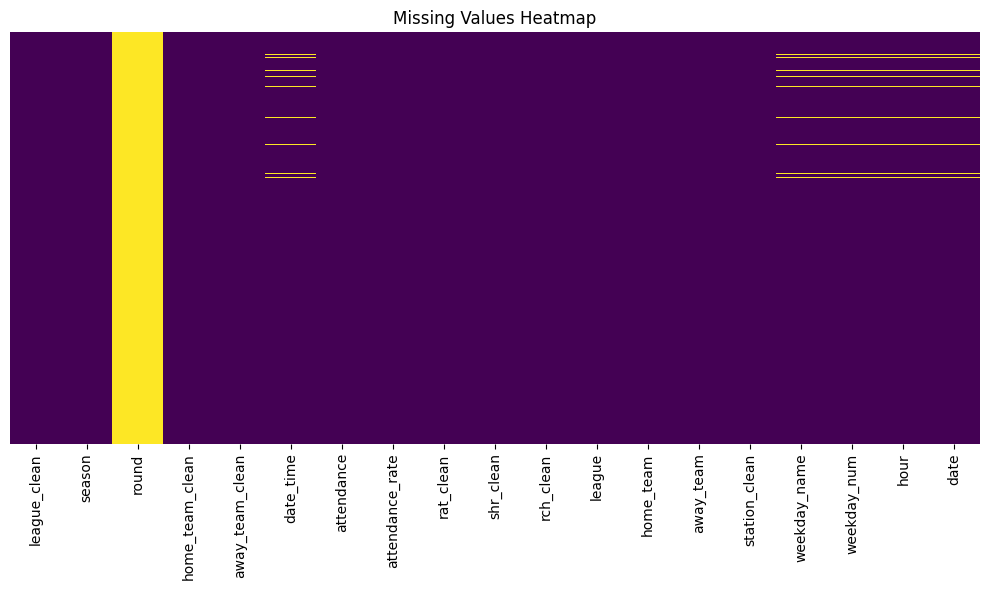

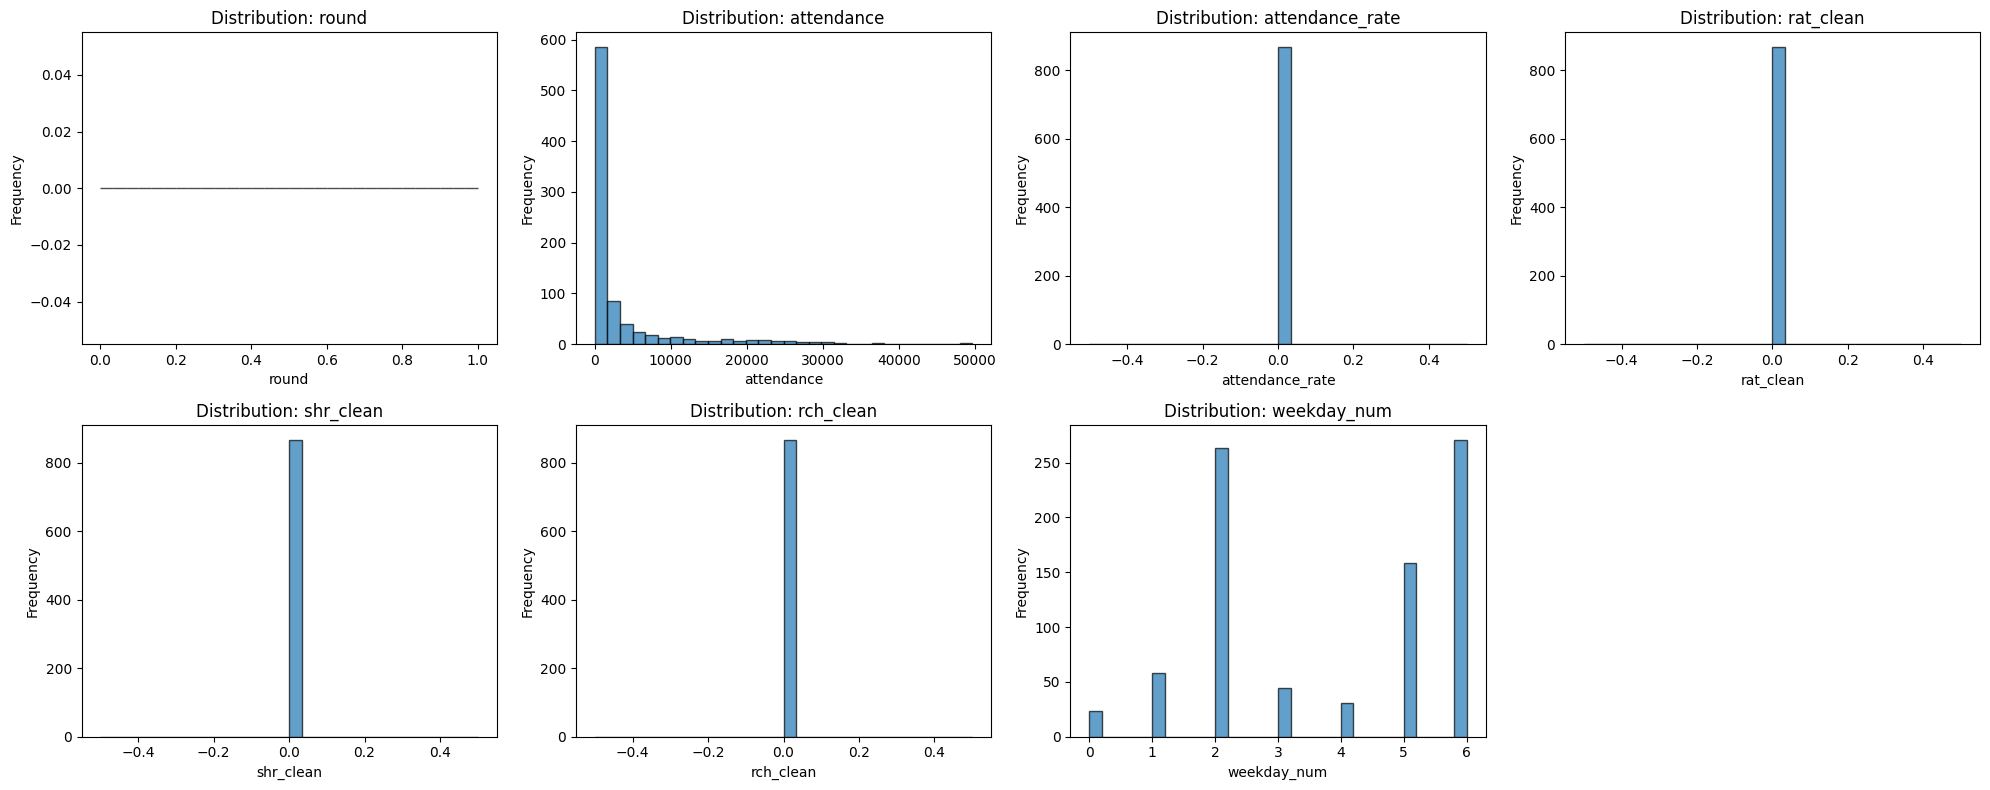

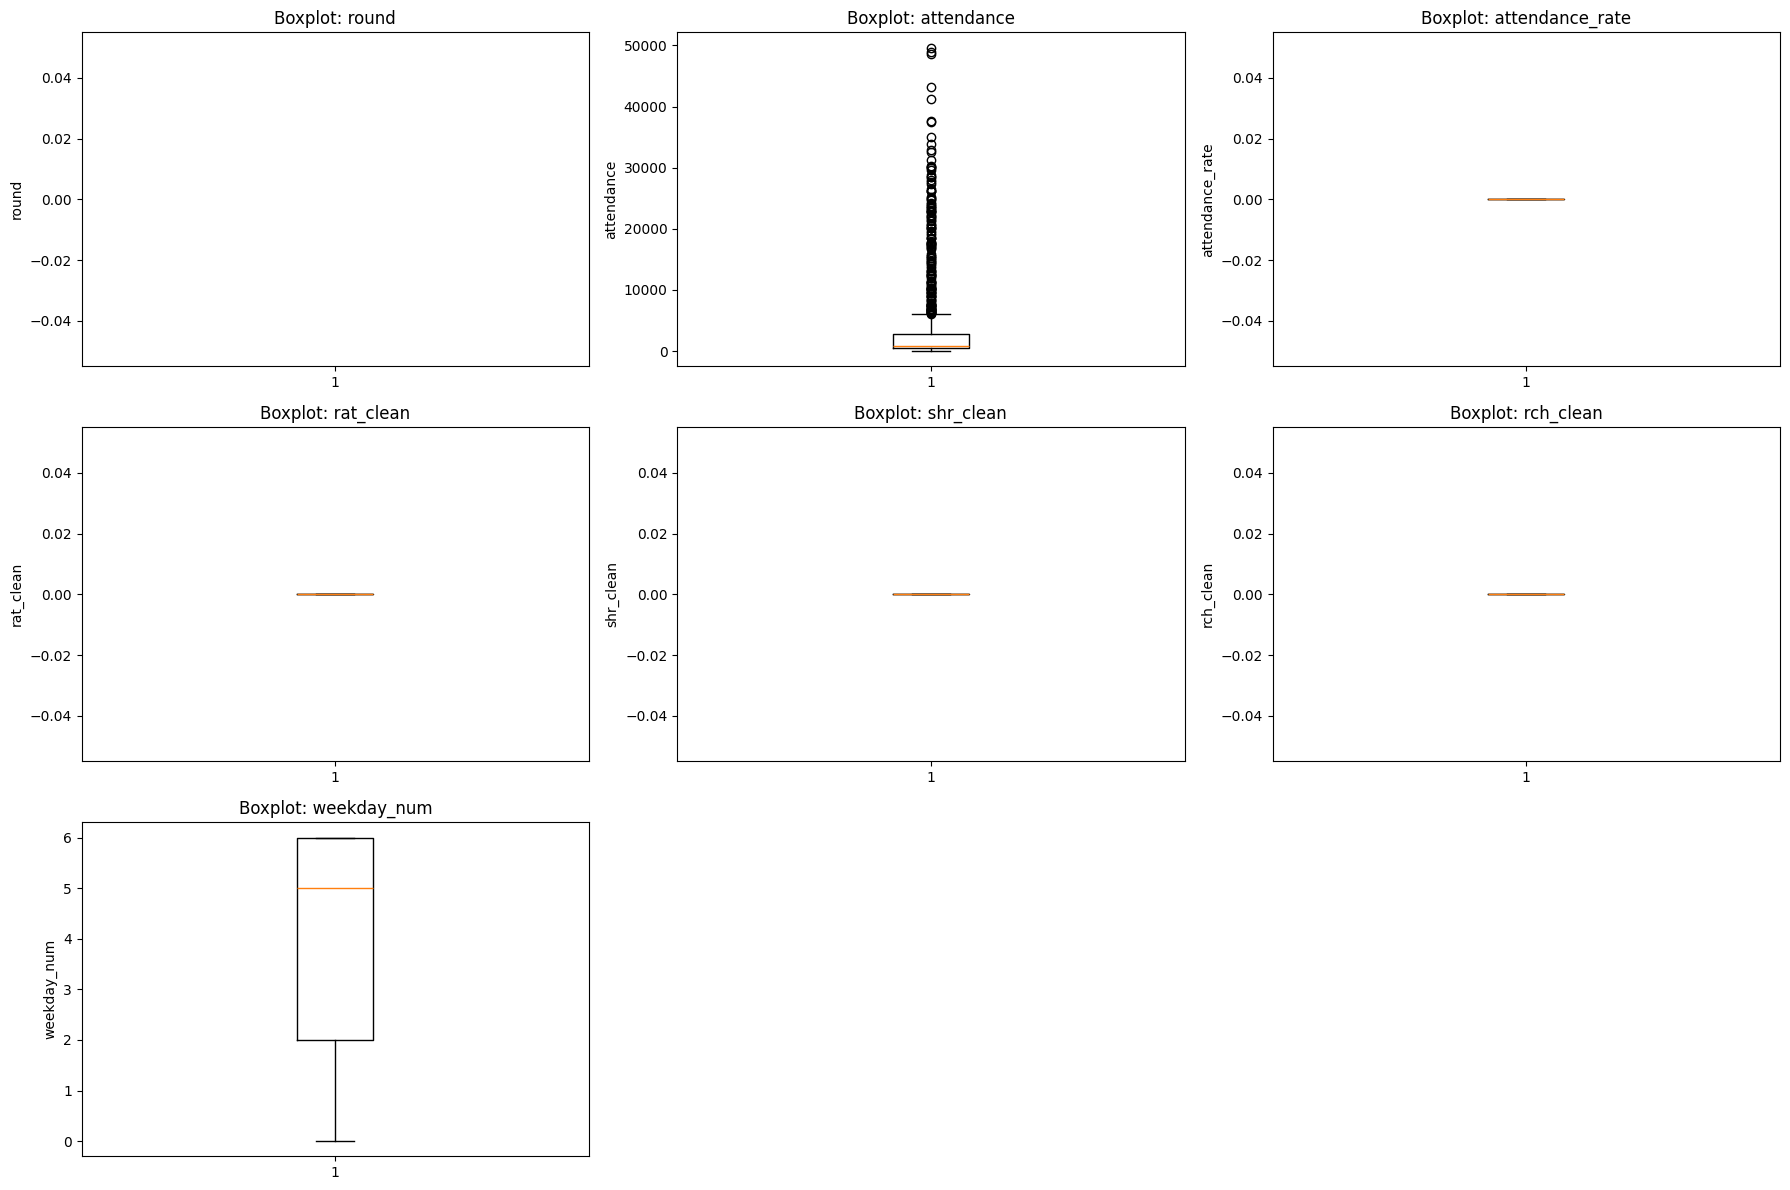

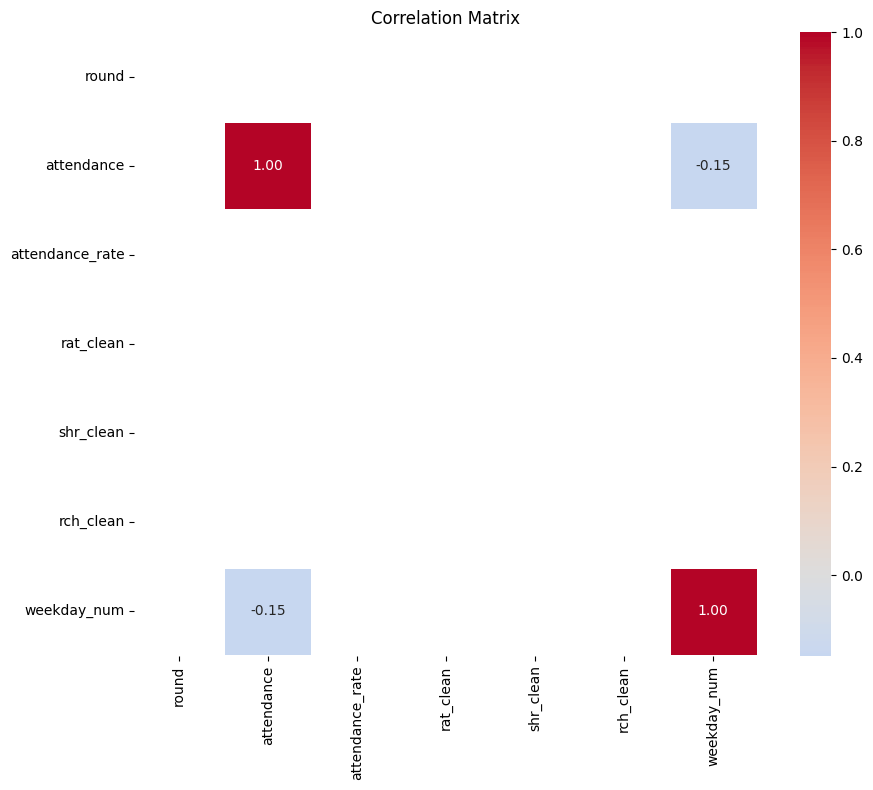

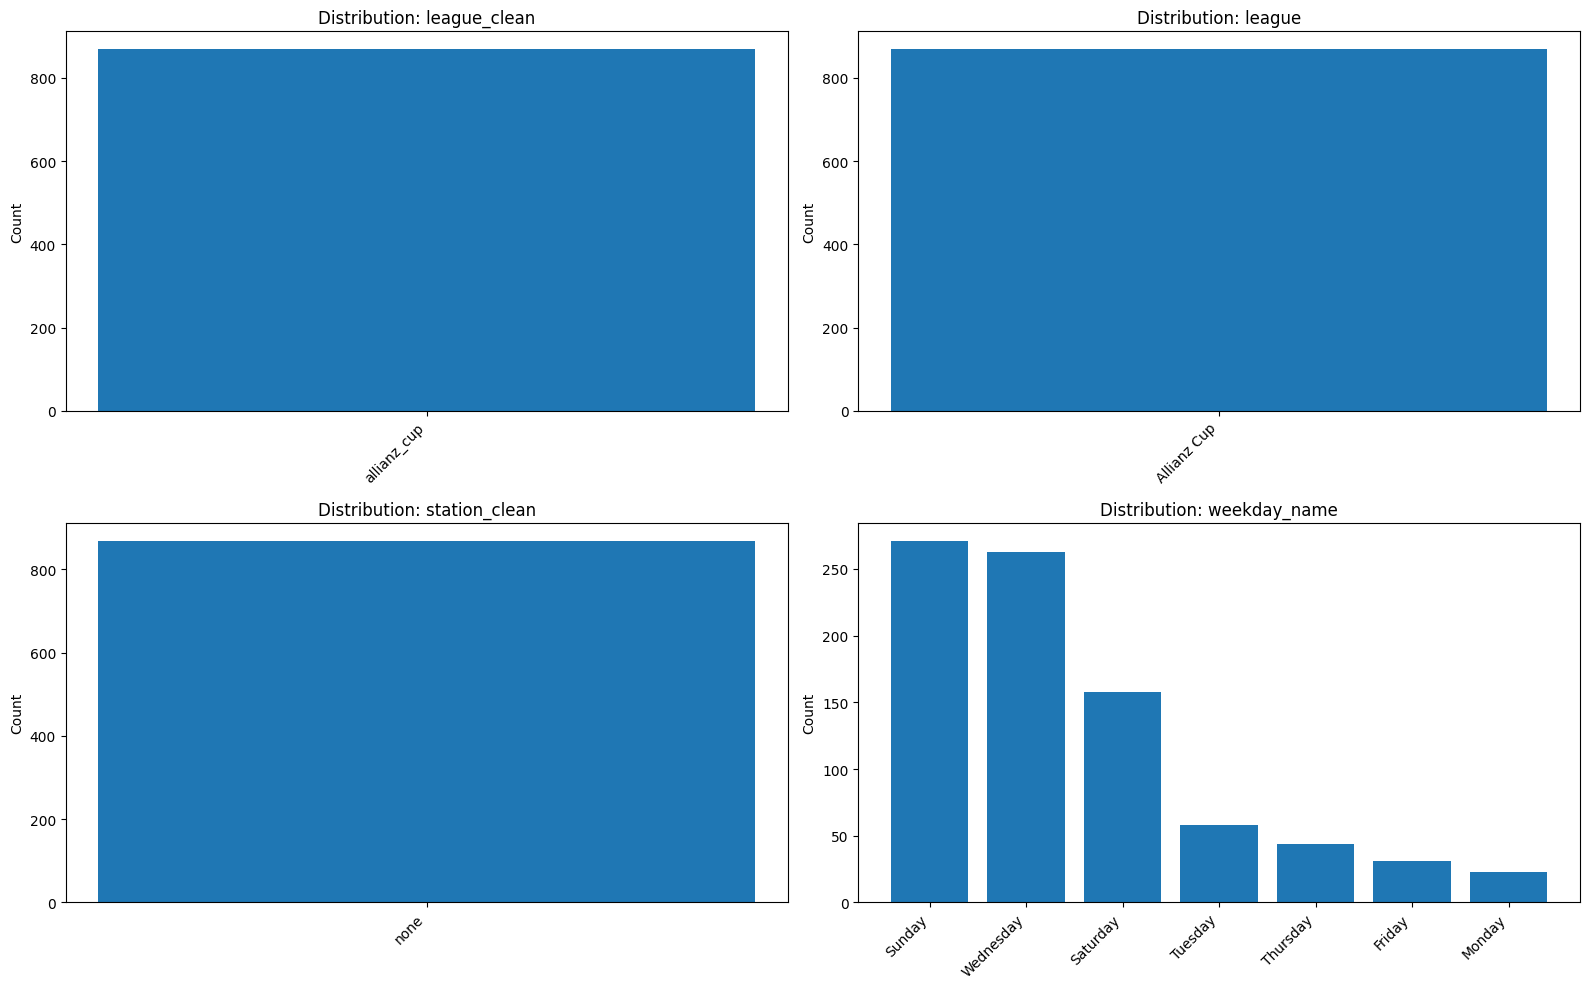


Liga Portugal Betclic Data Summary:
QUICK DATA SUMMARY
Shape: (3846, 19)
Memory usage: 2.63 MB

Data Types:
object                 11
float64                 4
Int64                   3
datetime64[ns, UTC]     1
Name: count, dtype: int64

Missing Values:
Empty DataFrame
Columns: [Missing Count, Missing %]
Index: []

Numeric Columns Summary:
          round    attendance  attendance_rate     rat_clean    shr_clean  \
count    3846.0        3846.0      3846.000000   3846.000000  3846.000000   
mean   17.25039   9838.526781         0.424928   3763.742590     0.851921   
std    9.697879  14523.292177         0.294343   8147.844861     1.794103   
min         1.0           0.0         0.000000      0.000000     0.000000   
25%         9.0        1643.0         0.187625      0.000000     0.000000   
50%        17.0        3411.5         0.378300      0.000000     0.000000   
75%        26.0       9688.75         0.649375   2921.750000     0.740000   
max        34.0       64591.0         1.

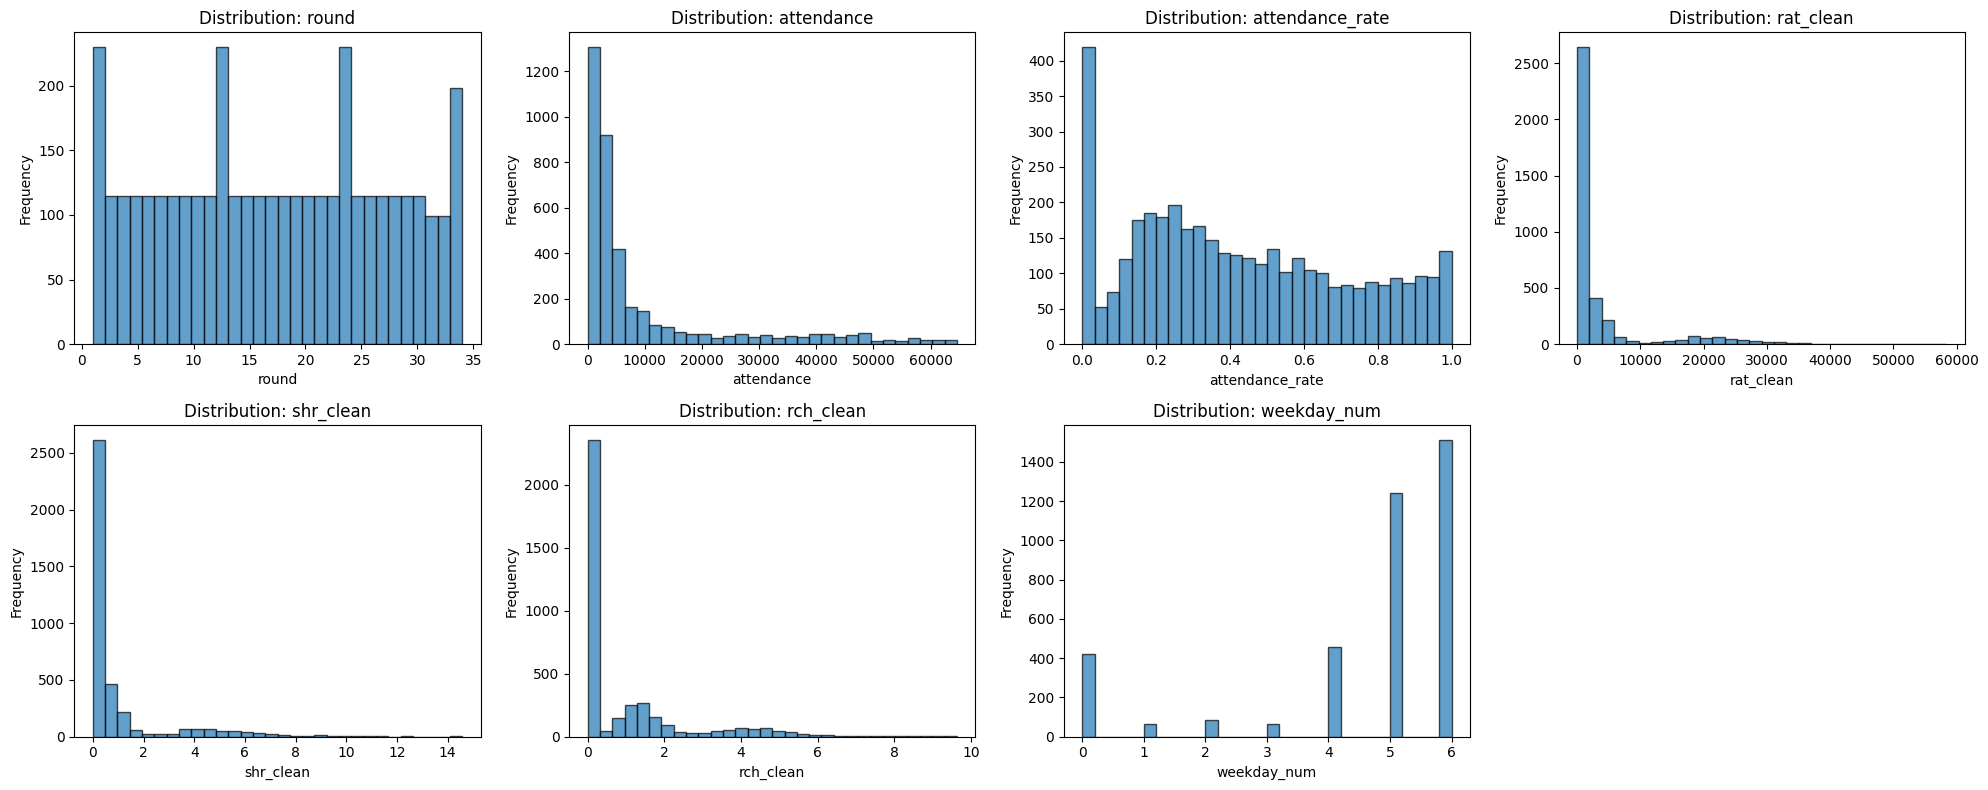

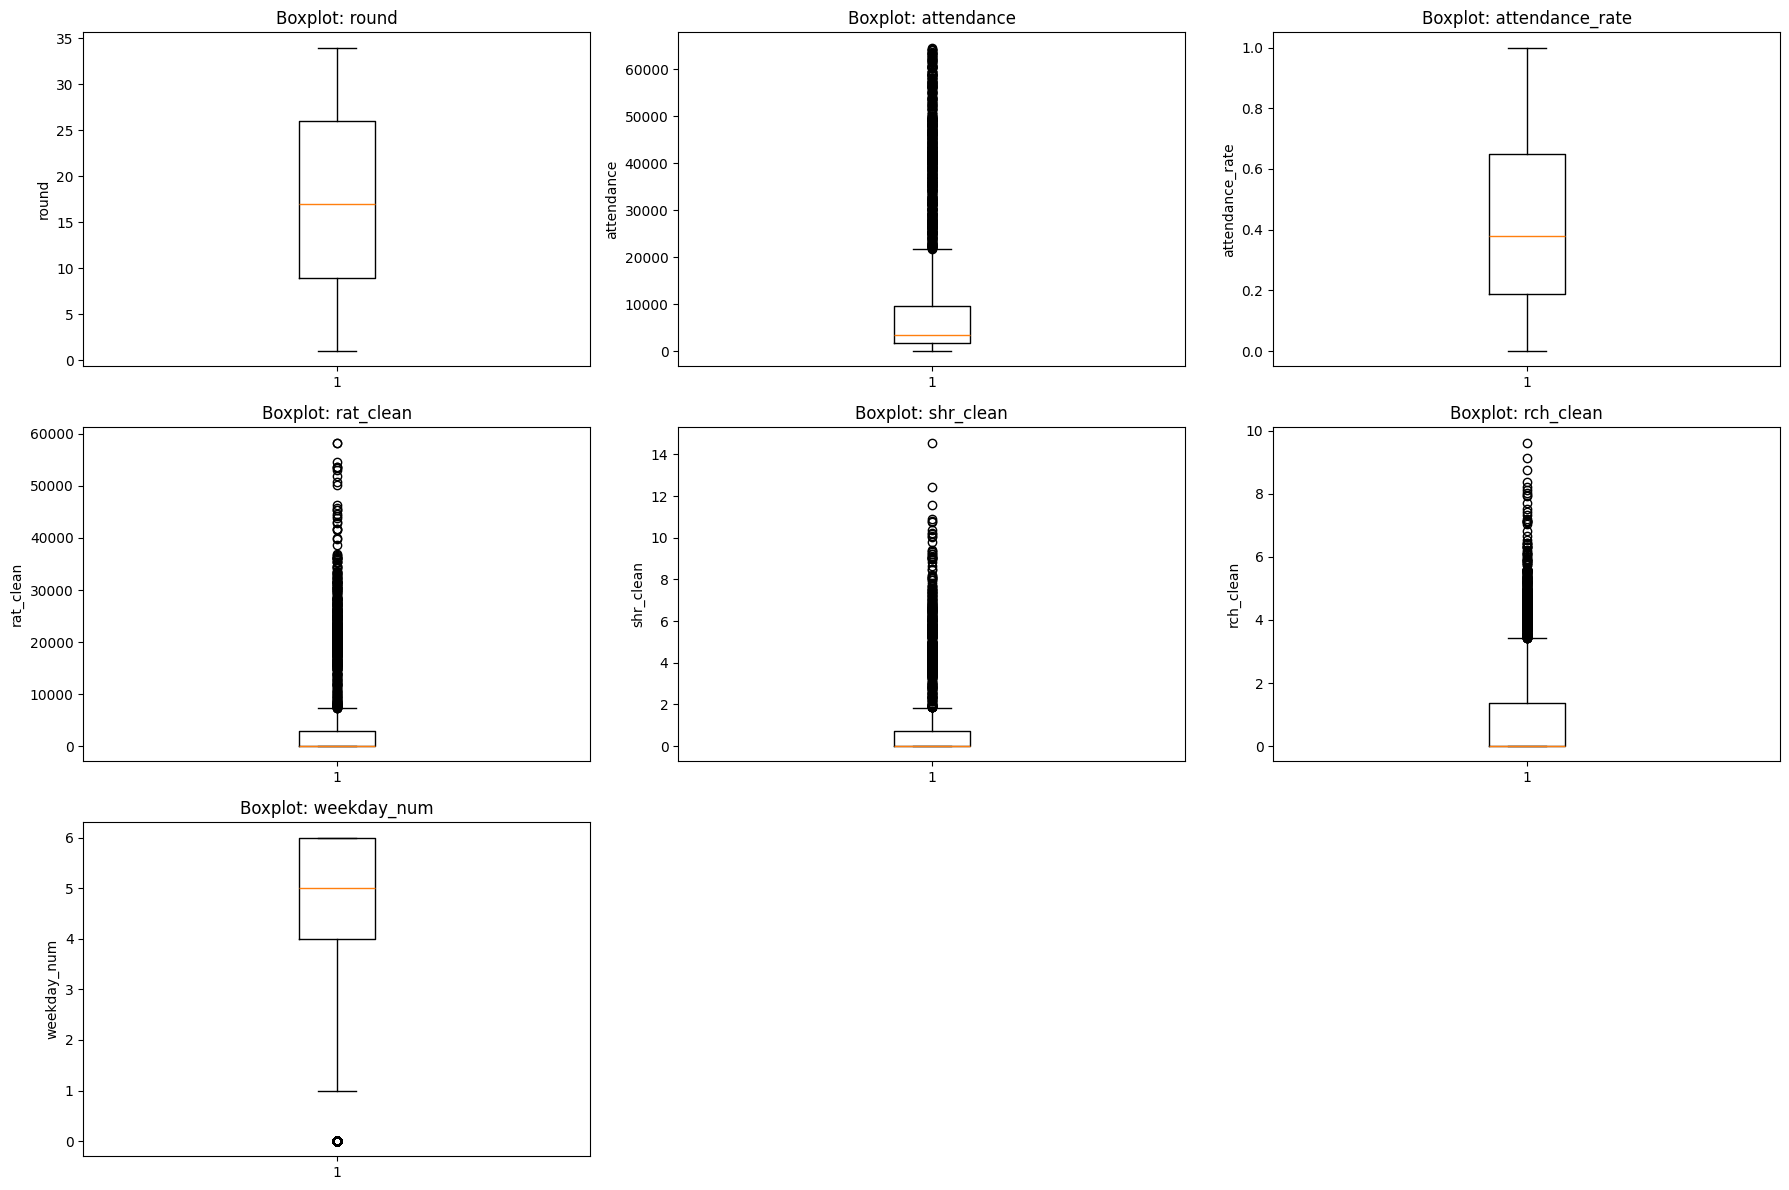

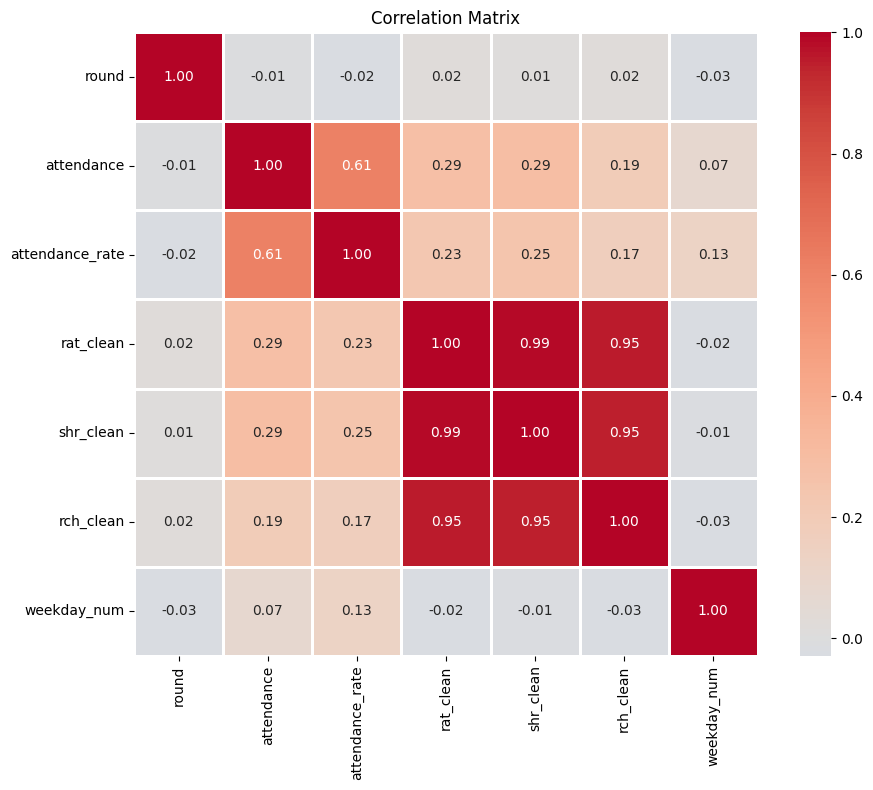

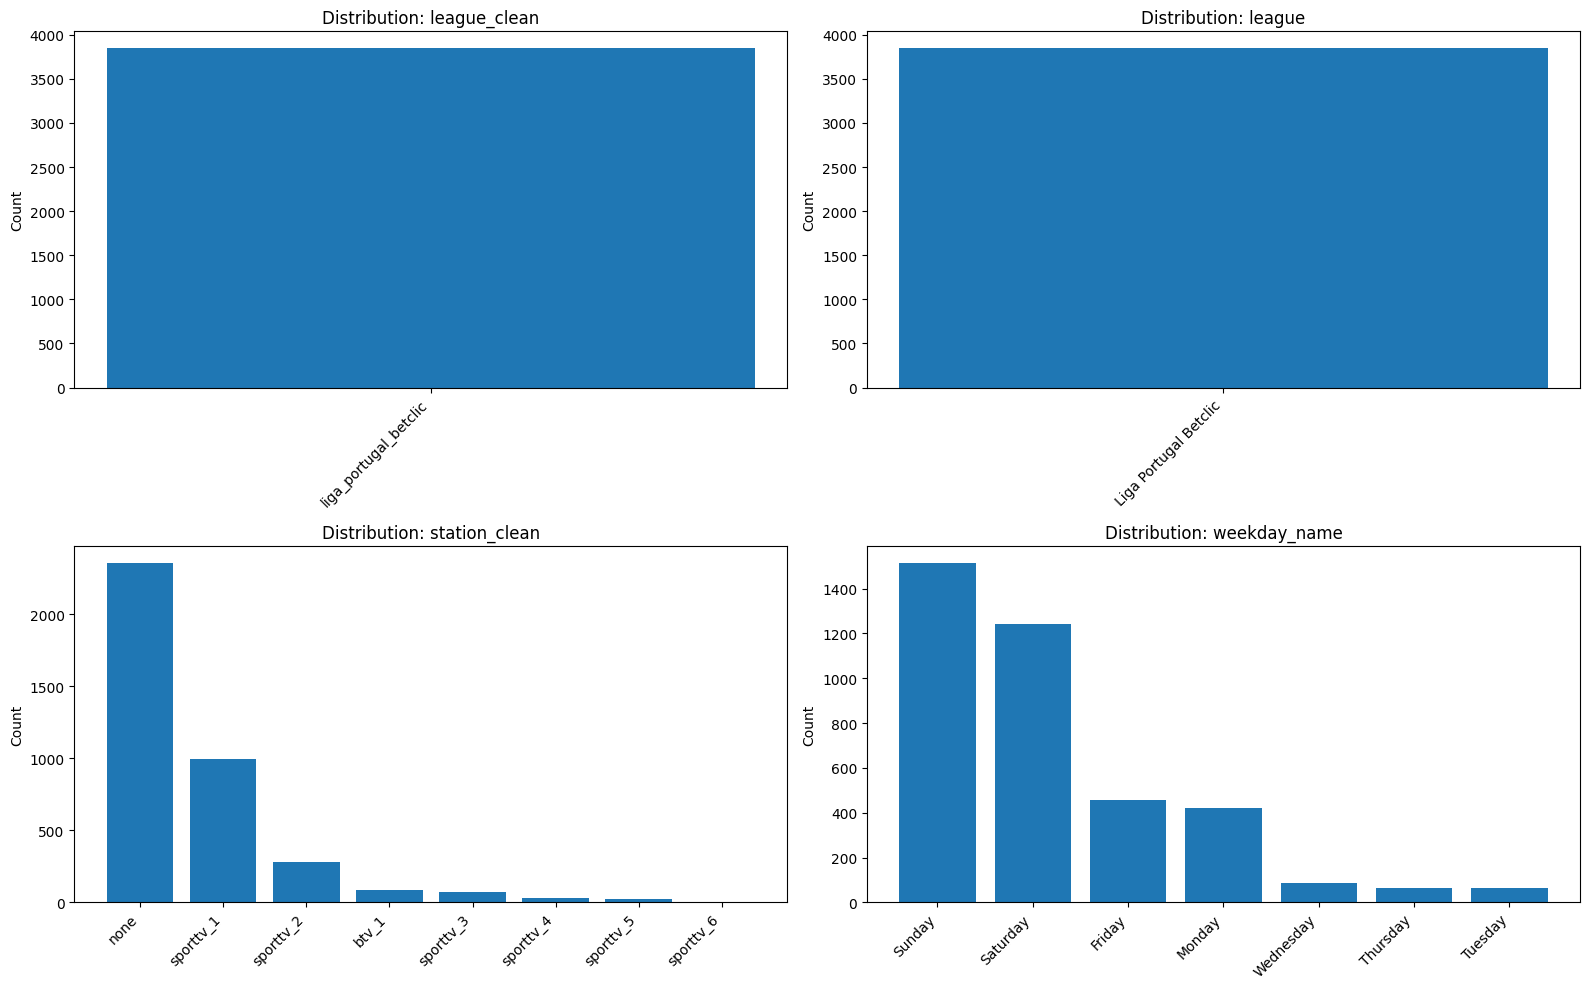


Liga Portugal Meu Super Data Summary:
QUICK DATA SUMMARY
Shape: (4920, 19)
Memory usage: 3.40 MB

Data Types:
object                 11
float64                 4
Int64                   3
datetime64[ns, UTC]     1
Name: count, dtype: int64

Missing Values:
Empty DataFrame
Columns: [Missing Count, Missing %]
Index: []

Numeric Columns Summary:
           round   attendance  attendance_rate     rat_clean    shr_clean  \
count     4920.0       4920.0      4920.000000   4920.000000  4920.000000   
mean   19.904065   987.456504         0.201724    622.271951     0.184075   
std    11.680426  1095.569866         0.179044   1393.877030     0.407600   
min          1.0          0.0         0.000000      0.000000     0.000000   
25%         10.0        410.0         0.080000      0.000000     0.000000   
50%         19.0        680.5         0.153150      0.000000     0.000000   
75%         29.0       1135.5         0.269525    217.500000     0.070000   
max         46.0      20446.0         

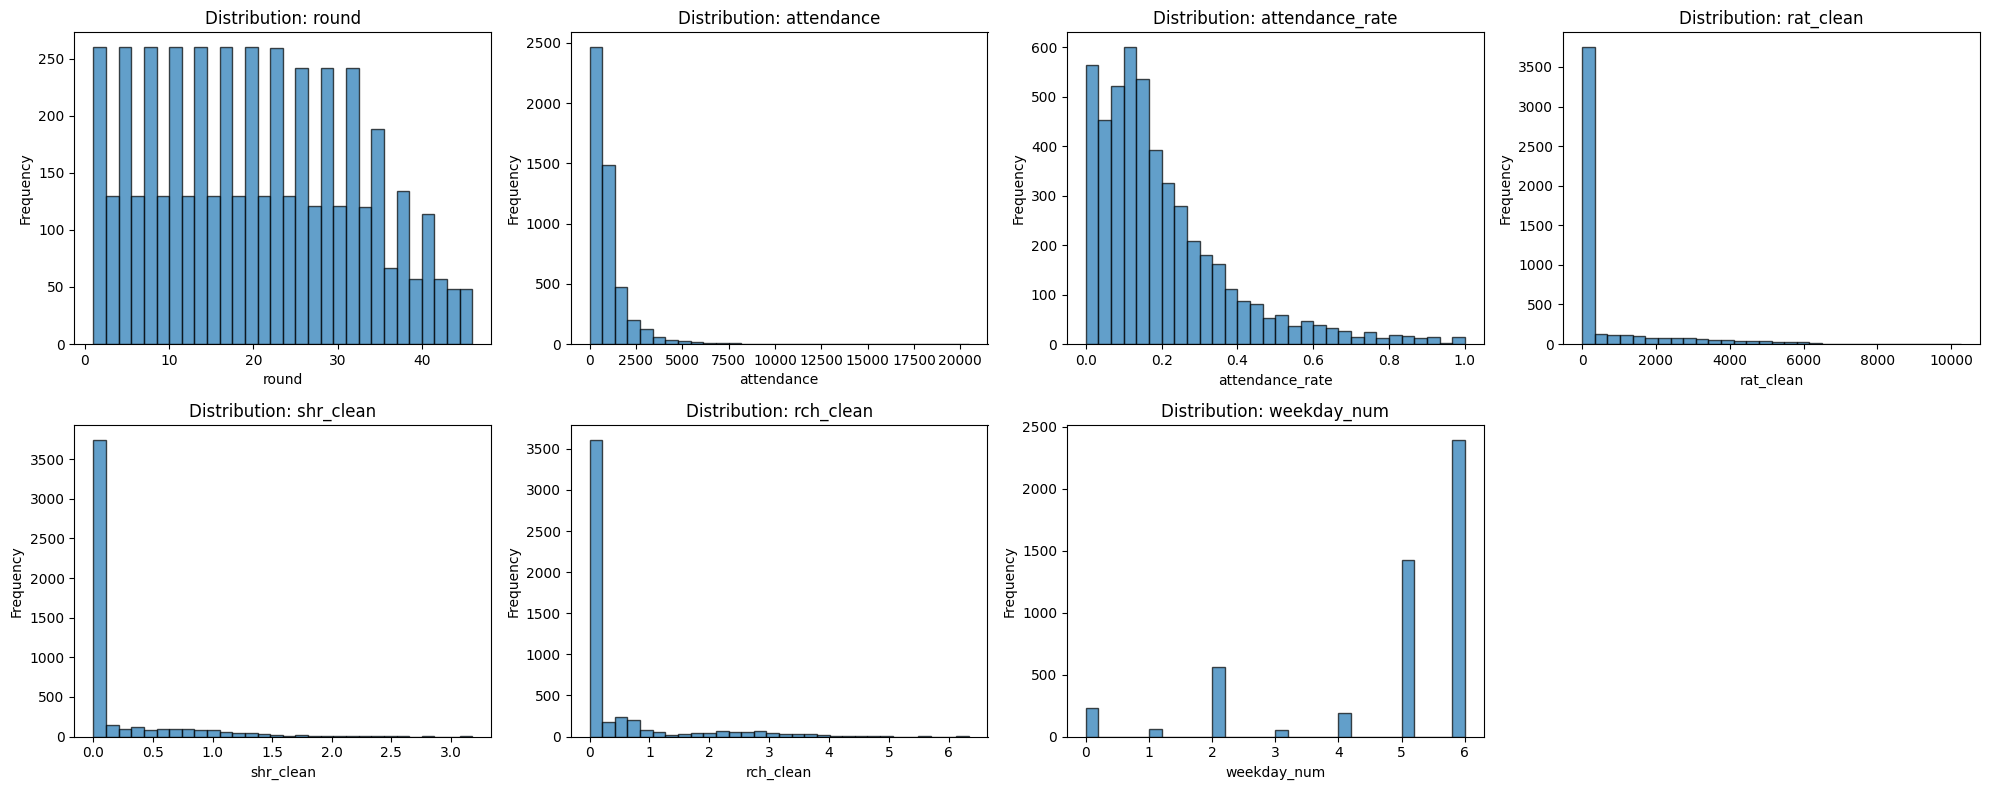

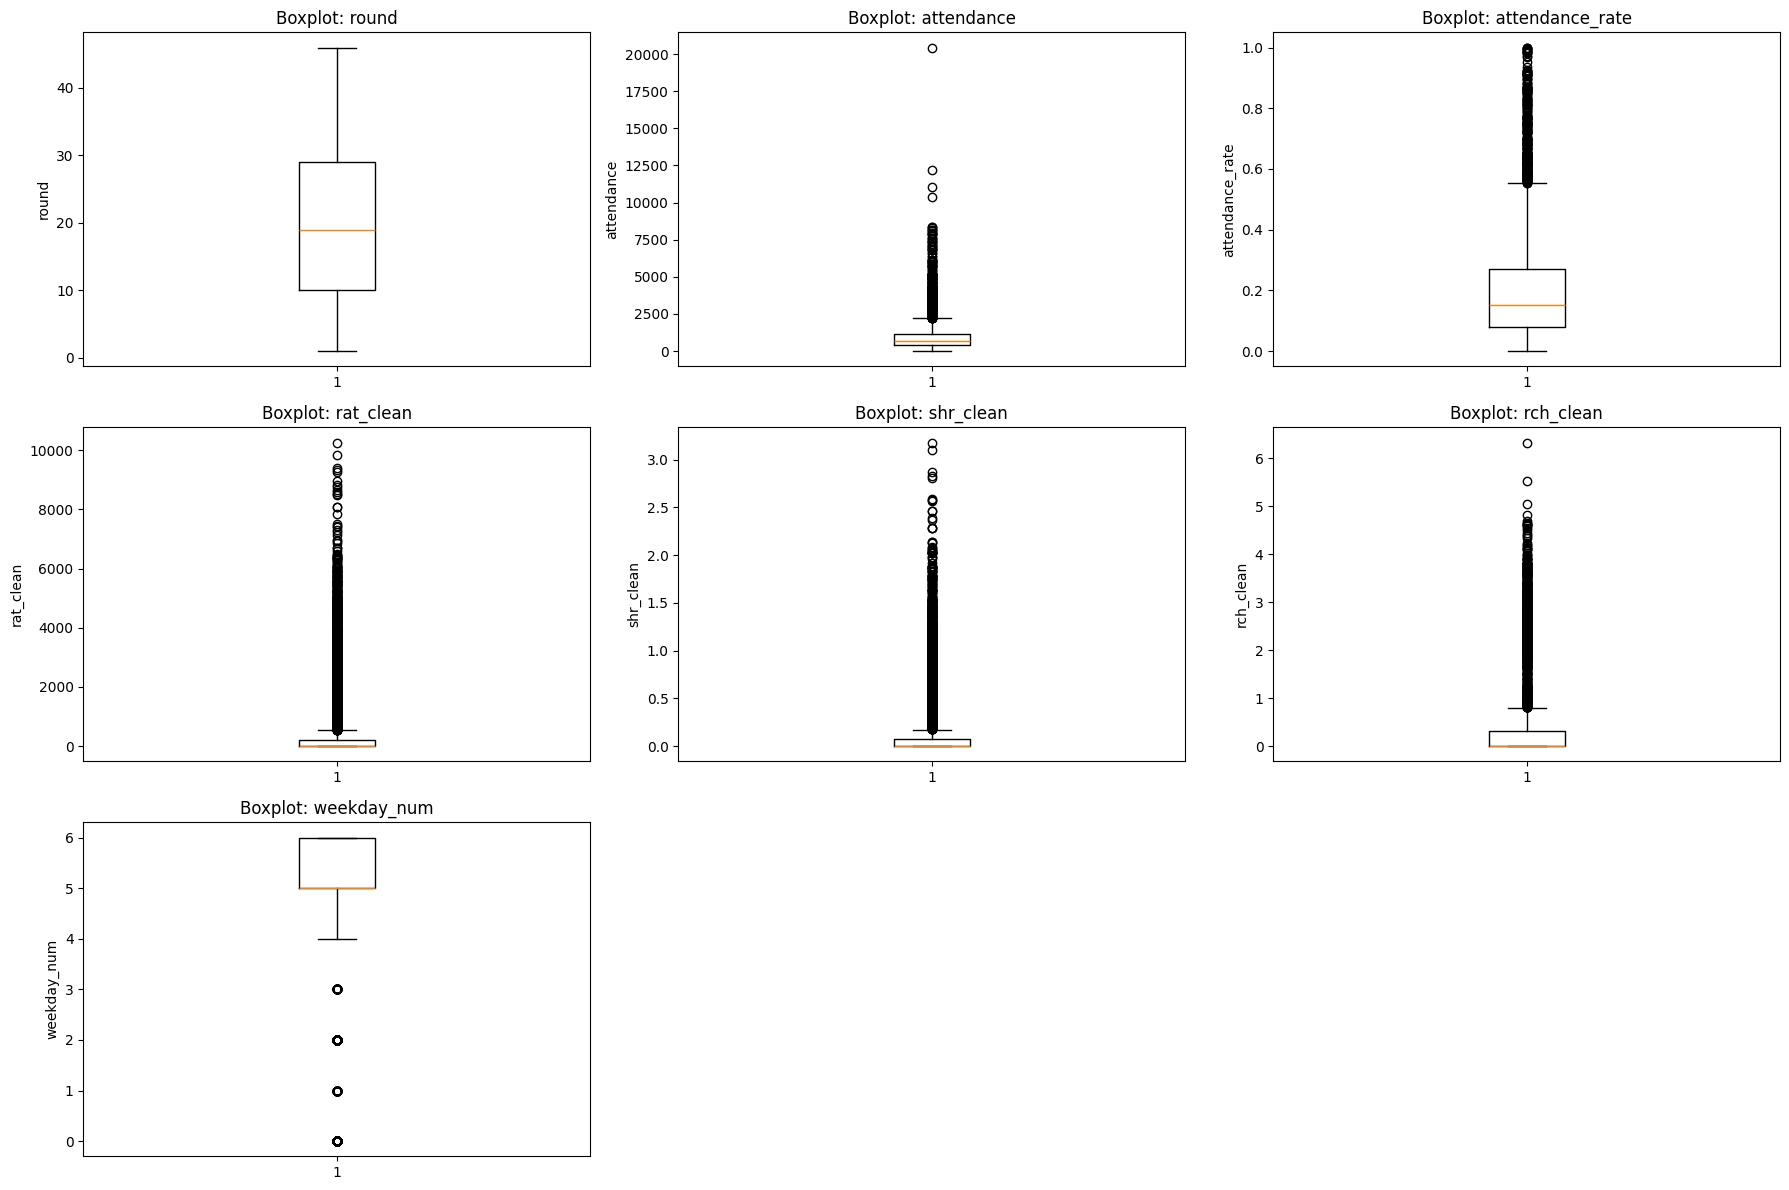

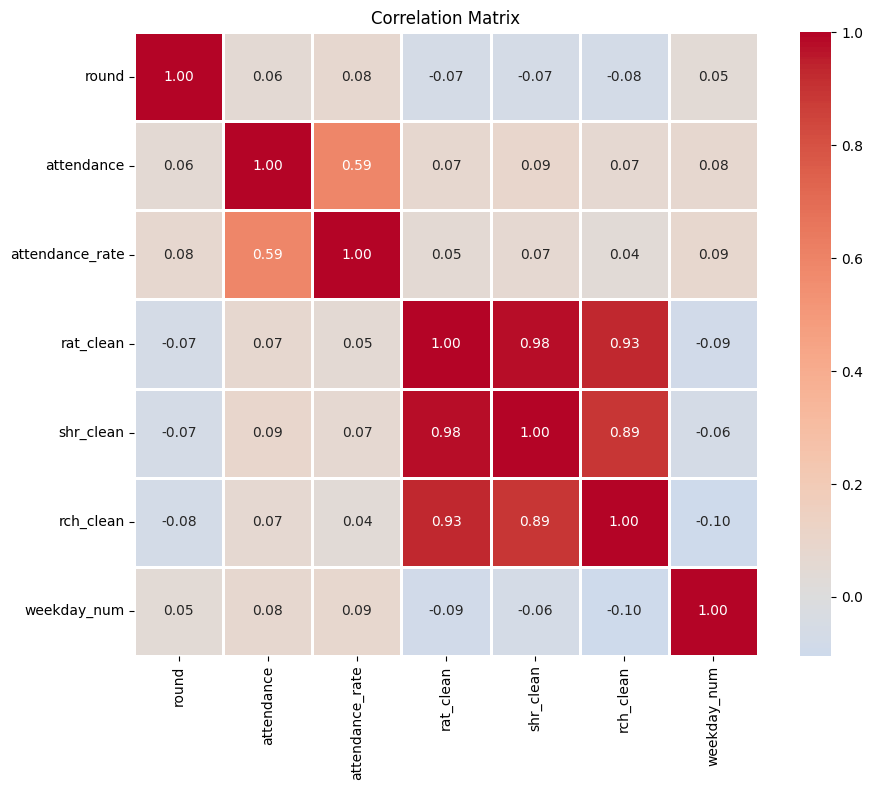

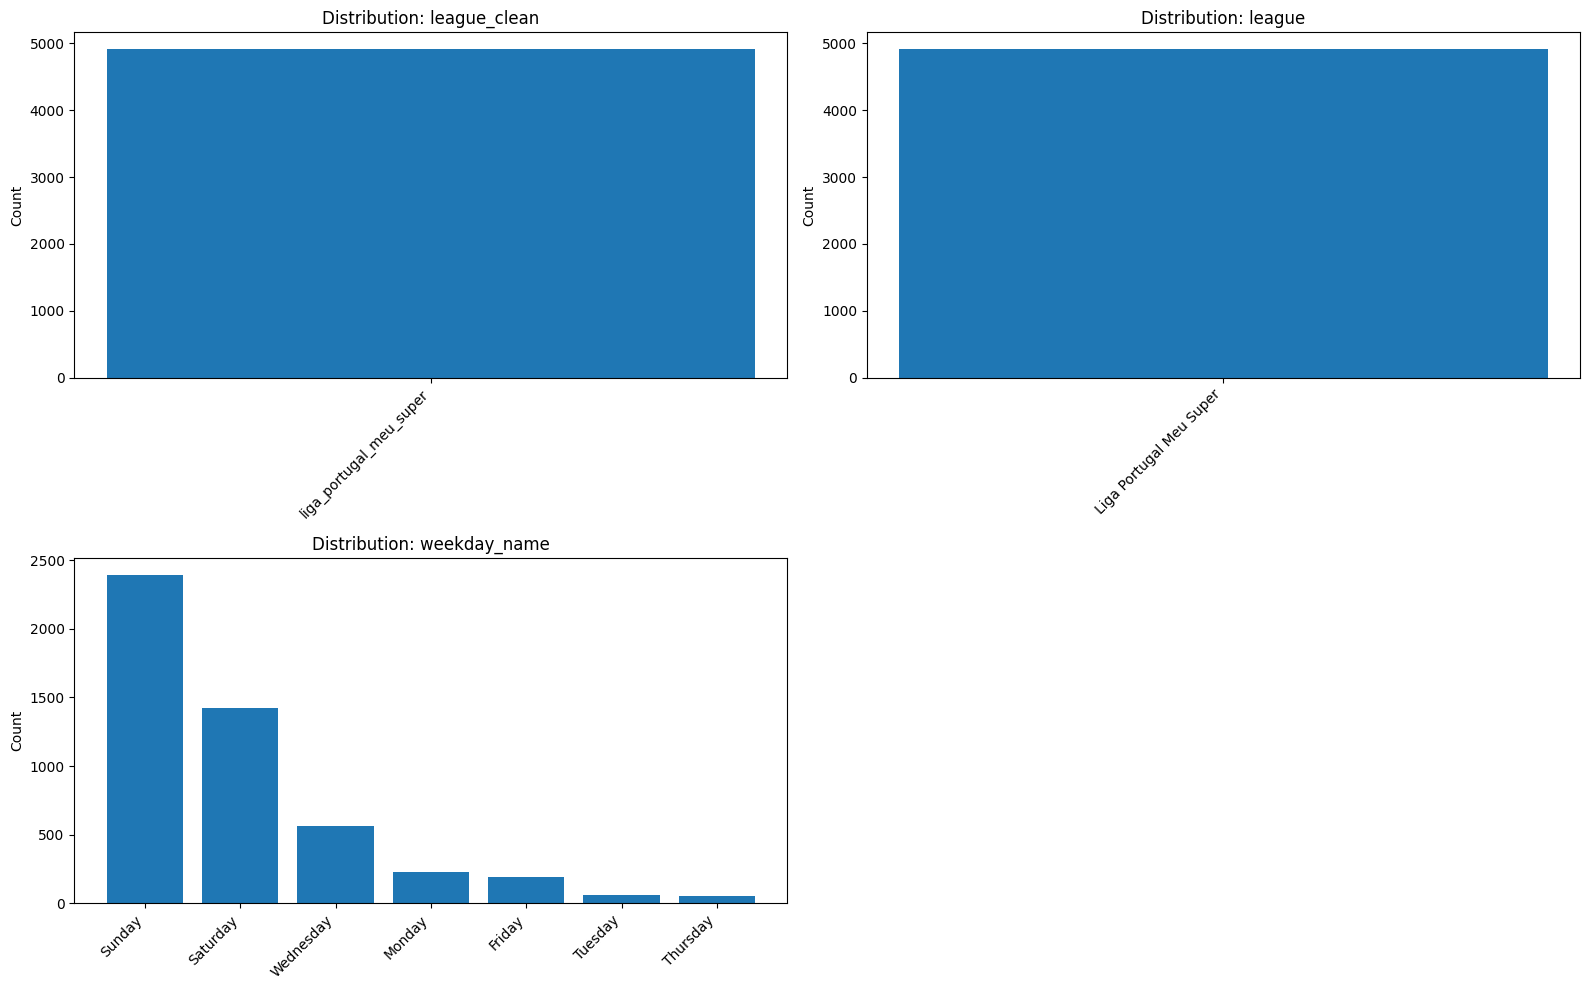

In [ ]:
if df_merged_grouped is not None and not df_merged_grouped.empty:
    for competicao in sorted(df_merged_grouped['league'].unique()):
        df_competicao = df_merged_grouped[df_merged_grouped['league'] == competicao]
        print(f"\n{competicao} Data Summary:")
        da.quick_summary(df_competicao)


In [ ]:
df_merged_grouped

,league_clean,season,round,home_team_clean,away_team_clean,date_time,attendance,attendance_rate,rat_clean,shr_clean,rch_clean,league,home_team,away_team,station_clean,weekday_name,weekday_num,hour,date
0,allianz_cup,200708,<NA>,beiramar,boavista_fc,2007-08-12 19:45:00+00:00,1218,0.0000,0.0,0.00,0.00,Allianz Cup,Beira-Mar,Boavista FC,none,Sunday,6,19:45:00,2007-08-12
1,allianz_cup,200708,<NA>,beiramar,fc_penafiel,2008-01-09 19:30:00+00:00,404,0.0000,0.0,0.00,0.00,Allianz Cup,Beira-Mar,FC Penafiel,none,Wednesday,2,19:30:00,2008-01-09
2,allianz_cup,200708,<NA>,beiramar,fc_pferreira,2007-09-26 19:00:00+00:00,591,0.0000,0.0,0.00,0.00,Allianz Cup,Beira-Mar,FC P.Ferreira,none,Wednesday,2,19:00:00,2007-09-26
3,allianz_cup,200708,<NA>,beiramar,portimonense,2007-10-31 20:00:00+00:00,658,0.0000,0.0,0.00,0.00,Allianz Cup,Beira-Mar,Portimonense,none,Wednesday,2,20:00:00,2007-10-31
4,allianz_cup,200708,<NA>,cd_trofense,cd_feirense,2007-08-04 17:00:00+00:00,622,0.0000,0.0,0.00,0.00,Allianz Cup,CD Trofense,CD Feirense,none,Saturday,5,17:00:00,2007-08-04
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9629,liga_portugal_meu_super,202425,34,fc_penafiel,gd_chaves,2025-05-15 18:45:00+00:00,556,0.1044,4090.0,0.99,2.67,Liga Portugal Meu Super,FC Penafiel,GD Chaves,sporttv_,Thursday,3,18:45:00,2025-05-15
9630,liga_portugal_meu_super,202425,34,fc_porto_b,sl_benfica_b,2025-05-17 11:00:00+00:00,698,0.2140,1318.0,0.54,0.82,Liga Portugal Meu Super,FC Porto B,SL Benfica B,porto_canal,Saturday,5,11:00:00,2025-05-17
9631,liga_portugal_meu_super,202425,34,leixoes_sc,cd_feirense,2025-05-14 20:15:00+00:00,1543,0.2953,3711.0,0.76,2.51,Liga Portugal Meu Super,Leixões SC,CD Feirense,sporttv_,Wednesday,2,20:15:00,2025-05-14
9632,liga_portugal_meu_super,202425,34,maritimo_m,fc_vizela,2025-05-16 20:30:00+00:00,6102,0.5776,1191.0,0.26,0.95,Liga Portugal Meu Super,Marítimo M.,FC Vizela,sporttv_2,Friday,4,20:30:00,2025-05-16


In [ ]:
# Carregamento das tabelas com informação das equipas e estádios

# Define the path to the stadia file
fact_team_stadia_path = DataFilesPath + '/team_stadia.csv'
teams_dim_path = DataFilesPath + '/team_name_scd.csv'
stadia_dim_path = DataFilesPath + '/stadia_scd.csv'

logger_main.info("Iniciando processo de matching das equipas com dados dos estádios...")

# Bloco de tratamento de erros para carregamento do ficheiro

# Carregar ficheiro com a relação estádios e clubes
required_club_stadia_columns = ['team_id', 'stadium_id', 'start_date', 'end_date', 'is_current']

df_club_stadia = fo.safe_read_csv_with_validation(
    fact_team_stadia_path,
    logger_main,
    required_club_stadia_columns,
    sep=';',
    decimal='.',
    low_memory=False
)

# Carregar ficheiro de equipas
required_teams_columns = ['team_id', 'team_name', 'start_date', 'end_date', 'is_current']
unique_team_cols = ['team_id']  # team_id deve ser único

df_teams = fo.safe_read_csv_with_validation(
    teams_dim_path,
    logger_main,
    required_teams_columns,
    unique_columns=unique_team_cols,
    sep=';',
    decimal='.',
    low_memory=False
)

# Carregar ficheiro dos estádios
required_stadia_columns = ['stadium_id', 'stadium_name', 'capacity', 'address', 'latitud', 'longitud', 'district', 'detailed_region', \
                                'simple_region', 'start_date', 'end_date', 'is_current']
unique_stadium_cols = ['stadium_id']  # stadium_id deve ser único

df_stadia = fo.safe_read_csv_with_validation(
    stadia_dim_path,
    logger_main,
    required_stadia_columns,
    unique_columns=unique_stadium_cols,
    sep=';',
    decimal='.',
    low_memory=False
)


if (df_club_stadia is not None and not df_club_stadia.empty) and \
    (df_stadia is not None and not df_stadia.empty) and \
    (df_teams is not None and not df_teams.empty):
    # Filtrar apenas os registos atuais
    df_club_stadia = df_club_stadia[df_club_stadia['is_current'] == True]
    df_club_stadia.drop(columns=['start_date', 'end_date', 'is_current', 'team_name', 'stadium_name'], inplace=True)

    df_teams = df_teams[df_teams['is_current'] == True]

    df_stadia = df_stadia[df_stadia['is_current'] == True]
    # Aplicar a função para ir buscando o timezone correto de cada estádio
    df_stadia['timezone'] = df_stadia.apply(hf.infer_timezone, axis=1)  # type: ignore


    # Merge das três tabelas em cadeia
    df_location = (df_teams
                .merge(df_club_stadia, on='team_id', how='left', suffixes=('', '_drop1'))
                .merge(df_stadia[['stadium_id', 'stadium_name', 'capacity', 'address', 'latitud', 'longitud', 'district', 'detailed_region', \
                                    'simple_region', 'timezone']]
                    , on='stadium_id', how='left', suffixes=('', '_drop2'))
            )

    # Remover colunas duplicadas ou desnecessárias
    colunas_drop = (
        [col for col in df_location.columns if '_drop' in col] + 
        ['surrogate_key', 'start_date', 'end_date', 'is_current', 'stadium_id']
    )

    # Remover apenas as colunas que existem no dataframe
    colunas_drop = [col for col in colunas_drop if col in df_location.columns]
    df_location = df_location.drop(columns=colunas_drop)

    # Criar colunas limpas para texto
    colunas_texto = ['team_name', 'stadium_name']

    for col in colunas_texto:
        df_location[col + '_clean'] = dc.clean_text_series(df_location[col], remove_diacritics=True, to_lowercase=True, normalize_spaces=True)

    df_location['capacity'] = df_location['capacity'].apply(dc.convert_to_int)

    display(df_location)


,team_id,team_name,stadium_name,capacity,address,latitud,longitud,district,detailed_region,simple_region,timezone,team_name_clean,stadium_name_clean
0,101,BSAD,Estádio do Restelo,25000,"Praceta Torres do Restelo, 1449-015 Lisboa, Po...",38.702459,-9.207856,Lisboa,Grande Lisboa,Área Metropolitana de Lisboa,Europe/Lisbon,bsad,estadio_do_restelo
1,102,Sporting CP,Estádio José Alvalade,50095,"Rua Professor Fernando da Fonseca, 1501-806 Li...",38.761222,-9.161790,Lisboa,Grande Lisboa,Área Metropolitana de Lisboa,Europe/Lisbon,sporting_cp,estadio_jose_alvalade
2,103,SL Benfica,Estádio do Sport Lisboa e Benfica,65647,"Av. Eusébio da Silva Ferreira, 1500-313 Lisboa...",38.752690,-9.184692,Lisboa,Grande Lisboa,Área Metropolitana de Lisboa,Europe/Lisbon,sl_benfica,estadio_do_sport_lisboa_e_benfica
3,104,FC Porto,Estádio do Dragão,50948,"Via Futebol Clube do Porto, 4350-415 Porto, Po...",41.161770,-8.583591,Porto,Área Metropolitana do Porto,Norte,Europe/Lisbon,fc_porto,estadio_do_dragao
4,105,SC Braga,Estádio Municipal de Braga,30286,"Parque Norte, R. Monte de Castro 12, 4700-087 ...",41.561785,-8.430682,Braga,Cávado,Norte,Europe/Lisbon,sc_braga,estadio_municipal_de_braga
...,...,...,...,...,...,...,...,...,...,...,...,...,...
70,171,Gondomar,Estádio de S.Miguel - Gondomar,2450,"Tv. Santo André, S. Cosme, Portugal",41.135950,-8.541813,Porto,Área Metropolitana do Porto,Norte,Europe/Lisbon,gondomar,estadio_de_smiguel__gondomar
71,172,Carregado,Campo José Lacerda Pinto Barreiros,3000,"R. Primeiro de Maio 5, 2580-000 Carregado",39.022479,-8.978890,Lisboa,Grande Lisboa,Área Metropolitana de Lisboa,Europe/Lisbon,carregado,campo_jose_lacerda_pinto_barreiros
72,173,Oriental Lisboa,Estádio Engenheiro Carlos Salema,4000,"R. José do Patrocínio 94, 1950-166 Lisboa, Por...",38.743607,-9.109808,Lisboa,Grande Lisboa,Área Metropolitana de Lisboa,Europe/Lisbon,oriental_lisboa,estadio_engenheiro_carlos_salema
73,174,Real SC,Complexo Desportivo do Real SC,1200,"R. Cidade Desportiva, Monte Abraão, Queluz, Po...",38.752094,-9.269672,Lisboa,Grande Lisboa,"Área Metropolitana de Lisboa""",Europe/Lisbon,real_sc,complexo_desportivo_do_real_sc


In [ ]:
# Merge df_location with df_merged_gouped by Clube and EquipaCasa.
# Prepare the location data for the home team merge by renaming columns

columns_to_rename_home_team = {
     'stadium_name': 'home_stadium',
     'stadium_name_clean': 'home_stadium_clean',
     'capacity': 'home_stadium_capacity',
     'latitud': 'home_stadium_latitud',
     'longitud': 'home_stadium_longitud',
     'district': 'home_stadium_district',
     'detailed_region': 'home_stadium_detailed_region',
     'simple_region': 'home_stadium_simple_region',
     'timezone': 'home_stadium_timezone'}

df_location_casa = df_location.rename(
    columns=columns_to_rename_home_team
)

# Ver duplicações no df_location_casa
dup_team_names = df_location_casa[df_location_casa.duplicated(subset='team_name_clean', keep=False)]
print("Equipas duplicadas em df_location_casa:")
display(dup_team_names[['team_name_clean', 'home_stadium', 'home_stadium_clean']])

# Contagem de linhas antes e depois do merge
print(f"Linhas df_merged_grouped: {len(df_merged_grouped)}")


Equipas duplicadas em df_location_casa:


,team_name_clean,home_stadium,home_stadium_clean


Linhas df_merged_grouped: 9634


In [ ]:


# Merge df_location_casa with df_merged_gouped
df_merged_with_location = pd.merge(
    df_merged_grouped,
    df_location_casa[['team_name_clean','home_stadium', 'home_stadium_clean', 'home_stadium_capacity', \
                      'home_stadium_latitud', 'home_stadium_longitud', 'home_stadium_district', \
                        'home_stadium_detailed_region', 'home_stadium_simple_region', 'home_stadium_timezone']], # Select only necessary columns
    how='left',
    left_on='home_team_clean', # Merge key from df_merged_gouped
    right_on='team_name_clean'           # Merge key from df_location_casa
)

print(f"Linhas df_merged_with_location: {len(df_merged_with_location)}")


Linhas df_merged_with_location: 9634


In [ ]:

display(df_merged_with_location)

# Drop the redundant 'Clube' column from the merged dataframe
df_merged_with_location.drop('team_name_clean', axis=1, inplace=True)

cols_to_check = ['home_stadium_longitud']
missing_matches = df_merged_with_location[df_merged_with_location[cols_to_check].isna().any(axis=1)]

print("\nRows with missing data in selected columns:")
display(missing_matches)

,league_clean,season,round,home_team_clean,away_team_clean,date_time,attendance,attendance_rate,rat_clean,shr_clean,...,team_name_clean,home_stadium,home_stadium_clean,home_stadium_capacity,home_stadium_latitud,home_stadium_longitud,home_stadium_district,home_stadium_detailed_region,home_stadium_simple_region,home_stadium_timezone
0,allianz_cup,200708,<NA>,beiramar,boavista_fc,2007-08-12 19:45:00+00:00,1218,0.0000,0.0,0.00,...,beiramar,Estádio Municipal de Aveiro,estadio_municipal_de_aveiro,30127,40.647935,-8.593699,Aveiro,Região de Aveiro,Centro,Europe/Lisbon
1,allianz_cup,200708,<NA>,beiramar,fc_penafiel,2008-01-09 19:30:00+00:00,404,0.0000,0.0,0.00,...,beiramar,Estádio Municipal de Aveiro,estadio_municipal_de_aveiro,30127,40.647935,-8.593699,Aveiro,Região de Aveiro,Centro,Europe/Lisbon
2,allianz_cup,200708,<NA>,beiramar,fc_pferreira,2007-09-26 19:00:00+00:00,591,0.0000,0.0,0.00,...,beiramar,Estádio Municipal de Aveiro,estadio_municipal_de_aveiro,30127,40.647935,-8.593699,Aveiro,Região de Aveiro,Centro,Europe/Lisbon
3,allianz_cup,200708,<NA>,beiramar,portimonense,2007-10-31 20:00:00+00:00,658,0.0000,0.0,0.00,...,beiramar,Estádio Municipal de Aveiro,estadio_municipal_de_aveiro,30127,40.647935,-8.593699,Aveiro,Região de Aveiro,Centro,Europe/Lisbon
4,allianz_cup,200708,<NA>,cd_trofense,cd_feirense,2007-08-04 17:00:00+00:00,622,0.0000,0.0,0.00,...,cd_trofense,Estádio Clube Desportivo Trofense,estadio_clube_desportivo_trofense,5500,41.332180,-8.564484,Porto,Área Metropolitana do Porto,Norte,Europe/Lisbon
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9629,liga_portugal_meu_super,202425,34,fc_penafiel,gd_chaves,2025-05-15 18:45:00+00:00,556,0.1044,4090.0,0.99,...,fc_penafiel,Estádio Municipal 25 de Abril,estadio_municipal_25_de_abril,8500,41.211715,-8.277775,Porto,Tâmega e Sousa,Norte,Europe/Lisbon
9630,liga_portugal_meu_super,202425,34,fc_porto_b,sl_benfica_b,2025-05-17 11:00:00+00:00,698,0.2140,1318.0,0.54,...,fc_porto_b,Estádio Luis Filipe Menezes,estadio_luis_filipe_menezes,3800,41.065648,-8.516915,Porto,Área Metropolitana do Porto,Norte,Europe/Lisbon
9631,liga_portugal_meu_super,202425,34,leixoes_sc,cd_feirense,2025-05-14 20:15:00+00:00,1543,0.2953,3711.0,0.76,...,leixoes_sc,Estádio do Mar,estadio_do_mar,12500,41.183895,-8.666842,Porto,Área Metropolitana do Porto,Norte,Europe/Lisbon
9632,liga_portugal_meu_super,202425,34,maritimo_m,fc_vizela,2025-05-16 20:30:00+00:00,6102,0.5776,1191.0,0.26,...,maritimo_m,Estádio do Marítimo,estadio_do_maritimo,10932,32.645590,-16.928341,Ilha da Madeira,Região Autónoma da Madeira,Região Autónoma da Madeira,Europe/Lisbon



Rows with missing data in selected columns:


,league_clean,season,round,home_team_clean,away_team_clean,date_time,attendance,attendance_rate,rat_clean,shr_clean,...,date,home_stadium,home_stadium_clean,home_stadium_capacity,home_stadium_latitud,home_stadium_longitud,home_stadium_district,home_stadium_detailed_region,home_stadium_simple_region,home_stadium_timezone


In [ ]:
columns_to_rename_away_team = {
    'stadium_name': 'away_stadium',
    'stadium_name_clean': 'away_stadium_clean',
    'latitud': 'away_stadium_latitud',
    'longitud': 'away_stadium_longitud',
    'district': 'away_stadium_district',
    'detailed_region': 'away_stadium_detailed_region',
    'simple_region': 'away_stadium_simple_region',
}

# Prepare the location data for the away team merge by renaming columns
df_location_fora = df_location.rename(
    columns=columns_to_rename_away_team
)

# Merge df_location_fora with the dataframe that already has home location
df_merged_with_location = pd.merge(
    df_merged_with_location,
    df_location_fora[['team_name_clean', 'away_stadium', 'away_stadium_clean', 'away_stadium_latitud', 'away_stadium_longitud',
                      'away_stadium_district', 'away_stadium_detailed_region', 'away_stadium_simple_region']], # Select only necessary columns
    how='left',
    left_on='away_team_clean', # Merge key from df_merged_with_location
    right_on='team_name_clean'           # Merge key from df_location_fora
)

# Drop the redundant 'Clube' column from the merged dataframe
df_merged_with_location.drop('team_name_clean', axis=1, inplace=True)

print(f"\nNúmero de linhas no df_merged_with_location: {len(df_merged_with_location)}")
print("\nColumns and their types after merging with location:")
print(df_merged_with_location.dtypes)

print("\nRows with missing location data after merge:")
print(df_merged_with_location[df_merged_with_location[['home_stadium_latitud', 'home_stadium_longitud',\
                                                        'away_stadium_latitud', 'away_stadium_longitud']].isnull().any(axis=1)].head())

display(df_merged_with_location.head(10))

cols_to_check = ['home_stadium_longitud', 'away_stadium_longitud'] 
missing_matches = df_merged_with_location[df_merged_with_location[cols_to_check].isna().any(axis=1)]

print("\nRows with missing data in selected columns:")
display(missing_matches)

del df_merged_grouped  # Free memory



Número de linhas no df_merged_with_location: 9634

Columns and their types after merging with location:
league_clean                                 object
season                                       object
round                                         Int64
home_team_clean                              object
away_team_clean                              object
date_time                       datetime64[ns, UTC]
attendance                                    Int64
attendance_rate                             float64
rat_clean                                   float64
shr_clean                                   float64
rch_clean                                   float64
league                                       object
home_team                                    object
away_team                                    object
station_clean                                object
weekday_name                                 object
weekday_num                                   Int64
hour       

,league_clean,season,round,home_team_clean,away_team_clean,date_time,attendance,attendance_rate,rat_clean,shr_clean,...,home_stadium_detailed_region,home_stadium_simple_region,home_stadium_timezone,away_stadium,away_stadium_clean,away_stadium_latitud,away_stadium_longitud,away_stadium_district,away_stadium_detailed_region,away_stadium_simple_region
0,allianz_cup,200708,<NA>,beiramar,boavista_fc,2007-08-12 19:45:00+00:00,1218,0.0,0.0,0.0,...,Região de Aveiro,Centro,Europe/Lisbon,Estádio do Bessa Sec. XXI,estadio_do_bessa_sec_xxi,41.162210,-8.642561,Porto,Área Metropolitana do Porto,Norte
1,allianz_cup,200708,<NA>,beiramar,fc_penafiel,2008-01-09 19:30:00+00:00,404,0.0,0.0,0.0,...,Região de Aveiro,Centro,Europe/Lisbon,Estádio Municipal 25 de Abril,estadio_municipal_25_de_abril,41.211715,-8.277775,Porto,Tâmega e Sousa,Norte
2,allianz_cup,200708,<NA>,beiramar,fc_pferreira,2007-09-26 19:00:00+00:00,591,0.0,0.0,0.0,...,Região de Aveiro,Centro,Europe/Lisbon,Estádio Capital do Móvel,estadio_capital_do_movel,41.271408,-8.385264,Porto,Tâmega e Sousa,Norte
3,allianz_cup,200708,<NA>,beiramar,portimonense,2007-10-31 20:00:00+00:00,658,0.0,0.0,0.0,...,Região de Aveiro,Centro,Europe/Lisbon,Estádio Municipal de Portimão,estadio_municipal_de_portimao,37.135710,-8.539836,Faro,Algarve,Algarve
4,allianz_cup,200708,<NA>,cd_trofense,cd_feirense,2007-08-04 17:00:00+00:00,622,0.0,0.0,0.0,...,Área Metropolitana do Porto,Norte,Europe/Lisbon,Estádio Marcolino Castro,estadio_marcolino_castro,40.926617,-8.545848,Aveiro,Área Metropolitana do Porto,Norte
5,allianz_cup,200708,<NA>,cd_trofense,vitoria_sc,2007-08-12 18:00:00+00:00,2146,0.0,0.0,0.0,...,Área Metropolitana do Porto,Norte,Europe/Lisbon,Estádio D. Afonso Henriques,estadio_d_afonso_henriques,41.446925,-8.291746,Braga,Ave,Norte
6,allianz_cup,200708,<NA>,estoril_praia,cd_aves,2007-08-05 16:00:00+00:00,252,0.0,0.0,0.0,...,Grande Lisboa,Área Metropolitana de Lisboa,Europe/Lisbon,Estádio do Clube Desportivo das Aves,estadio_do_clube_desportivo_das_aves,41.366850,-8.411678,Porto,Área Metropolitana do Porto,Norte
7,allianz_cup,200708,<NA>,estoril_praia,estrela_amadora,2007-08-12 16:00:00+00:00,385,0.0,0.0,0.0,...,Grande Lisboa,Área Metropolitana de Lisboa,Europe/Lisbon,Estádio José Gomes,estadio_jose_gomes,38.752024,-9.227897,Lisboa,Grande Lisboa,Área Metropolitana de Lisboa
8,allianz_cup,200708,<NA>,estrela_amadora,sl_benfica,2007-09-26 20:30:00+00:00,2333,0.0,0.0,0.0,...,Grande Lisboa,Área Metropolitana de Lisboa,Europe/Lisbon,Estádio do Sport Lisboa e Benfica,estadio_do_sport_lisboa_e_benfica,38.752690,-9.184692,Lisboa,Grande Lisboa,Área Metropolitana de Lisboa
9,allianz_cup,200708,<NA>,fatima,a_academica,2007-08-12 17:00:00+00:00,1250,0.0,0.0,0.0,...,Lezíria do Tejo,Centro,Europe/Lisbon,Estádio EFAPEL Cidade de Coimbra,estadio_efapel_cidade_de_coimbra,40.203301,-8.407625,Coimbra,Região de Coimbra,Centro



Rows with missing data in selected columns:


,league_clean,season,round,home_team_clean,away_team_clean,date_time,attendance,attendance_rate,rat_clean,shr_clean,...,home_stadium_detailed_region,home_stadium_simple_region,home_stadium_timezone,away_stadium,away_stadium_clean,away_stadium_latitud,away_stadium_longitud,away_stadium_district,away_stadium_detailed_region,away_stadium_simple_region


In [ ]:
# Carregamento das tabelas com informação dos jogos, obtida de webscraping do site da Liga Portugal

# Define the path to the stadia file

liga_webscraping_data_path = DataFilesPath + '/dados_ligas_1_2_2012_2025.csv'

logger_main.info("Iniciando carga de dados dos jogos por webscraping do site da liga...")

# Bloco de tratamento de erros para carregamento do ficheiro

# Carregar ficheiro com a relação estádios e clubes
required_game_data_columns = ['season', 'round', 'game', 'league', 'date_time', 'home_team', 'away_team', 'home_goals', \
                              'away_goals', 'game_stadium', 'attendance', 'attendance_rate']

df_liga_web_data = fo.safe_read_csv_with_validation(
    liga_webscraping_data_path,
    logger_main,
    required_game_data_columns,
    sep=';',
    decimal='.',
    low_memory=False
)

# Preparação e limpeza dos dados


if df_liga_web_data is not None and not df_liga_web_data.empty:

    text_columns = ['season', 'league', 'game_stadium', 'home_team', 'away_team']
    # Create cleaned version of text columns: remove diacritics, convert to lowercase, normalize
    for col in text_columns:
        df_liga_web_data[col + '_clean'] = dc.clean_text_series(\
            df_liga_web_data[col], remove_diacritics=True, to_lowercase=True, normalize_spaces=True)

    df_liga_web_data['season'] = df_liga_web_data['season_clean'].astype(str)

    df_liga_web_data['date_time'] = df_liga_web_data['date_time'].apply(dc.parse_data_portuguesa)
    df_liga_web_data['date'] = df_liga_web_data['date_time'].dt.strftime('%Y-%m-%d')

        # Convert numeric columns to float
    decimal_columns = ['attendance_rate']

    for col in decimal_columns:
        # Create a lowercased variable name based on the original column name
        col_clean_name = col + "_clean"
        df_liga_web_data[col_clean_name] = df_liga_web_data[col].apply(dc.convert_to_float)

    # Convert occupancy rate to decimal (divided by 100)
    df_liga_web_data['attendance_rate'] = df_liga_web_data['attendance_rate_clean'].div(100)

    
    # Convert to integer where possible, keeping NaN
    df_liga_web_data['round'] = (
        pd.to_numeric(df_liga_web_data['round'], errors='coerce')
        .astype('Int64')
    )
    df_liga_web_data['attendance'] = (
        pd.to_numeric(df_liga_web_data['attendance'], errors='coerce')
        .astype('Int64')
    )

    df_liga_web_data.drop(['season_clean'], axis=1, inplace=True)
    df_liga_web_data.drop(['attendance_rate_clean'], axis=1, inplace=True)

    display(df_liga_web_data)


,season,round,game,league,date_time,home_team,away_team,home_goals,away_goals,game_stadium,attendance,attendance_rate,league_clean,game_stadium_clean,home_team_clean,away_team_clean,date
0,201213,1,1,Liga Portugal Betclic,2012-08-18 17:15:00+00:00,Rio Ave FC,Marítimo M.,0,1,Estádio do Rio Ave Futebol Clube,1239,0.2363,liga_portugal_betclic,estadio_do_rio_ave_futebol_clube,rio_ave_fc,maritimo_m,2012-08-18
1,201213,1,2,Liga Portugal Betclic,2012-08-19 15:00:00+00:00,CD Nacional,Vitória FC,2,2,Estádio da Madeira,1390,0.2701,liga_portugal_betclic,estadio_da_madeira,cd_nacional,vitoria_fc,2012-08-19
2,201213,1,3,Liga Portugal Betclic,2012-08-18 19:15:00+00:00,SL Benfica,SC Braga,2,2,Estádio do Sport Lisboa e Benfica,53357,0.7833,liga_portugal_betclic,estadio_do_sport_lisboa_e_benfica,sl_benfica,sc_braga,2012-08-18
3,201213,1,4,Liga Portugal Betclic,2012-08-19 17:00:00+00:00,FC P.Ferreira,Moreirense FC,1,1,Estádio Capital do Móvel,1221,0.1360,liga_portugal_betclic,estadio_capital_do_movel,fc_pferreira,moreirense_fc,2012-08-19
4,201213,1,5,Liga Portugal Betclic,2012-08-20 19:15:00+00:00,Beira-Mar,A. Académica,3,3,Estádio Municipal de Aveiro,2830,0.0968,liga_portugal_betclic,estadio_municipal_de_aveiro,beiramar,a_academica,2012-08-20
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7839,202425,34,5,Liga Portugal Meu Super,2025-05-16 19:30:00+00:00,FC Alverca,Portimonense,2,1,Estádio do FC Alverca,2521,0.3639,liga_portugal_meu_super,estadio_do_fc_alverca,fc_alverca,portimonense,2025-05-16
7840,202425,34,6,Liga Portugal Meu Super,2025-05-15 19:45:00+00:00,CD Mafra,SCU Torreense,2,0,Estádio do Parque Desportivo Municipal de Mafra,535,0.4364,liga_portugal_meu_super,estadio_do_parque_desportivo_municipal_de_mafra,cd_mafra,scu_torreense,2025-05-15
7841,202425,34,7,Liga Portugal Meu Super,2025-05-17 13:00:00+00:00,FC Felgueiras,UD Oliveirense,2,1,Estádio Municipal Dr. Machado de Matos,1410,0.2141,liga_portugal_meu_super,estadio_municipal_dr_machado_de_matos,fc_felgueiras,ud_oliveirense,2025-05-17
7842,202425,34,8,Liga Portugal Meu Super,2025-05-16 19:30:00+00:00,Marítimo M.,FC Vizela,1,2,Estádio do Marítimo,6102,0.5776,liga_portugal_meu_super,estadio_do_maritimo,maritimo_m,fc_vizela,2025-05-16


In [ ]:
display (df_stadia.head(10))

,surrogate_key,stadium_id,stadium_name,capacity,address,latitud,longitud,district,detailed_region,simple_region,start_date,end_date,is_current,timezone
0,1,S1001,Estádio do Sport Lisboa e Benfica,65647,"Av. Eusébio da Silva Ferreira, 1500-313 Lisboa...",38.752690,-9.184692,Lisboa,Grande Lisboa,Área Metropolitana de Lisboa,1930-01-01,9999-12-31,True,Europe/Lisbon
1,2,S1002,Estádio do Dragão,50948,"Via Futebol Clube do Porto, 4350-415 Porto, Po...",41.161770,-8.583591,Porto,Área Metropolitana do Porto,Norte,1930-01-01,9999-12-31,True,Europe/Lisbon
2,3,S1003,Estádio José Alvalade,50095,"Rua Professor Fernando da Fonseca, 1501-806 Li...",38.761222,-9.161790,Lisboa,Grande Lisboa,Área Metropolitana de Lisboa,1930-01-01,9999-12-31,True,Europe/Lisbon
3,4,S1004,Estádio Aurélio Pereira,1180,"Estr. Malhada de Meias 2890, 2890-529 Alcochet...",38.729720,-8.848853,Setúbal,Península de Setúbal,Área Metropolitana de Lisboa,1930-01-01,9999-12-31,True,Europe/Lisbon
4,5,S1005,Estádio Nacional,37593,"Estádio de Honra, 1600-190 Lisboa, Portugal",38.708614,-9.260889,Lisboa,Grande Lisboa,Área Metropolitana de Lisboa,1930-01-01,9999-12-31,True,Europe/Lisbon
5,6,S1006,Estádio Municipal de Braga,30286,"Parque Norte, R. Monte de Castro 12, 4700-087 ...",41.561785,-8.430682,Braga,Cávado,Norte,1930-01-01,9999-12-31,True,Europe/Lisbon
6,7,S1007,Estádio D. Afonso Henriques,30165,"R. Conde Dom Henrique 11, 4800-412 Guimarães, ...",41.446925,-8.291746,Braga,Ave,Norte,1930-01-01,9999-12-31,True,Europe/Lisbon
8,9,S1009,Estádio 1º de Maio,28000,"N101 12, Braga, Portugal",41.538854,-8.420588,Braga,Cávado,Norte,1930-01-01,9999-12-31,True,Europe/Lisbon
9,10,S1010,Estádio Dr. Magalhães Pessoa,29900,"Arrabalde d'Aquém, 2400-137 Leiria, Portugal",39.748775,-8.812924,Leiria,Região de Leiria,Centro,1958-01-01,2022-12-31,True,Europe/Lisbon
10,11,S1011,Estádio do Bessa Sec. XXI,28263,"R. de O Primeiro de Janeiro, 4100-365 Porto, P...",41.162210,-8.642561,Porto,Área Metropolitana do Porto,Norte,1930-01-01,9999-12-31,True,Europe/Lisbon


In [ ]:
columns_to_rename_game_stadium = {
    'stadium_name': 'game_stadium_name',
    'capacity': 'game_stadium_capacity',
    'longitud': 'game_stadium_longitud',
    'latitud': 'game_stadium_latitud',
    'district': 'game_stadium_district',
    'detailed_region': 'game_stadium_detailed_region',
    'simple_region': 'game_stadium_simple_region',
    'timezone': 'game_stadium_timezone'
}

df_game_stadium_location = df_stadia.rename(
    columns=columns_to_rename_game_stadium
)

columns_to_drop_game_stadium = ['surrogate_key', 'address', 'stadium_id', 'start_date', 'end_date', 'is_current']

df_game_stadium_location = df_game_stadium_location.drop(columns=columns_to_drop_game_stadium, errors='ignore')

df_game_stadium_location['game_stadium_name_clean'] = dc.clean_text_series(df_game_stadium_location['game_stadium_name'],\
                                                 remove_diacritics=True, to_lowercase=True, normalize_spaces=True)

display(df_game_stadium_location)

,game_stadium_name,game_stadium_capacity,game_stadium_latitud,game_stadium_longitud,game_stadium_district,game_stadium_detailed_region,game_stadium_simple_region,game_stadium_timezone,game_stadium_name_clean
0,Estádio do Sport Lisboa e Benfica,65647,38.752690,-9.184692,Lisboa,Grande Lisboa,Área Metropolitana de Lisboa,Europe/Lisbon,estadio_do_sport_lisboa_e_benfica
1,Estádio do Dragão,50948,41.161770,-8.583591,Porto,Área Metropolitana do Porto,Norte,Europe/Lisbon,estadio_do_dragao
2,Estádio José Alvalade,50095,38.761222,-9.161790,Lisboa,Grande Lisboa,Área Metropolitana de Lisboa,Europe/Lisbon,estadio_jose_alvalade
3,Estádio Aurélio Pereira,1180,38.729720,-8.848853,Setúbal,Península de Setúbal,Área Metropolitana de Lisboa,Europe/Lisbon,estadio_aurelio_pereira
4,Estádio Nacional,37593,38.708614,-9.260889,Lisboa,Grande Lisboa,Área Metropolitana de Lisboa,Europe/Lisbon,estadio_nacional
...,...,...,...,...,...,...,...,...,...
81,Estádio Engenheiro Carlos Salema,4000,38.743607,-9.109808,Lisboa,Grande Lisboa,Área Metropolitana de Lisboa,Europe/Lisbon,estadio_engenheiro_carlos_salema
82,Campo do Cevadeiro,1250,38.945298,-8.994413,Lisboa,Grande Lisboa,Área Metropolitana de Lisboa,Europe/Lisbon,campo_do_cevadeiro
83,Estádio Imaculada Conceição,1824,32.670610,-16.936173,Ilha da Madeira,Região Autónoma da Madeira,Região Autónoma da Madeira,Europe/Lisbon,estadio_imaculada_conceicao
84,Estádio de Machico,3300,32.728857,-16.773473,Ilha da Madeira,Região Autónoma da Madeira,Região Autónoma da Madeira,Europe/Lisbon,estadio_de_machico


In [ ]:

df_liga_web_data_location = df_liga_web_data.merge( # type: ignore
    df_game_stadium_location[['game_stadium_name', 'game_stadium_name_clean', 'game_stadium_capacity', 'game_stadium_latitud',\
                               'game_stadium_longitud', 'game_stadium_district', 'game_stadium_detailed_region', 'game_stadium_simple_region', \
                               'game_stadium_timezone']],  # Select only necessary columns
    left_on=['game_stadium_clean'],
    right_on=['game_stadium_name_clean'],
    how='left'
).drop(columns=['game_stadium_name', 'game_stadium_name_clean', 'round', 'game', 'date_time', 'home_team', 'away_team', \
                'attendance', 'attendance_rate'], errors='ignore')  # Remove as colunas-chave duplicadas do df2

display (df_liga_web_data_location)

#del df_game_stadium_location  # Free memory

# Convert the new column to datetime
df_liga_web_data_location['date'] = pd.to_datetime(
    df_liga_web_data_location['date'],
    format='%Y-%m-%d',
    errors='coerce'
).dt.date

,season,league,home_goals,away_goals,game_stadium,league_clean,game_stadium_clean,home_team_clean,away_team_clean,date,game_stadium_capacity,game_stadium_latitud,game_stadium_longitud,game_stadium_district,game_stadium_detailed_region,game_stadium_simple_region,game_stadium_timezone
0,201213,Liga Portugal Betclic,0,1,Estádio do Rio Ave Futebol Clube,liga_portugal_betclic,estadio_do_rio_ave_futebol_clube,rio_ave_fc,maritimo_m,2012-08-18,12820,41.362721,-8.740093,Porto,Área Metropolitana do Porto,Norte,Europe/Lisbon
1,201213,Liga Portugal Betclic,2,2,Estádio da Madeira,liga_portugal_betclic,estadio_da_madeira,cd_nacional,vitoria_fc,2012-08-19,5200,32.670607,-16.883530,Ilha da Madeira,Região Autónoma da Madeira,Região Autónoma da Madeira,Europe/Lisbon
2,201213,Liga Portugal Betclic,2,2,Estádio do Sport Lisboa e Benfica,liga_portugal_betclic,estadio_do_sport_lisboa_e_benfica,sl_benfica,sc_braga,2012-08-18,65647,38.752690,-9.184692,Lisboa,Grande Lisboa,Área Metropolitana de Lisboa,Europe/Lisbon
3,201213,Liga Portugal Betclic,1,1,Estádio Capital do Móvel,liga_portugal_betclic,estadio_capital_do_movel,fc_pferreira,moreirense_fc,2012-08-19,9076,41.271408,-8.385264,Porto,Tâmega e Sousa,Norte,Europe/Lisbon
4,201213,Liga Portugal Betclic,3,3,Estádio Municipal de Aveiro,liga_portugal_betclic,estadio_municipal_de_aveiro,beiramar,a_academica,2012-08-20,30127,40.647935,-8.593699,Aveiro,Região de Aveiro,Centro,Europe/Lisbon
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7839,202425,Liga Portugal Meu Super,2,1,Estádio do FC Alverca,liga_portugal_meu_super,estadio_do_fc_alverca,fc_alverca,portimonense,2025-05-16,7705,38.897912,-9.035013,Lisboa,Grande Lisboa,Área Metropolitana de Lisboa,Europe/Lisbon
7840,202425,Liga Portugal Meu Super,2,0,Estádio do Parque Desportivo Municipal de Mafra,liga_portugal_meu_super,estadio_do_parque_desportivo_municipal_de_mafra,cd_mafra,scu_torreense,2025-05-15,2500,38.936262,-9.332364,Lisboa,Grande Lisboa,Área Metropolitana de Lisboa,Europe/Lisbon
7841,202425,Liga Portugal Meu Super,2,1,Estádio Municipal Dr. Machado de Matos,liga_portugal_meu_super,estadio_municipal_dr_machado_de_matos,fc_felgueiras,ud_oliveirense,2025-05-17,15000,41.378368,-8.216115,Porto,Tâmega e Sousa,Norte,Europe/Lisbon
7842,202425,Liga Portugal Meu Super,1,2,Estádio do Marítimo,liga_portugal_meu_super,estadio_do_maritimo,maritimo_m,fc_vizela,2025-05-16,10932,32.645590,-16.928341,Ilha da Madeira,Região Autónoma da Madeira,Região Autónoma da Madeira,Europe/Lisbon


In [ ]:

print(f"\nDados dos jogos via base de dados (df_merged_with_location), com localização dos estádios:")
display(df_merged_with_location)
print(f"\nDados dos jogos por webscraping do site da liga (df_liga_web_data_location), com localização dos estádios:")
display(df_liga_web_data_location)



Dados dos jogos via base de dados (df_merged_with_location), com localização dos estádios:


,league_clean,season,round,home_team_clean,away_team_clean,date_time,attendance,attendance_rate,rat_clean,shr_clean,...,home_stadium_detailed_region,home_stadium_simple_region,home_stadium_timezone,away_stadium,away_stadium_clean,away_stadium_latitud,away_stadium_longitud,away_stadium_district,away_stadium_detailed_region,away_stadium_simple_region
0,allianz_cup,200708,<NA>,beiramar,boavista_fc,2007-08-12 19:45:00+00:00,1218,0.0000,0.0,0.00,...,Região de Aveiro,Centro,Europe/Lisbon,Estádio do Bessa Sec. XXI,estadio_do_bessa_sec_xxi,41.162210,-8.642561,Porto,Área Metropolitana do Porto,Norte
1,allianz_cup,200708,<NA>,beiramar,fc_penafiel,2008-01-09 19:30:00+00:00,404,0.0000,0.0,0.00,...,Região de Aveiro,Centro,Europe/Lisbon,Estádio Municipal 25 de Abril,estadio_municipal_25_de_abril,41.211715,-8.277775,Porto,Tâmega e Sousa,Norte
2,allianz_cup,200708,<NA>,beiramar,fc_pferreira,2007-09-26 19:00:00+00:00,591,0.0000,0.0,0.00,...,Região de Aveiro,Centro,Europe/Lisbon,Estádio Capital do Móvel,estadio_capital_do_movel,41.271408,-8.385264,Porto,Tâmega e Sousa,Norte
3,allianz_cup,200708,<NA>,beiramar,portimonense,2007-10-31 20:00:00+00:00,658,0.0000,0.0,0.00,...,Região de Aveiro,Centro,Europe/Lisbon,Estádio Municipal de Portimão,estadio_municipal_de_portimao,37.135710,-8.539836,Faro,Algarve,Algarve
4,allianz_cup,200708,<NA>,cd_trofense,cd_feirense,2007-08-04 17:00:00+00:00,622,0.0000,0.0,0.00,...,Área Metropolitana do Porto,Norte,Europe/Lisbon,Estádio Marcolino Castro,estadio_marcolino_castro,40.926617,-8.545848,Aveiro,Área Metropolitana do Porto,Norte
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9629,liga_portugal_meu_super,202425,34,fc_penafiel,gd_chaves,2025-05-15 18:45:00+00:00,556,0.1044,4090.0,0.99,...,Tâmega e Sousa,Norte,Europe/Lisbon,Municipal Eng. Manuel Branco Teixeira,municipal_eng_manuel_branco_teixeira,41.750569,-7.464840,Vila Real,Alto Tâmega e Barroso,Norte
9630,liga_portugal_meu_super,202425,34,fc_porto_b,sl_benfica_b,2025-05-17 11:00:00+00:00,698,0.2140,1318.0,0.54,...,Área Metropolitana do Porto,Norte,Europe/Lisbon,Estádio do Sport Lisboa e Benfica,estadio_do_sport_lisboa_e_benfica,38.752690,-9.184692,Lisboa,Grande Lisboa,Área Metropolitana de Lisboa
9631,liga_portugal_meu_super,202425,34,leixoes_sc,cd_feirense,2025-05-14 20:15:00+00:00,1543,0.2953,3711.0,0.76,...,Área Metropolitana do Porto,Norte,Europe/Lisbon,Estádio Marcolino Castro,estadio_marcolino_castro,40.926617,-8.545848,Aveiro,Área Metropolitana do Porto,Norte
9632,liga_portugal_meu_super,202425,34,maritimo_m,fc_vizela,2025-05-16 20:30:00+00:00,6102,0.5776,1191.0,0.26,...,Região Autónoma da Madeira,Região Autónoma da Madeira,Europe/Lisbon,Estádio Futebol Clube de Vizela,estadio_futebol_clube_de_vizela,41.388771,-8.307334,Braga,Ave,Norte



Dados dos jogos por webscraping do site da liga (df_liga_web_data_location), com localização dos estádios:


,season,league,home_goals,away_goals,game_stadium,league_clean,game_stadium_clean,home_team_clean,away_team_clean,date,game_stadium_capacity,game_stadium_latitud,game_stadium_longitud,game_stadium_district,game_stadium_detailed_region,game_stadium_simple_region,game_stadium_timezone
0,201213,Liga Portugal Betclic,0,1,Estádio do Rio Ave Futebol Clube,liga_portugal_betclic,estadio_do_rio_ave_futebol_clube,rio_ave_fc,maritimo_m,2012-08-18,12820,41.362721,-8.740093,Porto,Área Metropolitana do Porto,Norte,Europe/Lisbon
1,201213,Liga Portugal Betclic,2,2,Estádio da Madeira,liga_portugal_betclic,estadio_da_madeira,cd_nacional,vitoria_fc,2012-08-19,5200,32.670607,-16.883530,Ilha da Madeira,Região Autónoma da Madeira,Região Autónoma da Madeira,Europe/Lisbon
2,201213,Liga Portugal Betclic,2,2,Estádio do Sport Lisboa e Benfica,liga_portugal_betclic,estadio_do_sport_lisboa_e_benfica,sl_benfica,sc_braga,2012-08-18,65647,38.752690,-9.184692,Lisboa,Grande Lisboa,Área Metropolitana de Lisboa,Europe/Lisbon
3,201213,Liga Portugal Betclic,1,1,Estádio Capital do Móvel,liga_portugal_betclic,estadio_capital_do_movel,fc_pferreira,moreirense_fc,2012-08-19,9076,41.271408,-8.385264,Porto,Tâmega e Sousa,Norte,Europe/Lisbon
4,201213,Liga Portugal Betclic,3,3,Estádio Municipal de Aveiro,liga_portugal_betclic,estadio_municipal_de_aveiro,beiramar,a_academica,2012-08-20,30127,40.647935,-8.593699,Aveiro,Região de Aveiro,Centro,Europe/Lisbon
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7839,202425,Liga Portugal Meu Super,2,1,Estádio do FC Alverca,liga_portugal_meu_super,estadio_do_fc_alverca,fc_alverca,portimonense,2025-05-16,7705,38.897912,-9.035013,Lisboa,Grande Lisboa,Área Metropolitana de Lisboa,Europe/Lisbon
7840,202425,Liga Portugal Meu Super,2,0,Estádio do Parque Desportivo Municipal de Mafra,liga_portugal_meu_super,estadio_do_parque_desportivo_municipal_de_mafra,cd_mafra,scu_torreense,2025-05-15,2500,38.936262,-9.332364,Lisboa,Grande Lisboa,Área Metropolitana de Lisboa,Europe/Lisbon
7841,202425,Liga Portugal Meu Super,2,1,Estádio Municipal Dr. Machado de Matos,liga_portugal_meu_super,estadio_municipal_dr_machado_de_matos,fc_felgueiras,ud_oliveirense,2025-05-17,15000,41.378368,-8.216115,Porto,Tâmega e Sousa,Norte,Europe/Lisbon
7842,202425,Liga Portugal Meu Super,1,2,Estádio do Marítimo,liga_portugal_meu_super,estadio_do_maritimo,maritimo_m,fc_vizela,2025-05-16,10932,32.645590,-16.928341,Ilha da Madeira,Região Autónoma da Madeira,Região Autónoma da Madeira,Europe/Lisbon


In [ ]:

df_merged_data = df_merged_with_location.merge(
    df_liga_web_data_location[['season', 'league_clean', 'home_team_clean', 'away_team_clean',
                                'game_stadium', 'game_stadium_clean', 'game_stadium_capacity', 'game_stadium_latitud',
                                'game_stadium_longitud', 'game_stadium_district', 'game_stadium_detailed_region', 'game_stadium_simple_region',
                                'game_stadium_timezone']],  # Select only necessary columns
    left_on=['season', 'league_clean', 'home_team_clean', 'away_team_clean'],
    right_on=['season', 'league_clean', 'home_team_clean', 'away_team_clean'],
    how='left'
)

display(df_merged_data)

cols_to_check = ['game_stadium']
missing_matches = df_merged_data[df_merged_data[cols_to_check].isna().any(axis=1)]

mask_not_allianz = (df_merged_data['league'] != 'Allianz Cup')

print("\nRows with missing data in selected columns:")
display(missing_matches[mask_not_allianz][['season', 'league', 'game_stadium', 'home_team', 'away_team']])

,league_clean,season,round,home_team_clean,away_team_clean,date_time,attendance,attendance_rate,rat_clean,shr_clean,...,away_stadium_simple_region,game_stadium,game_stadium_clean,game_stadium_capacity,game_stadium_latitud,game_stadium_longitud,game_stadium_district,game_stadium_detailed_region,game_stadium_simple_region,game_stadium_timezone
0,allianz_cup,200708,<NA>,beiramar,boavista_fc,2007-08-12 19:45:00+00:00,1218,0.0000,0.0,0.00,...,Norte,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,allianz_cup,200708,<NA>,beiramar,fc_penafiel,2008-01-09 19:30:00+00:00,404,0.0000,0.0,0.00,...,Norte,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,allianz_cup,200708,<NA>,beiramar,fc_pferreira,2007-09-26 19:00:00+00:00,591,0.0000,0.0,0.00,...,Norte,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,allianz_cup,200708,<NA>,beiramar,portimonense,2007-10-31 20:00:00+00:00,658,0.0000,0.0,0.00,...,Algarve,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,allianz_cup,200708,<NA>,cd_trofense,cd_feirense,2007-08-04 17:00:00+00:00,622,0.0000,0.0,0.00,...,Norte,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9629,liga_portugal_meu_super,202425,34,fc_penafiel,gd_chaves,2025-05-15 18:45:00+00:00,556,0.1044,4090.0,0.99,...,Norte,Estádio Municipal 25 de Abril,estadio_municipal_25_de_abril,8500.0,41.211715,-8.277775,Porto,Tâmega e Sousa,Norte,Europe/Lisbon
9630,liga_portugal_meu_super,202425,34,fc_porto_b,sl_benfica_b,2025-05-17 11:00:00+00:00,698,0.2140,1318.0,0.54,...,Área Metropolitana de Lisboa,Estádio Luis Filipe Menezes,estadio_luis_filipe_menezes,3800.0,41.065648,-8.516915,Porto,Área Metropolitana do Porto,Norte,Europe/Lisbon
9631,liga_portugal_meu_super,202425,34,leixoes_sc,cd_feirense,2025-05-14 20:15:00+00:00,1543,0.2953,3711.0,0.76,...,Norte,Estádio do Mar,estadio_do_mar,12500.0,41.183895,-8.666842,Porto,Área Metropolitana do Porto,Norte,Europe/Lisbon
9632,liga_portugal_meu_super,202425,34,maritimo_m,fc_vizela,2025-05-16 20:30:00+00:00,6102,0.5776,1191.0,0.26,...,Norte,Estádio do Marítimo,estadio_do_maritimo,10932.0,32.645590,-16.928341,Ilha da Madeira,Região Autónoma da Madeira,Região Autónoma da Madeira,Europe/Lisbon



Rows with missing data in selected columns:


,season,league,game_stadium,home_team,away_team
5176,201314,Liga Portugal Meu Super,NaN,Atlético CP,Sporting CP B
5177,201314,Liga Portugal Meu Super,NaN,Beira-Mar,FC Porto B
5178,201314,Liga Portugal Meu Super,NaN,CD Aves,U. Madeira
5179,201314,Liga Portugal Meu Super,NaN,CD Trofense,SL Benfica B
5180,201314,Liga Portugal Meu Super,NaN,FC Penafiel,UD Oliveirense
...,...,...,...,...,...
6185,201415,Liga Portugal Meu Super,NaN,SC Braga B,Sporting CP B
6186,201415,Liga Portugal Meu Super,NaN,SC Farense,CD Feirense
6187,201415,Liga Portugal Meu Super,NaN,SC Freamunde,CD Tondela
6188,201415,Liga Portugal Meu Super,NaN,SC Olhanense,Atlético CP


In [ ]:
display(df_merged_data.head(1))

,league_clean,season,round,home_team_clean,away_team_clean,date_time,attendance,attendance_rate,rat_clean,shr_clean,...,away_stadium_simple_region,game_stadium,game_stadium_clean,game_stadium_capacity,game_stadium_latitud,game_stadium_longitud,game_stadium_district,game_stadium_detailed_region,game_stadium_simple_region,game_stadium_timezone
0,allianz_cup,200708,<NA>,beiramar,boavista_fc,2007-08-12 19:45:00+00:00,1218,0.0,0.0,0.0,...,Norte,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [171]:
# encontrar colunas que terminam em 'game_stadium_'
cols_jogo = [col for col in df_merged_data.columns if col.startswith('game_stadium')]
#display(cols_jogo)

# preencher valores NaN nas colunas 'game_stadium_' com os valores correspondentes das colunas 'home_stadium_'
for col in cols_jogo:
    col_casa = col.replace('game_stadium', 'home_stadium')
    if col_casa in df_merged_data.columns:
        df_merged_data[col] = df_merged_data[col].fillna(df_merged_data[col_casa])
        
#df_merged_data['estadio_jogo_cleaned'] = df_merged_data['estadio_jogo_cleaned'].fillna(df_merged_data['estadio_casa_cleaned'])

display(df_merged_data)    

,league_clean,season,round,home_team_clean,away_team_clean,date_time,attendance,attendance_rate,rat_clean,shr_clean,...,away_stadium_simple_region,game_stadium,game_stadium_clean,game_stadium_capacity,game_stadium_latitud,game_stadium_longitud,game_stadium_district,game_stadium_detailed_region,game_stadium_simple_region,game_stadium_timezone
0,allianz_cup,200708,<NA>,beiramar,boavista_fc,2007-08-12 19:45:00+00:00,1218,0.0000,0.0,0.00,...,Norte,Estádio Municipal de Aveiro,estadio_municipal_de_aveiro,30127.0,40.647935,-8.593699,Aveiro,Região de Aveiro,Centro,Europe/Lisbon
1,allianz_cup,200708,<NA>,beiramar,fc_penafiel,2008-01-09 19:30:00+00:00,404,0.0000,0.0,0.00,...,Norte,Estádio Municipal de Aveiro,estadio_municipal_de_aveiro,30127.0,40.647935,-8.593699,Aveiro,Região de Aveiro,Centro,Europe/Lisbon
2,allianz_cup,200708,<NA>,beiramar,fc_pferreira,2007-09-26 19:00:00+00:00,591,0.0000,0.0,0.00,...,Norte,Estádio Municipal de Aveiro,estadio_municipal_de_aveiro,30127.0,40.647935,-8.593699,Aveiro,Região de Aveiro,Centro,Europe/Lisbon
3,allianz_cup,200708,<NA>,beiramar,portimonense,2007-10-31 20:00:00+00:00,658,0.0000,0.0,0.00,...,Algarve,Estádio Municipal de Aveiro,estadio_municipal_de_aveiro,30127.0,40.647935,-8.593699,Aveiro,Região de Aveiro,Centro,Europe/Lisbon
4,allianz_cup,200708,<NA>,cd_trofense,cd_feirense,2007-08-04 17:00:00+00:00,622,0.0000,0.0,0.00,...,Norte,Estádio Clube Desportivo Trofense,estadio_clube_desportivo_trofense,5500.0,41.332180,-8.564484,Porto,Área Metropolitana do Porto,Norte,Europe/Lisbon
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9629,liga_portugal_meu_super,202425,34,fc_penafiel,gd_chaves,2025-05-15 18:45:00+00:00,556,0.1044,4090.0,0.99,...,Norte,Estádio Municipal 25 de Abril,estadio_municipal_25_de_abril,8500.0,41.211715,-8.277775,Porto,Tâmega e Sousa,Norte,Europe/Lisbon
9630,liga_portugal_meu_super,202425,34,fc_porto_b,sl_benfica_b,2025-05-17 11:00:00+00:00,698,0.2140,1318.0,0.54,...,Área Metropolitana de Lisboa,Estádio Luis Filipe Menezes,estadio_luis_filipe_menezes,3800.0,41.065648,-8.516915,Porto,Área Metropolitana do Porto,Norte,Europe/Lisbon
9631,liga_portugal_meu_super,202425,34,leixoes_sc,cd_feirense,2025-05-14 20:15:00+00:00,1543,0.2953,3711.0,0.76,...,Norte,Estádio do Mar,estadio_do_mar,12500.0,41.183895,-8.666842,Porto,Área Metropolitana do Porto,Norte,Europe/Lisbon
9632,liga_portugal_meu_super,202425,34,maritimo_m,fc_vizela,2025-05-16 20:30:00+00:00,6102,0.5776,1191.0,0.26,...,Norte,Estádio do Marítimo,estadio_do_maritimo,10932.0,32.645590,-16.928341,Ilha da Madeira,Região Autónoma da Madeira,Região Autónoma da Madeira,Europe/Lisbon


In [172]:
# Show records where occupancy rate is greater than 1
high_occupancy = df_merged_data[df_merged_data['attendance_rate'] > 1][['league', 'home_team', 'away_team', 'attendance', 'game_stadium_capacity', 'attendance_rate', 'date_time']]
print("Records with occupancy rate > 1:")
display(high_occupancy.sort_values('attendance_rate', ascending=False))

Records with occupancy rate > 1:


,league,home_team,away_team,attendance,game_stadium_capacity,attendance_rate,date_time


In [173]:
condicao = (df_merged_data['attendance'] > (df_merged_data['game_stadium_capacity'])) & \
                                         (df_merged_data['league'] != 'Allianz Cup')
display(df_merged_data[condicao])

,league_clean,season,round,home_team_clean,away_team_clean,date_time,attendance,attendance_rate,rat_clean,shr_clean,...,away_stadium_simple_region,game_stadium,game_stadium_clean,game_stadium_capacity,game_stadium_latitud,game_stadium_longitud,game_stadium_district,game_stadium_detailed_region,game_stadium_simple_region,game_stadium_timezone
1430,liga_portugal_betclic,201415,10,cd_nacional,sl_benfica,2014-11-09 16:00:00+00:00,5239,0.9379,0.0,0.00,...,Área Metropolitana de Lisboa,Estádio da Madeira,estadio_da_madeira,5200.0,32.670607,-16.883530,Ilha da Madeira,Região Autónoma da Madeira,Região Autónoma da Madeira,Europe/Lisbon
1557,liga_portugal_betclic,201415,24,fc_arouca,sl_benfica,2015-03-08 16:00:00+00:00,6960,0.9892,0.0,0.00,...,Área Metropolitana de Lisboa,Estádio Municipal de Arouca,estadio_municipal_de_arouca,5600.0,40.932938,-8.250301,Aveiro,Área Metropolitana do Porto,Norte,Europe/Lisbon
2168,liga_portugal_betclic,201617,24,cd_feirense,sl_benfica,2017-03-04 20:29:00+00:00,5449,1.0000,0.0,0.00,...,Área Metropolitana de Lisboa,Estádio Marcolino Castro,estadio_marcolino_castro,5000.0,40.926617,-8.545848,Aveiro,Área Metropolitana do Porto,Norte,Europe/Lisbon
2303,liga_portugal_betclic,201718,5,cd_feirense,sporting_cp,2017-09-08 18:59:00+00:00,5449,1.0000,0.0,0.00,...,Área Metropolitana de Lisboa,Estádio Marcolino Castro,estadio_marcolino_castro,5000.0,40.926617,-8.545848,Aveiro,Área Metropolitana do Porto,Norte,Europe/Lisbon
2403,liga_portugal_betclic,201718,16,cd_feirense,fc_porto,2018-01-03 20:15:00+00:00,5113,0.9383,0.0,0.00,...,Norte,Estádio Marcolino Castro,estadio_marcolino_castro,5000.0,40.926617,-8.545848,Aveiro,Área Metropolitana do Porto,Norte,Europe/Lisbon
2500,liga_portugal_betclic,201718,27,cd_feirense,sl_benfica,2018-03-17 18:14:00+00:00,5449,1.0000,0.0,0.00,...,Área Metropolitana de Lisboa,Estádio Marcolino Castro,estadio_marcolino_castro,5000.0,40.926617,-8.545848,Aveiro,Área Metropolitana do Porto,Norte,Europe/Lisbon
2565,liga_portugal_betclic,201718,34,cd_feirense,estoril_praia,2018-05-13 18:00:00+00:00,5420,0.9947,0.0,0.00,...,Área Metropolitana de Lisboa,Estádio Marcolino Castro,estadio_marcolino_castro,5000.0,40.926617,-8.545848,Aveiro,Área Metropolitana do Porto,Norte,Europe/Lisbon
2789,liga_portugal_betclic,201819,25,cd_feirense,fc_porto,2019-03-10 20:00:00+00:00,5414,0.9936,0.0,0.00,...,Norte,Estádio Marcolino Castro,estadio_marcolino_castro,5000.0,40.926617,-8.545848,Aveiro,Área Metropolitana do Porto,Norte,Europe/Lisbon
2816,liga_portugal_betclic,201819,28,cd_feirense,sl_benfica,2019-04-07 17:29:00+00:00,5449,1.0000,0.0,0.00,...,Área Metropolitana de Lisboa,Estádio Marcolino Castro,estadio_marcolino_castro,5000.0,40.926617,-8.545848,Aveiro,Área Metropolitana do Porto,Norte,Europe/Lisbon
3035,liga_portugal_betclic,201920,18,fc_pferreira,sl_benfica,2020-01-26 17:29:00+00:00,9146,0.9613,0.0,0.00,...,Área Metropolitana de Lisboa,Estádio Capital do Móvel,estadio_capital_do_movel,9076.0,41.271408,-8.385264,Porto,Tâmega e Sousa,Norte,Europe/Lisbon


In [174]:
# Identifica os casos em que Attendance é 0, TaxaOcupacao_decimal e Lotacao_Casa são maiores do que 0
condicao = (df_merged_data['attendance'] == 0) & \
           (df_merged_data['attendance_rate'] > 0) & \
           (df_merged_data['game_stadium_capacity'] > 0)

# Calcula o número de linhas que satisfazem a condição
num_linhas_afetadas = condicao.sum()

print(f"Número de linhas onde Attendance = 0, Attendance_Rate <> 0 e Game_Stadium_Capacity <> 0: {num_linhas_afetadas}")

# Recalcula Attendance apenas para as linhas que satisfazem a condição
if num_linhas_afetadas > 0:
    # Usamos .loc para evitar SettingWithCopyWarning
    df_merged_data.loc[condicao, 'attendance'] = df_merged_data.loc[condicao, 'attendance_rate'] \
                                                        * df_merged_data.loc[condicao, 'game_stadium_capacity']
    print("\nExemplo de linhas onde attendance foi recalculado:")
    print(df_merged_data[condicao].head())


Número de linhas onde Attendance = 0, Attendance_Rate <> 0 e Game_Stadium_Capacity <> 0: 0


In [175]:
# Identifica os casos em que taxa de ocupação é 0, Attendance e Game_Stadium_Capacity são superiores a 0.
condicao = (df_merged_data['attendance_rate'] == 0) & \
           (df_merged_data['attendance'] > 0) & \
           (df_merged_data['game_stadium_capacity'] > 0)

# Calcula o número de linhas que satisfazem a condição
num_linhas_afetadas = condicao.sum()

print(f"Número de linhas onde taxa de ocupação = 0, Attendance <> 0 e Game_Stadium_Capacity <> 0: {num_linhas_afetadas}")

# Para as linhas que satisfazem a condição, calcula taxa de ocupação = Attendance / Game_Stadium_Capacity

df_merged_data.loc[condicao, 'attendance_rate'] = df_merged_data.loc[condicao, 'attendance'] \
                                                         / df_merged_data.loc[condicao, 'game_stadium_capacity']

print("Cálculo e atualização de taxa de ocupação concluído para as linhas que satisfaziam a condição.")

# Opcional: Exibir as primeiras linhas que foram afetadas para verificar a alteração
if num_linhas_afetadas > 0:
    print("\nExemplo de linhas onde taxa de ocupação foi recalculada:")
    print(df_merged_data[condicao].head())

Número de linhas onde taxa de ocupação = 0, Attendance <> 0 e Game_Stadium_Capacity <> 0: 850
Cálculo e atualização de taxa de ocupação concluído para as linhas que satisfaziam a condição.

Exemplo de linhas onde taxa de ocupação foi recalculada:
  league_clean  season  round home_team_clean away_team_clean  \
0  allianz_cup  200708   <NA>        beiramar     boavista_fc   
1  allianz_cup  200708   <NA>        beiramar     fc_penafiel   
2  allianz_cup  200708   <NA>        beiramar    fc_pferreira   
3  allianz_cup  200708   <NA>        beiramar    portimonense   
4  allianz_cup  200708   <NA>     cd_trofense     cd_feirense   

                  date_time  attendance  attendance_rate  rat_clean  \
0 2007-08-12 19:45:00+00:00        1218         0.040429        0.0   
1 2008-01-09 19:30:00+00:00         404         0.013410        0.0   
2 2007-09-26 19:00:00+00:00         591         0.019617        0.0   
3 2007-10-31 20:00:00+00:00         658         0.021841        0.0   
4 2007-

QUICK DATA SUMMARY
Shape: (8766, 5)
Memory usage: 0.41 MB

Data Types:
float64    4
Int64      1
Name: count, dtype: int64

Missing Values:
Empty DataFrame
Columns: [Missing Count, Missing %]
Index: []

Numeric Columns Summary:
         attendance  attendance_rate     rat_clean    shr_clean    rch_clean
count        8766.0      8766.000000   8766.000000  8766.000000  8766.000000
mean    4870.780287         0.299652   2000.562628     0.477086     0.632376
std    10606.388239         0.261278   5713.440899     1.270864     1.247668
min             0.0         0.000000      0.000000     0.000000     0.000000
25%           524.0         0.104800      0.000000     0.000000     0.000000
50%          1172.5         0.218600      0.000000     0.000000     0.000000
75%          3220.5         0.436400   1301.750000     0.370000     0.760000
max         64591.0         1.000000  58353.000000    14.570000     9.630000

Generating exploratory plots...


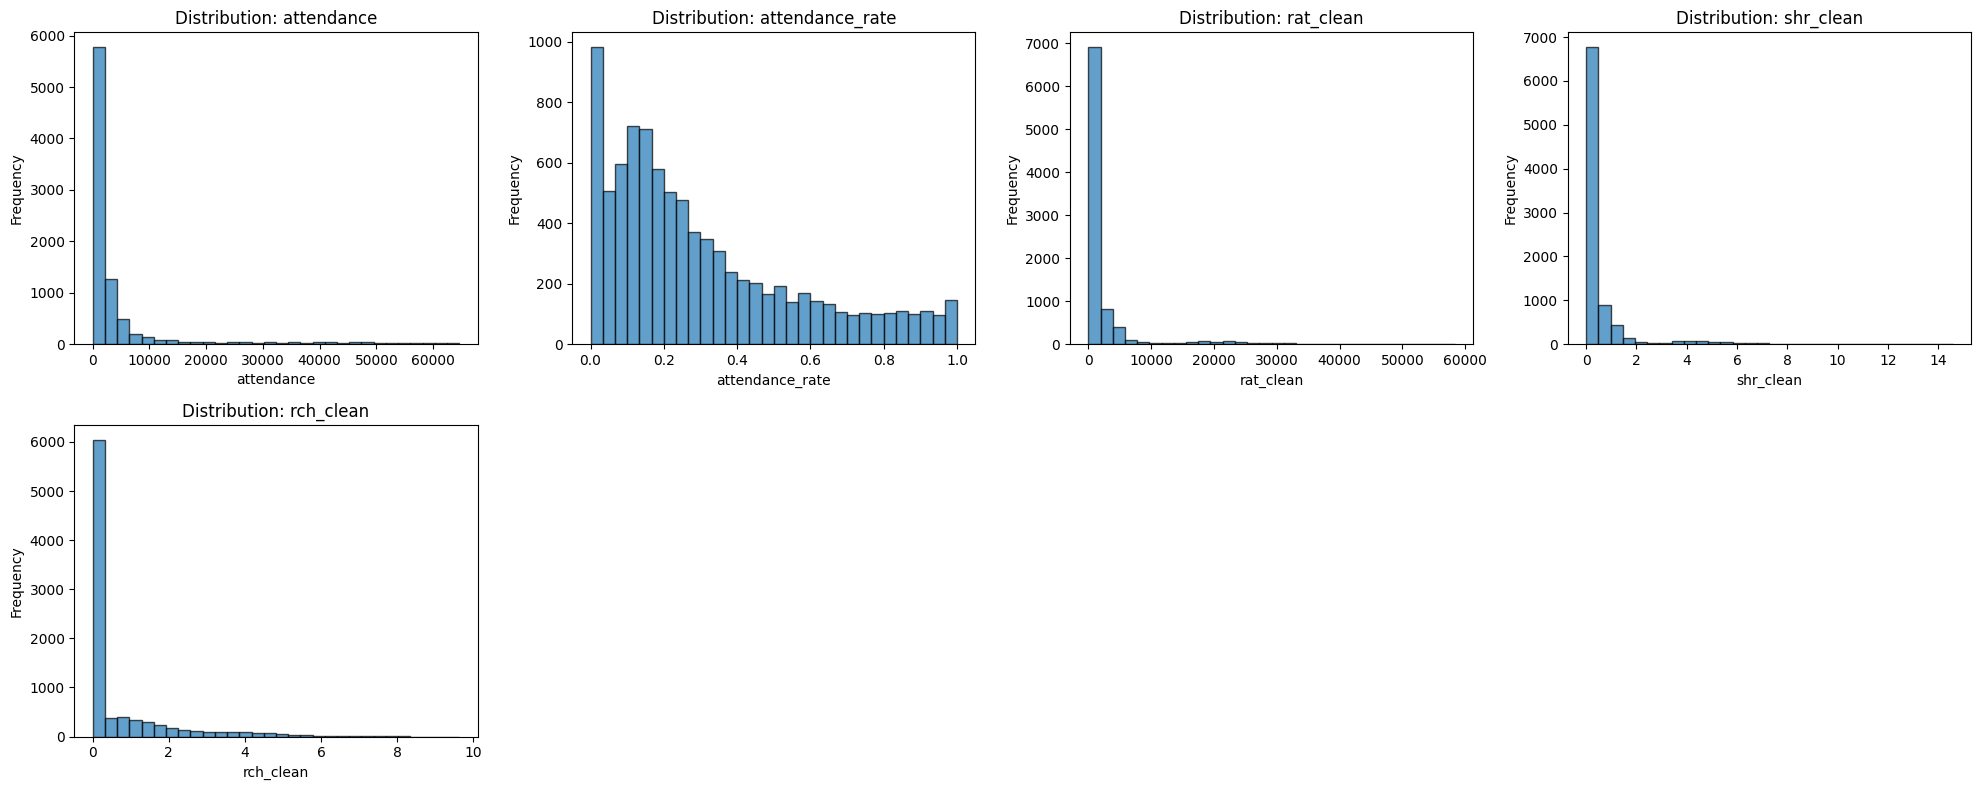

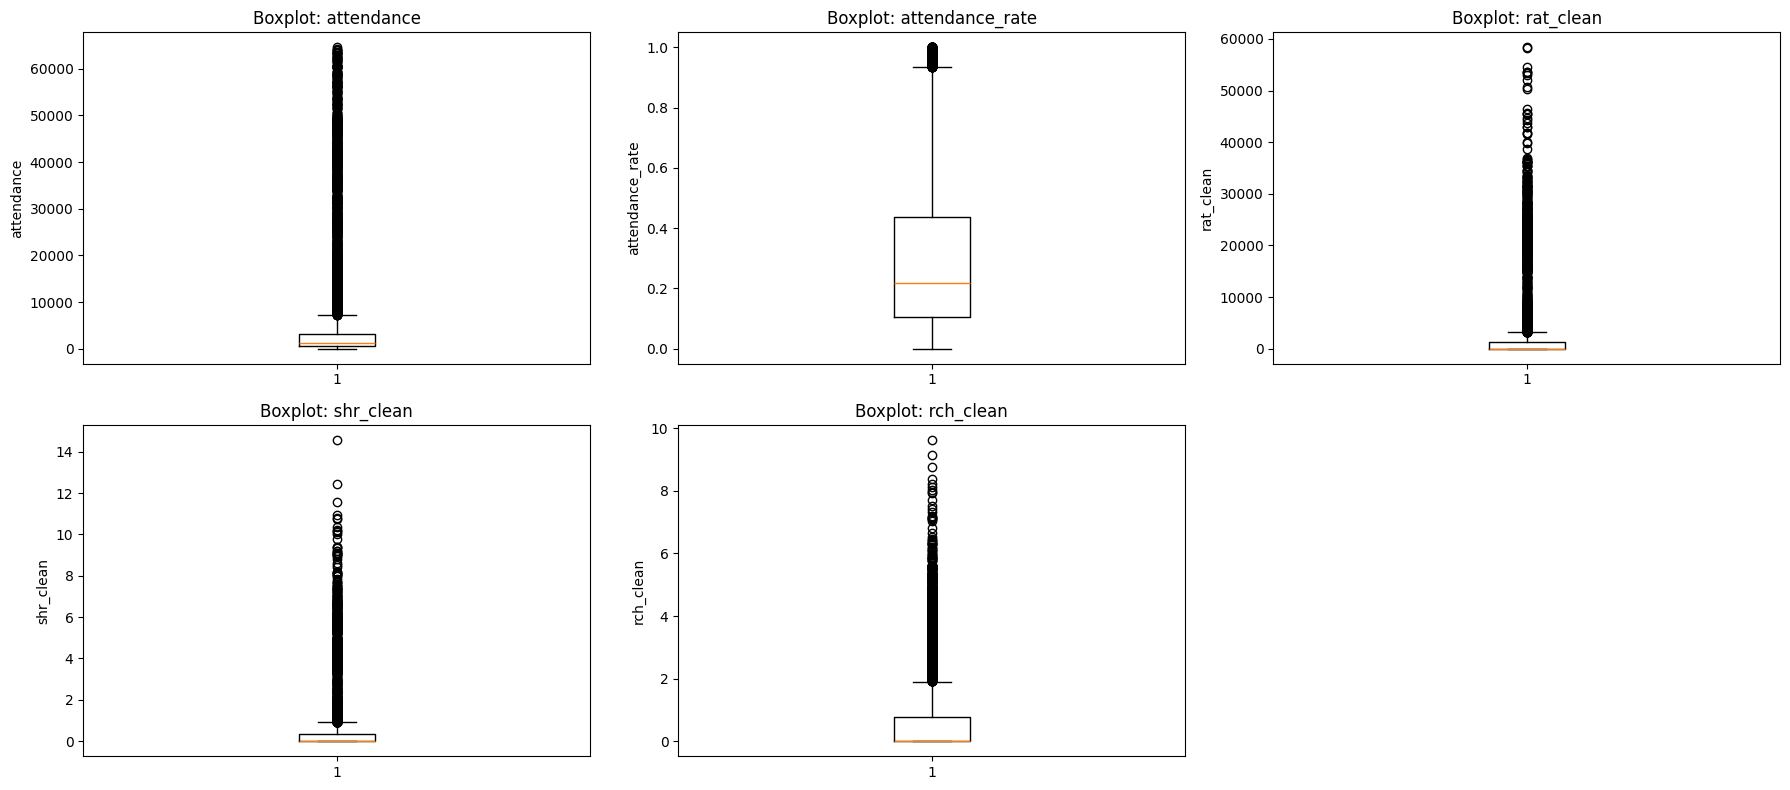

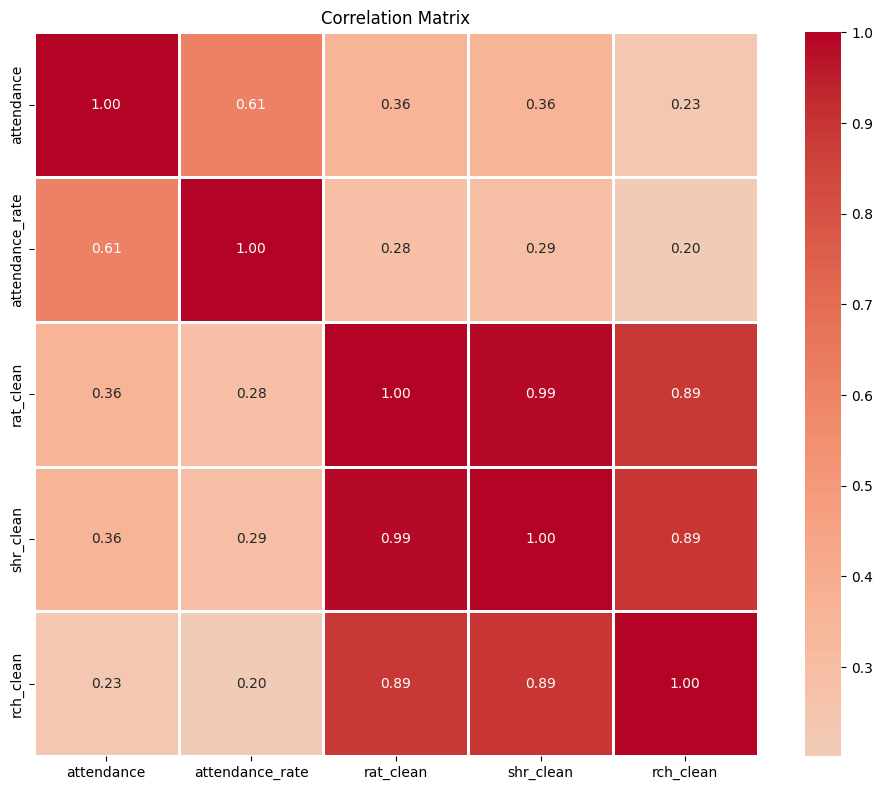

In [176]:
# Caraterizar as variáveis a preencher os valores em falta de Espetadores e TaxaOcupacao_decimal

mask_not_allianz = (df_merged_data['league'] != 'Allianz Cup')

da.quick_summary(df_merged_data[mask_not_allianz][['attendance', 'attendance_rate', 'rat_clean', 'shr_clean', 'rch_clean']])

In [177]:
#Define lower limits for filling missing values
spectator_lower_limit = 0
rat_lower_limit = 0
shr_lower_limit = 0
rch_lower_limit = 0
occupancy_rate_lower_limit = 0

In [178]:
# Create a mask for each metric being below its limit
low_spectators_mask = (df_merged_data['attendance'] <= spectator_lower_limit) | (df_merged_data['attendance'].isna())
low_spectator_percent = low_spectators_mask.sum() / len(df_merged_data) * 100
low_rat_mask = (df_merged_data['rat_clean'] <= rat_lower_limit) | (df_merged_data['rat_clean'].isna())
low_rat_percent = low_rat_mask.sum() / len(df_merged_data) * 100
low_shr_mask = (df_merged_data['shr_clean'] <= shr_lower_limit) | (df_merged_data['shr_clean'].isna())
low_shr_percent = low_shr_mask.sum() / len(df_merged_data) * 100
low_rch_mask = (df_merged_data['rch_clean'] <= rch_lower_limit) | (df_merged_data['rch_clean'].isna())
low_rch_percent = low_rch_mask.sum() / len(df_merged_data) * 100
low_occupancy_mask = (df_merged_data['attendance_rate'] <= occupancy_rate_lower_limit) \
                    | (df_merged_data['attendance_rate'].isna())
low_occupancy_percent = low_occupancy_mask.sum() / len(df_merged_data) * 100

# Combine all masks with OR operation
combined_mask = (low_spectators_mask | low_rat_mask | low_shr_mask | low_rch_mask | low_occupancy_mask)

# Filter the DataFrame and select relevant columns
columns_to_display = ['date_time', 'league_clean', 'home_team_clean', 'away_team_clean', 
                     'attendance', 'attendance_rate', 
                     'rat_clean', 'shr_clean', 'rch_clean']

low_metrics_df = df_merged_data[combined_mask][columns_to_display]

# Display summary statistics
logger_main.info(f"Estatísticas antes da substituição de valores abaixo do limite.")
logger_main.info(f"Total de registros com métricas baixas: {len(low_metrics_df)} ({(len(low_metrics_df) / len(df_merged_data) * 100):.2f}%)")
logger_main.info(f"Registos com Espetadores <= {spectator_lower_limit}: {low_spectators_mask.sum()}: ({low_spectators_mask.sum() / len(df_merged_data) * 100:.2f}%)")
logger_main.info(f"Registos com Rating <= {rat_lower_limit}: {low_rat_mask.sum()}: ({low_rat_mask.sum() / len(df_merged_data) * 100:.2f}%)")
logger_main.info(f"Registos com Share <= {shr_lower_limit}: {low_shr_mask.sum()}: ({low_shr_mask.sum() / len(df_merged_data) * 100:.2f}%)")
logger_main.info(f"Registos com Reach <= {rch_lower_limit}: {low_rch_mask.sum()}: ({low_rch_mask.sum() / len(df_merged_data) * 100:.2f}%)")
logger_main.info(f"Registos com Taxa de ocupação <= {occupancy_rate_lower_limit}: {low_occupancy_mask.sum()}: ({low_occupancy_mask.sum() / len(df_merged_data) * 100:.2f}%)")

print(f"Total de registos com métricas baixas: {len(low_metrics_df)}")
print(f"\nDetalhes:")
print(f"Registos com Espetadores (<={spectator_lower_limit}): {low_spectators_mask.sum()}: ({low_spectators_mask.sum() / len(df_merged_data) * 100:.2f}%)")
print(f"Registos com Rating (<={rat_lower_limit}): {low_rat_mask.sum()}: ({low_rat_mask.sum() / len(df_merged_data) * 100:.2f}%)")
print(f"Registos com Share (<={shr_lower_limit}): {low_shr_mask.sum()}: ({low_shr_mask.sum() / len(df_merged_data) * 100:.2f}%)")
print(f"Registos com Reach (<={rch_lower_limit}): {low_rch_mask.sum()}: ({low_rch_mask.sum() / len(df_merged_data) * 100:.2f}%)")
print(f"Registos com Taxa de ocupação (<={occupancy_rate_lower_limit}): {low_occupancy_mask.sum()}: ({low_occupancy_mask.sum() / len(df_merged_data) * 100:.2f}%)")

# Display the filtered DataFrame
display(low_metrics_df)

del low_spectators_mask, low_rat_mask, low_shr_mask, low_rch_mask, low_occupancy_mask, combined_mask, low_metrics_df  # Free memory
del low_spectator_percent, low_rat_percent, low_shr_percent, low_rch_percent, low_occupancy_percent

Total de registos com métricas baixas: 7342

Detalhes:
Registos com Espetadores (<=0): 721: (7.48%)
Registos com Rating (<=0): 6800: (70.58%)
Registos com Share (<=0): 6802: (70.60%)
Registos com Reach (<=0): 6800: (70.58%)
Registos com Taxa de ocupação (<=0): 721: (7.48%)


,date_time,league_clean,home_team_clean,away_team_clean,attendance,attendance_rate,rat_clean,shr_clean,rch_clean
0,2007-08-12 19:45:00+00:00,allianz_cup,beiramar,boavista_fc,1218,0.040429,0.0,0.0,0.00
1,2008-01-09 19:30:00+00:00,allianz_cup,beiramar,fc_penafiel,404,0.013410,0.0,0.0,0.00
2,2007-09-26 19:00:00+00:00,allianz_cup,beiramar,fc_pferreira,591,0.019617,0.0,0.0,0.00
3,2007-10-31 20:00:00+00:00,allianz_cup,beiramar,portimonense,658,0.021841,0.0,0.0,0.00
4,2007-08-04 17:00:00+00:00,allianz_cup,cd_trofense,cd_feirense,622,0.113091,0.0,0.0,0.00
...,...,...,...,...,...,...,...,...,...
9315,2024-05-12 11:00:00+00:00,liga_portugal_meu_super,leixoes_sc,afs,1542,0.295100,0.0,0.0,0.00
9320,2024-05-19 11:00:00+00:00,liga_portugal_meu_super,afs,cd_tondela,1230,0.235300,0.0,0.0,0.00
9506,2025-02-01 18:00:00+00:00,liga_portugal_meu_super,portimonense,cd_mafra,1073,0.212500,17.0,0.0,0.04
9517,2025-02-15 15:30:00+00:00,liga_portugal_meu_super,cd_tondela,cd_mafra,1674,0.347200,0.0,0.0,0.00


In [179]:
# Fill spectator missing or zero values
stats = dc.fill_missing_by_group(
    df=df_merged_data,
    group_cols=['home_team_clean', 'away_team_clean'],
    target_col='attendance',
    lower_limit=spectator_lower_limit,
    fill_method='median',
    consider_inverse_matches=True,
    estadio_jogo_col = 'home_stadium',
    estadio_casa_col = 'away_stadium', 
    as_int=True,
    verbose=True,
    inplace=True
)


# Fill Rat rating missing or zero values
stats = dc.fill_missing_by_group(
    df=df_merged_data,
    group_cols=['home_team_clean', 'away_team_clean'],
    target_col='rat_clean',
    lower_limit=rat_lower_limit,
    consider_nans=True,
    fill_method='median',
    consider_inverse_matches=True,
    verbose=True,
    inplace=True
)

# Fill Shr rating missing or zero values
stats = dc.fill_missing_by_group(
    df=df_merged_data,
    group_cols=['home_team_clean', 'away_team_clean'],
    target_col='shr_clean',
    lower_limit=shr_lower_limit,
    fill_method='median',
    consider_nans=True,
    consider_inverse_matches=True,
    verbose=True,
    inplace=True
)

# Fill Rch rating missing or zero values
stats = dc.fill_missing_by_group(
    df=df_merged_data,
    group_cols=['home_team_clean', 'away_team_clean'],
    target_col='rch_clean',
    lower_limit=rch_lower_limit,
    fill_method='median',
    consider_nans=True,
    consider_inverse_matches=True,
    verbose=True,
    inplace=True
)


Jogos com estádio igual: 8 / 9634
fill_missing_by_group summary (inplace):
  initial_candidates: 721
  num_candidates: 740
  num_filled_from_group: 731
  num_filled_from_fallback: 9
  num_filled: 740
  num_unfilled_groups: 0
  global_fallback: 0
fill_missing_by_group summary (inplace):
  initial_candidates: 6800
  num_candidates: 10218
  num_filled_from_group: 6962
  num_filled_from_fallback: 3256
  num_filled: 10218
  num_unfilled_groups: 0
  global_fallback: 0
fill_missing_by_group summary (inplace):
  initial_candidates: 6802
  num_candidates: 10219
  num_filled_from_group: 6963
  num_filled_from_fallback: 3256
  num_filled: 10219
  num_unfilled_groups: 0
  global_fallback: 0
fill_missing_by_group summary (inplace):
  initial_candidates: 6800
  num_candidates: 10218
  num_filled_from_group: 6962
  num_filled_from_fallback: 3256
  num_filled: 10218
  num_unfilled_groups: 0
  global_fallback: 0


QUICK DATA SUMMARY
Shape: (8766, 5)
Memory usage: 0.40 MB

Data Types:
float64    4
int64      1
Name: count, dtype: int64

Missing Values:
Empty DataFrame
Columns: [Missing Count, Missing %]
Index: []

Numeric Columns Summary:
         attendance  attendance_rate     rat_clean    shr_clean    rch_clean
count   8766.000000      8766.000000   8766.000000  8766.000000  8766.000000
mean    5380.245836         0.299652   7720.765971     1.757453     1.968408
std    11052.814404         0.261278  10150.767943     2.204014     1.711984
min        0.000000         0.000000      0.000000     0.000000     0.000000
25%      630.000000         0.104800   1287.000000     0.360000     0.800000
50%     1368.500000         0.218600   3123.500000     0.770000     1.470000
75%     3652.000000         0.436400  11863.000000     2.502500     3.225000
max    64591.000000         1.000000  58353.000000    14.570000     9.630000

Generating exploratory plots...


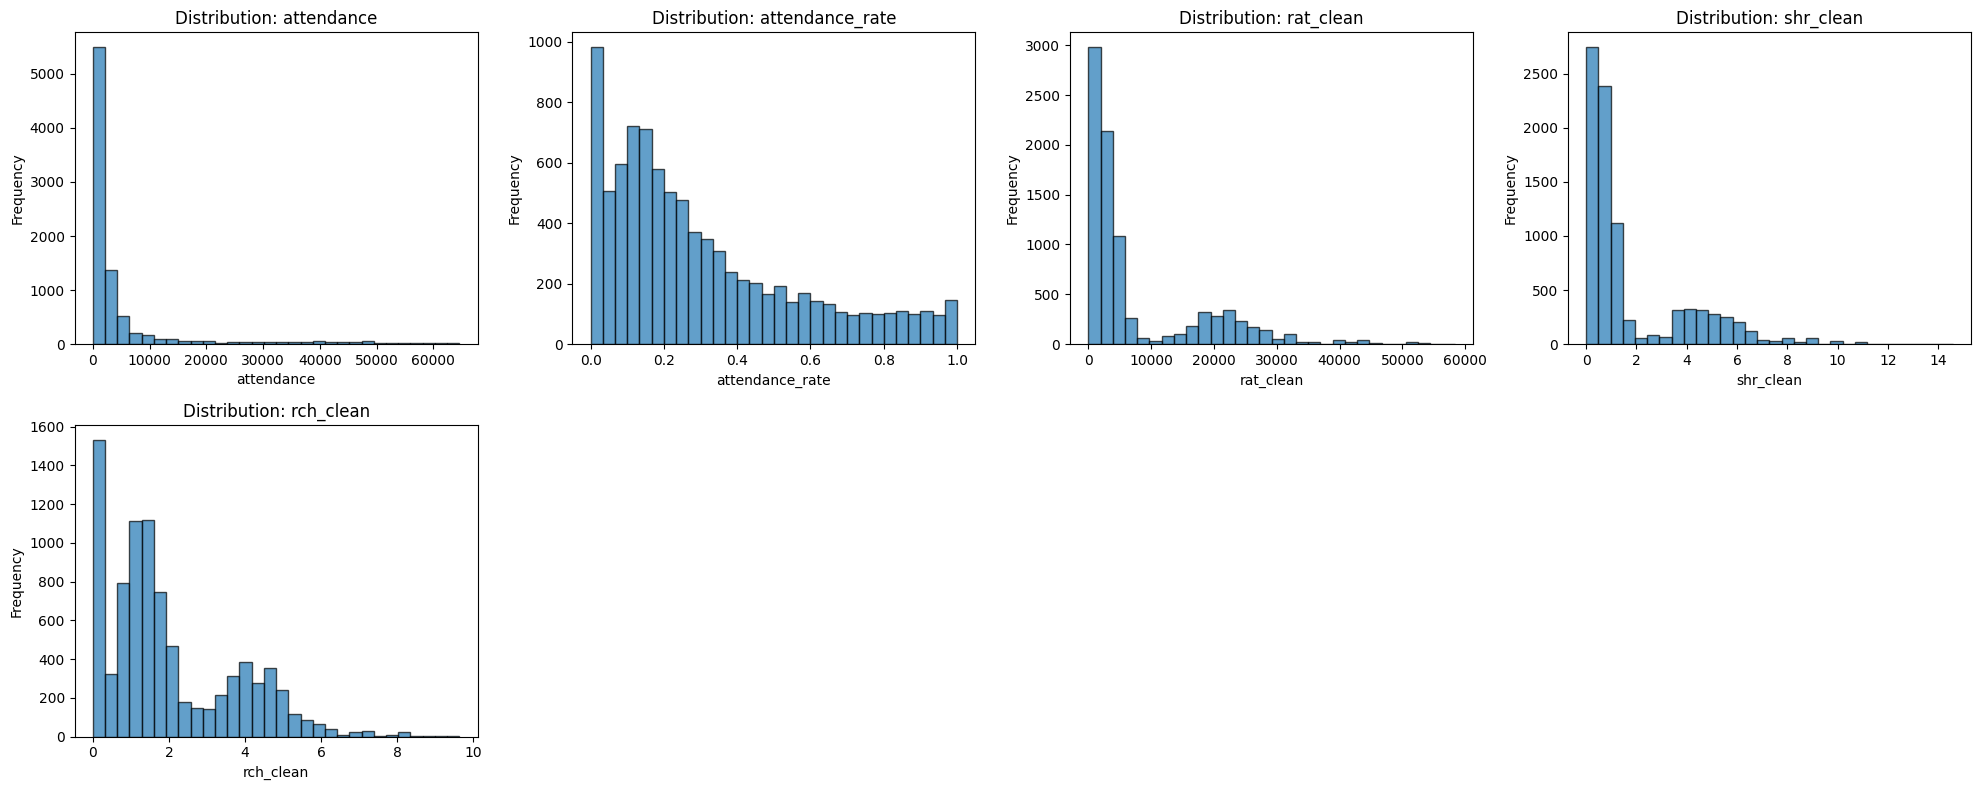

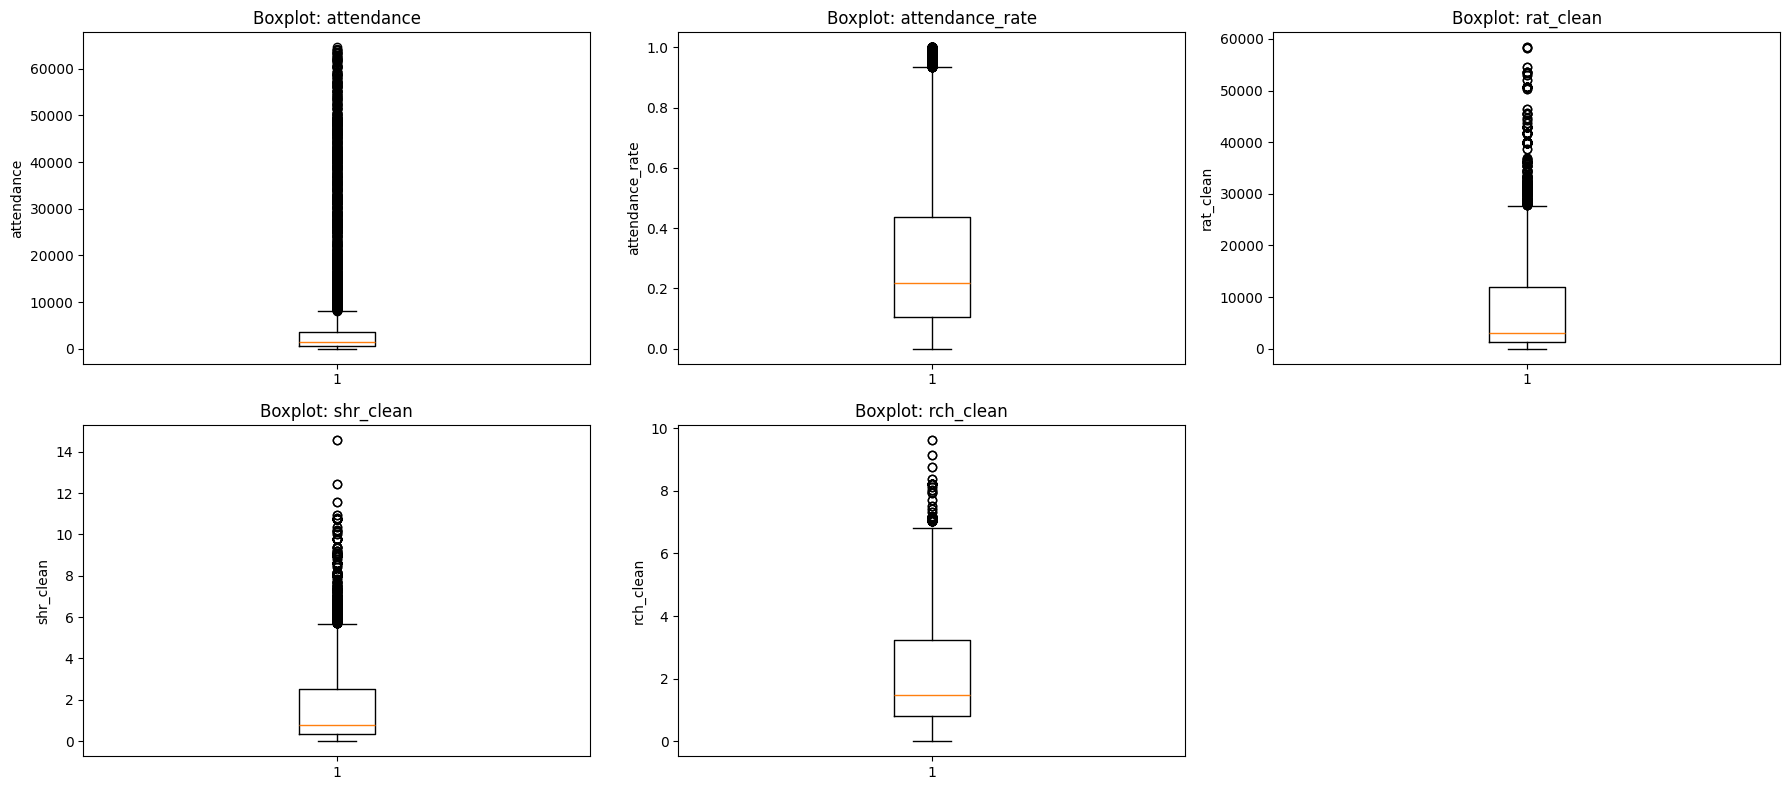

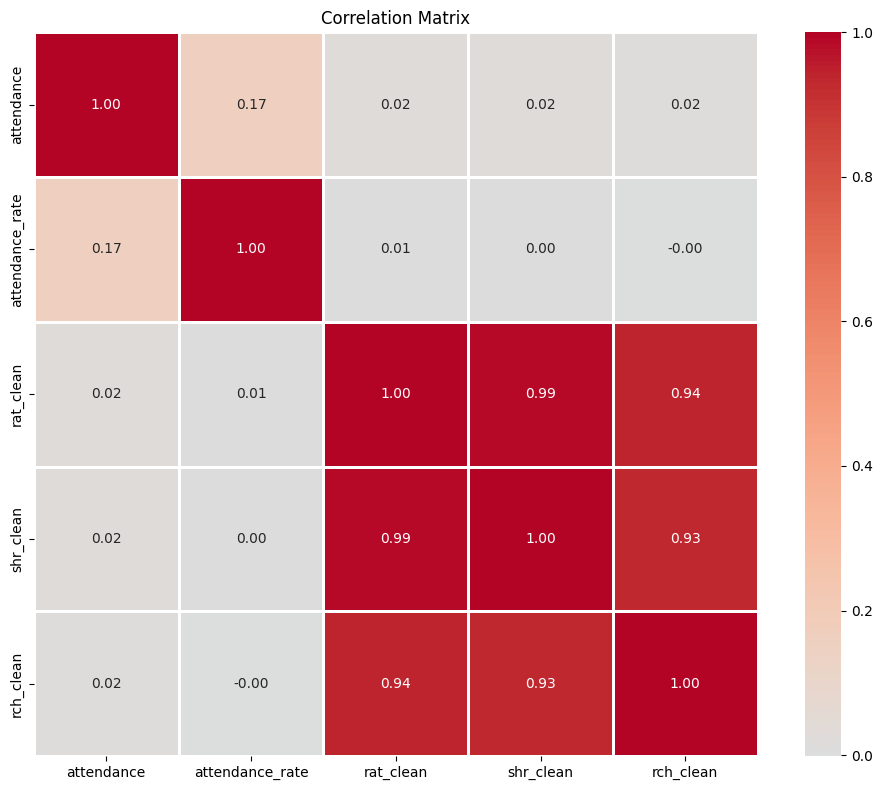

In [180]:
# Caraterizar as variáveis a preencher os valores em falta de Espetadores e TaxaOcupacao_decimal

mask_not_allianz = (df_merged_data['league'] != 'Allianz Cup')

da.quick_summary(df_merged_data[mask_not_allianz][['attendance', 'attendance_rate', 'rat_clean', 'shr_clean', 'rch_clean']])

In [181]:
# Create a mask for each metric being below its limit
low_spectators_mask = (df_merged_data['attendance'] <= spectator_lower_limit) | (df_merged_data['attendance'].isna())
low_spectator_percent = low_spectators_mask.sum() / len(df_merged_data) * 100
low_rat_mask = (df_merged_data['rat_clean'] <= rat_lower_limit) | (df_merged_data['rat_clean'].isna())
low_rat_percent = low_rat_mask.sum() / len(df_merged_data) * 100
low_shr_mask = (df_merged_data['shr_clean'] <= shr_lower_limit) | (df_merged_data['shr_clean'].isna())
low_shr_percent = low_shr_mask.sum() / len(df_merged_data) * 100
low_rch_mask = (df_merged_data['rch_clean'] <= rch_lower_limit) | (df_merged_data['rch_clean'].isna())
low_rch_percent = low_rch_mask.sum() / len(df_merged_data) * 100
low_occupancy_mask = (df_merged_data['attendance_rate'] <= occupancy_rate_lower_limit) \
                    | (df_merged_data['attendance_rate'].isna())
low_occupancy_percent = low_occupancy_mask.sum() / len(df_merged_data) * 100

# Combine all masks with OR operation
combined_mask = (low_spectators_mask | low_rat_mask | low_shr_mask | low_rch_mask | low_occupancy_mask)

# Filter the DataFrame and select relevant columns
columns_to_display = ['date_time', 'league_clean', 'home_team_clean', 'away_team_clean', 
                     'attendance', 'attendance_rate', 
                     'rat_clean', 'shr_clean', 'rch_clean']

low_metrics_df = df_merged_data[combined_mask][columns_to_display]

# Display summary statistics
logger_main.info(f"Estatísticas depois da substituição de valores abaixo do limite.")
logger_main.info(f"Total de registros com métricas baixas: {len(low_metrics_df)} ({(len(low_metrics_df) / len(df_merged_data) * 100):.2f}%)")
logger_main.info(f"Registos com Espetadores <= {spectator_lower_limit}: {low_spectators_mask.sum()}: ({low_spectators_mask.sum() / len(df_merged_data) * 100:.2f}%)")
logger_main.info(f"Registos com Rating <= {rat_lower_limit}: {low_rat_mask.sum()}: ({low_rat_mask.sum() / len(df_merged_data) * 100:.2f}%)")
logger_main.info(f"Registos com Share <= {shr_lower_limit}: {low_shr_mask.sum()}: ({low_shr_mask.sum() / len(df_merged_data) * 100:.2f}%)")
logger_main.info(f"Registos com Reach <= {rch_lower_limit}: {low_rch_mask.sum()}: ({low_rch_mask.sum() / len(df_merged_data) * 100:.2f}%)")
logger_main.info(f"Registos com Taxa de ocupação <= {occupancy_rate_lower_limit}: {low_occupancy_mask.sum()}: ({low_occupancy_mask.sum() / len(df_merged_data) * 100:.2f}%)")

print(f"Total de registos com métricas baixas: {len(low_metrics_df)}")
print(f"\nDetalhes:")
print(f"Registos com Espetadores (<={spectator_lower_limit}): {low_spectators_mask.sum()}: ({low_spectators_mask.sum() / len(df_merged_data) * 100:.2f}%)")
print(f"Registos com Rating (<={rat_lower_limit}): {low_rat_mask.sum()}: ({low_rat_mask.sum() / len(df_merged_data) * 100:.2f}%)")
print(f"Registos com Share (<={shr_lower_limit}): {low_shr_mask.sum()}: ({low_shr_mask.sum() / len(df_merged_data) * 100:.2f}%)")
print(f"Registos com Reach (<={rch_lower_limit}): {low_rch_mask.sum()}: ({low_rch_mask.sum() / len(df_merged_data) * 100:.2f}%)")
print(f"Registos com Taxa de ocupação (<={occupancy_rate_lower_limit}): {low_occupancy_mask.sum()}: ({low_occupancy_mask.sum() / len(df_merged_data) * 100:.2f}%)")

# Display the filtered DataFrame
display(low_metrics_df)

del low_spectators_mask, low_rat_mask, low_shr_mask, low_rch_mask, low_occupancy_mask, combined_mask, low_metrics_df  # Free memory
del low_spectator_percent, low_rat_percent, low_shr_percent, low_rch_percent, low_occupancy_percent

Total de registos com métricas baixas: 2380

Detalhes:
Registos com Espetadores (<=0): 9: (0.09%)
Registos com Rating (<=0): 1801: (18.69%)
Registos com Share (<=0): 1801: (18.69%)
Registos com Reach (<=0): 1801: (18.69%)
Registos com Taxa de ocupação (<=0): 721: (7.48%)


,date_time,league_clean,home_team_clean,away_team_clean,attendance,attendance_rate,rat_clean,shr_clean,rch_clean
0,2007-08-12 19:45:00+00:00,allianz_cup,beiramar,boavista_fc,1218,0.040429,0.0,0.0,0.0
1,2008-01-09 19:30:00+00:00,allianz_cup,beiramar,fc_penafiel,404,0.013410,0.0,0.0,0.0
2,2007-09-26 19:00:00+00:00,allianz_cup,beiramar,fc_pferreira,591,0.019617,0.0,0.0,0.0
3,2007-10-31 20:00:00+00:00,allianz_cup,beiramar,portimonense,658,0.021841,0.0,0.0,0.0
6,2007-08-05 16:00:00+00:00,allianz_cup,estoril_praia,cd_aves,252,0.031500,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...
9628,2025-05-17 14:00:00+00:00,liga_portugal_meu_super,fc_felgueiras,ud_oliveirense,2896,0.214100,0.0,0.0,0.0
9629,2025-05-15 18:45:00+00:00,liga_portugal_meu_super,fc_penafiel,gd_chaves,6125,0.104400,0.0,0.0,0.0
9630,2025-05-17 11:00:00+00:00,liga_portugal_meu_super,fc_porto_b,sl_benfica_b,771,0.214000,0.0,0.0,0.0
9631,2025-05-14 20:15:00+00:00,liga_portugal_meu_super,leixoes_sc,cd_feirense,553,0.295300,0.0,0.0,0.0


In [182]:
condicao = df_merged_data['attendance'] > (df_merged_data['game_stadium_capacity'])
display(df_merged_data[condicao].head())

,league_clean,season,round,home_team_clean,away_team_clean,date_time,attendance,attendance_rate,rat_clean,shr_clean,...,away_stadium_simple_region,game_stadium,game_stadium_clean,game_stadium_capacity,game_stadium_latitud,game_stadium_longitud,game_stadium_district,game_stadium_detailed_region,game_stadium_simple_region,game_stadium_timezone
10,allianz_cup,200708,<NA>,fatima,fc_porto,2007-09-26 18:00:00+00:00,2641,1.709385,30398.0,6.045,...,Norte,Estádio Centro Desportivo de Fátima,estadio_centro_desportivo_de_fatima,1545.0,39.603489,-8.663106,Santarém,Lezíria do Tejo,Centro,Europe/Lisbon
12,allianz_cup,200708,<NA>,fatima,sporting_cp,2007-10-31 19:45:00+00:00,4356,2.819417,0.0,0.000,...,Área Metropolitana de Lisboa,Estádio Centro Desportivo de Fátima,estadio_centro_desportivo_de_fatima,1545.0,39.603489,-8.663106,Santarém,Lezíria do Tejo,Centro,Europe/Lisbon
37,allianz_cup,200708,<NA>,vitoria_sc,sporting_cp,2007-09-26 20:45:00+00:00,33847,0.434941,0.0,0.000,...,Área Metropolitana de Lisboa,Estádio D. Afonso Henriques,estadio_d_afonso_henriques,30165.0,41.446925,-8.291746,Braga,Ave,Norte,Europe/Lisbon
55,allianz_cup,200809,<NA>,fc_vizela,cd_feirense,2008-08-09 17:00:00+00:00,12219,0.269143,0.0,0.000,...,Norte,Estádio Futebol Clube de Vizela,estadio_futebol_clube_de_vizela,3500.0,41.388771,-8.307334,Braga,Ave,Norte,Europe/Lisbon
70,allianz_cup,200809,<NA>,sc_covilha,gil_vicente_fc,2008-09-24 19:30:00+00:00,6057,0.216667,3534.5,0.685,...,Norte,Complexo Desportivo da Covilhã,complexo_desportivo_da_covilha,3000.0,40.264846,-7.497729,Castelo Branco,Beiras e Serra da Estrela,Centro,Europe/Lisbon


In [183]:
# Show records where occupancy rate is greater than 1
high_occupancy = df_merged_data[df_merged_data['attendance_rate'] > 1][['league_clean', 'home_team_clean', 'away_team_clean', 'attendance', 'game_stadium_capacity', 'attendance_rate', 'date_time']]
print("Records with occupancy rate > 1:")
display(high_occupancy.sort_values('attendance_rate', ascending=False))

Records with occupancy rate > 1:


,league_clean,home_team_clean,away_team_clean,attendance,game_stadium_capacity,attendance_rate,date_time
12,allianz_cup,fatima,sporting_cp,4356,1545.0,2.819417,2007-10-31 19:45:00+00:00
526,allianz_cup,maritimo_m,sl_benfica,521,10932.0,2.641603,2016-05-20 19:45:00+00:00
787,allianz_cup,fc_arouca,sporting_cp,497,5600.0,1.831964,2023-01-24 19:45:00+00:00
10,allianz_cup,fatima,fc_porto,2641,1545.0,1.709385,2007-09-26 18:00:00+00:00
36,allianz_cup,vitoria_fc,sporting_cp,10373,21530.0,1.572085,2008-01-09 21:15:00+00:00
635,allianz_cup,vitoria_fc,sporting_cp,336,21530.0,1.121087,2018-01-27 20:45:00+00:00
565,allianz_cup,fc_vizela,vitoria_sc,2154,3500.0,1.108000,2016-12-30 19:15:00+00:00
648,allianz_cup,cd_feirense,sporting_cp,6319,5000.0,1.088000,2018-12-29 19:45:00+00:00


QUICK DATA SUMMARY
Shape: (9634, 44)
Memory usage: 19.64 MB

Data Types:
object                 28
float64                11
Int64                   2
int64                   2
datetime64[ns, UTC]     1
Name: count, dtype: int64

Missing Values:
              Missing Count  Missing %
round                   868   9.009757
date_time                20   0.207598
weekday_name             20   0.207598
weekday_num              20   0.207598
hour                     20   0.207598
date                     20   0.207598

Numeric Columns Summary:
           round    attendance  attendance_rate     rat_clean    shr_clean  \
count     8766.0   9634.000000      9634.000000   9634.000000  9634.000000   
mean    18.73979   5229.908449         0.288917   7502.278493     1.709825   
std    10.934277  10758.519788         0.261083  10102.929710     2.196024   
min          1.0      0.000000         0.000000      0.000000     0.000000   
25%          9.0    611.000000         0.096000   1061.000000    

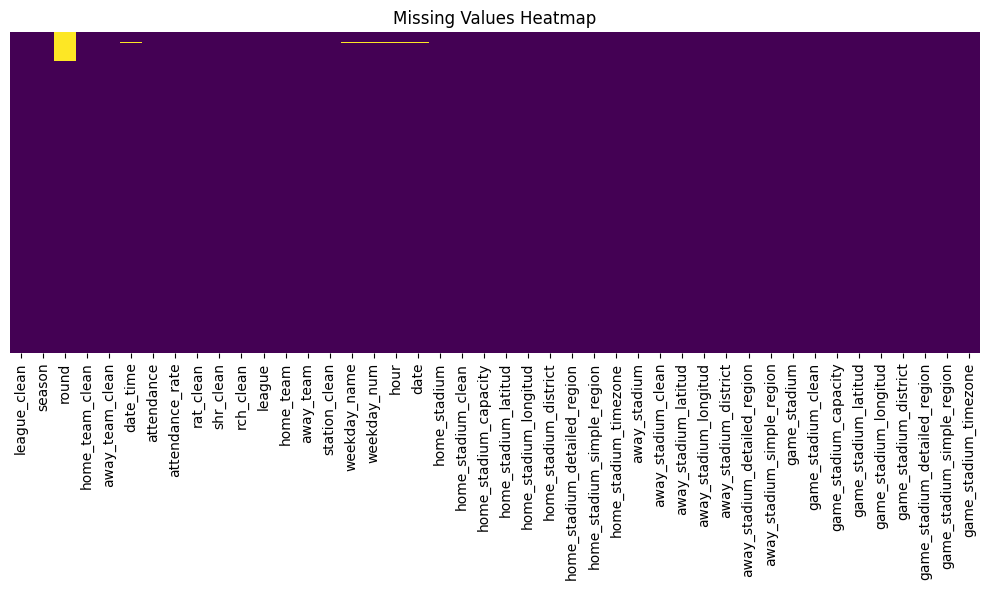

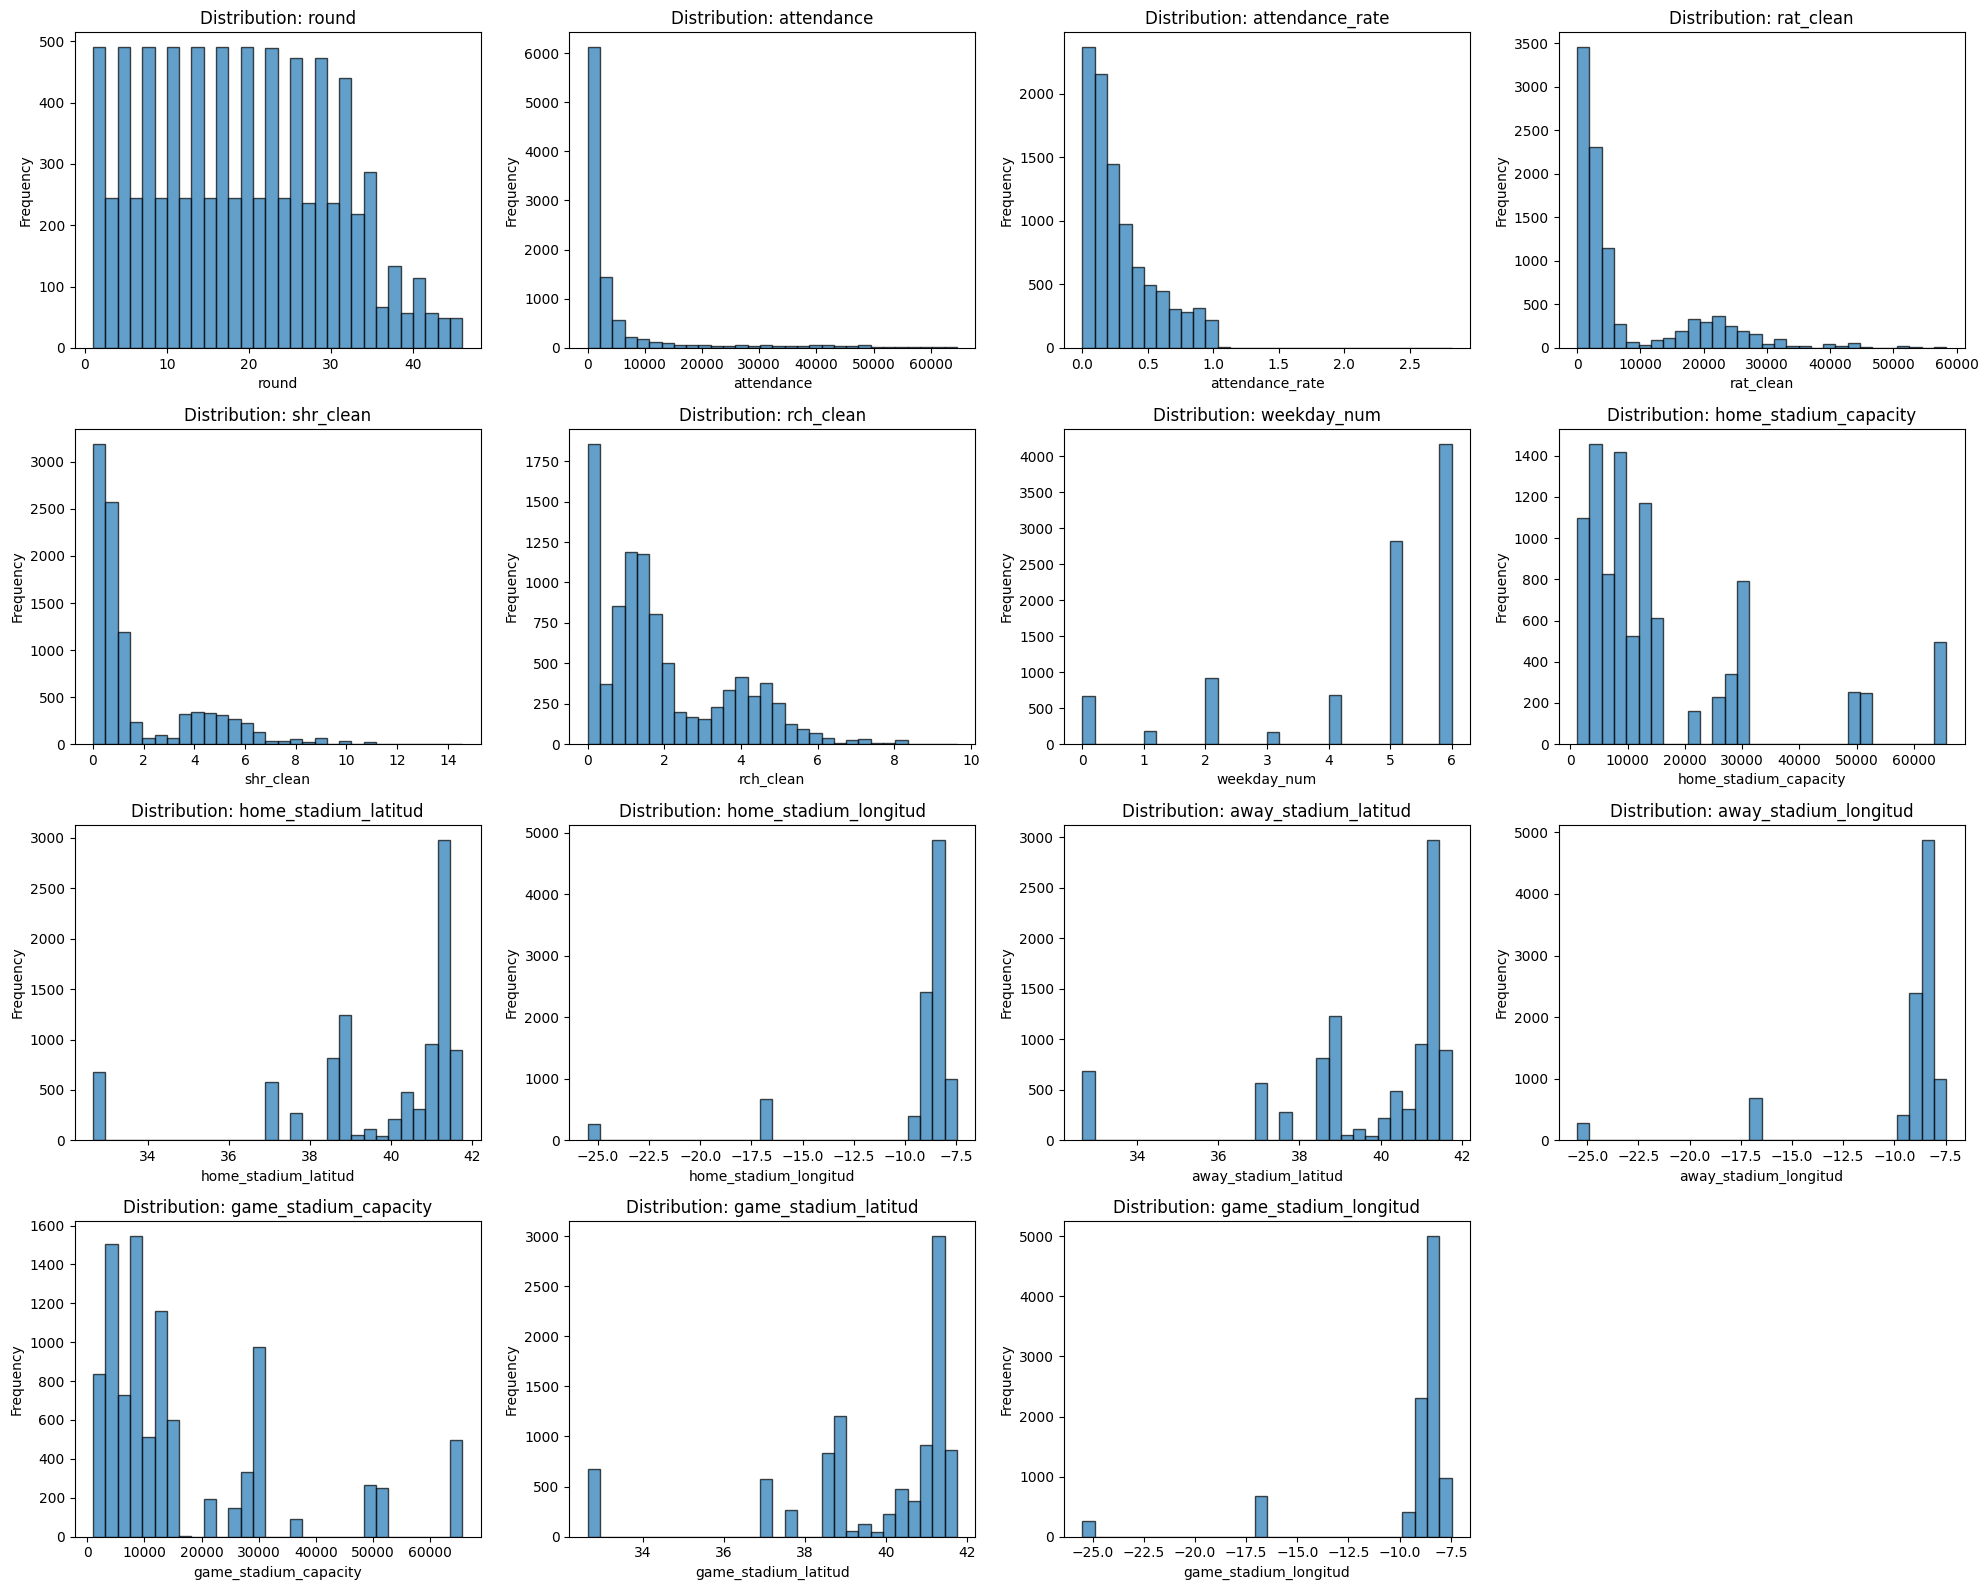

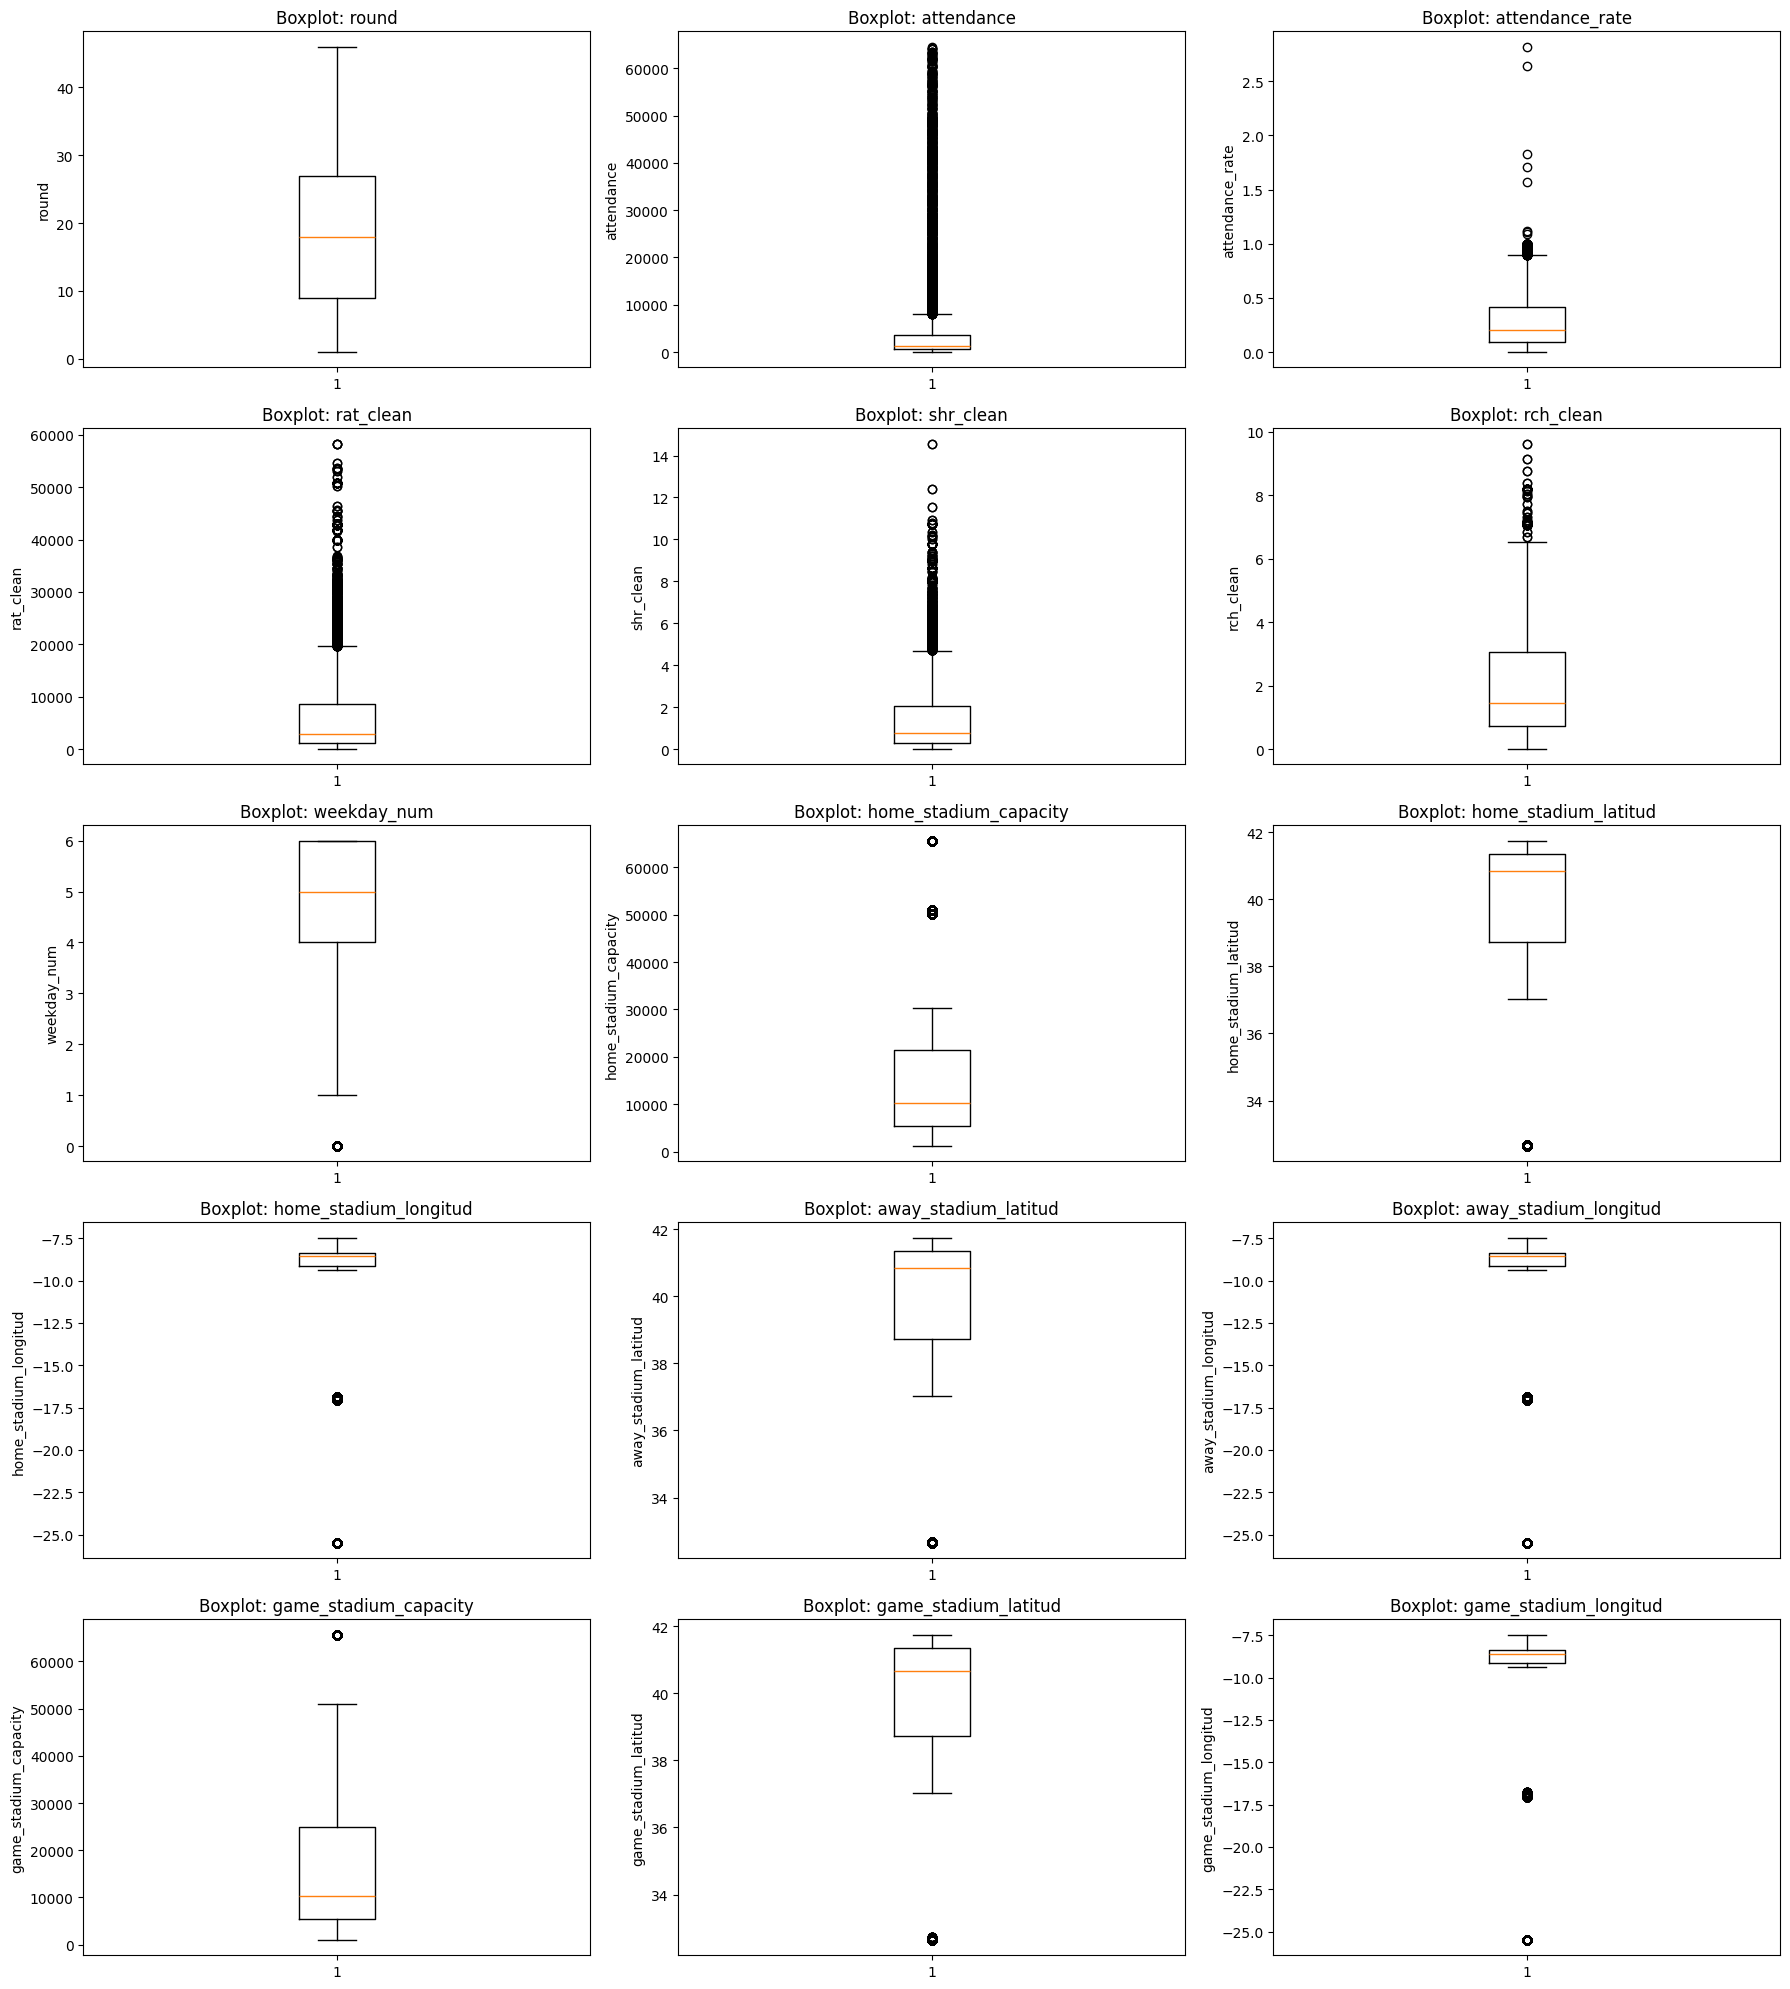

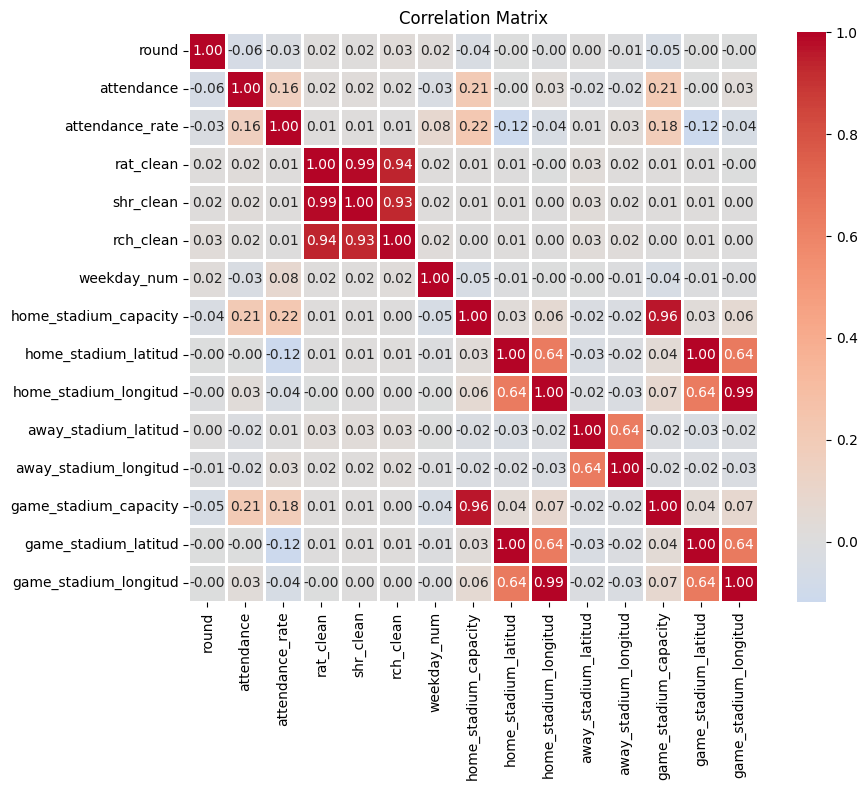

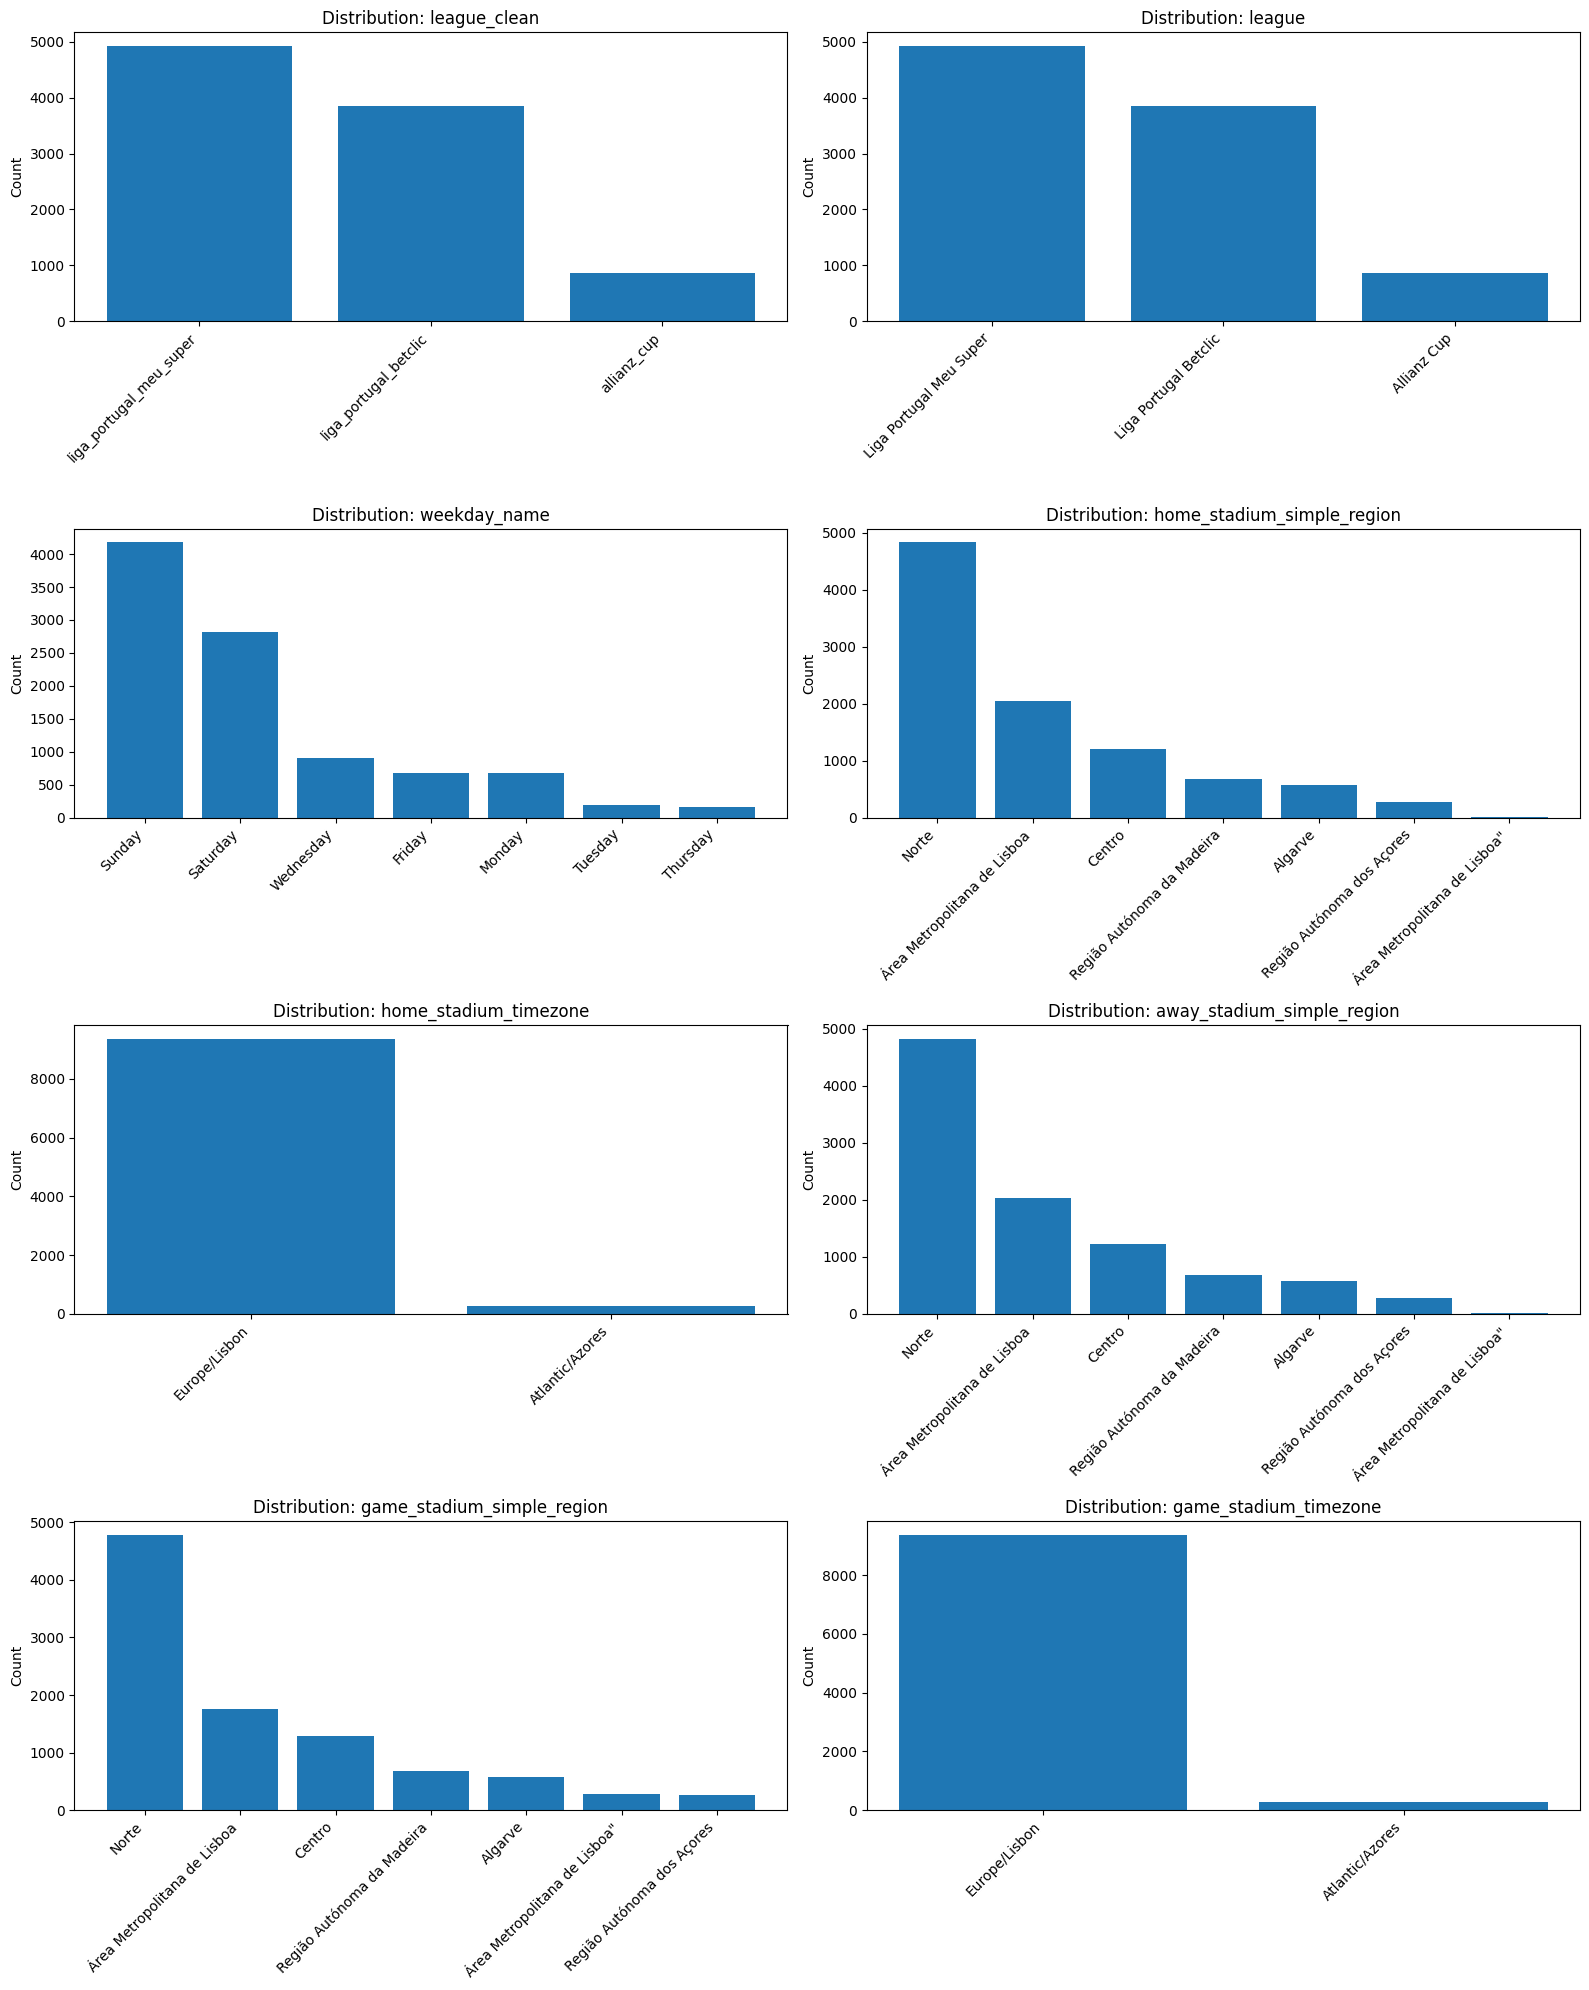

In [184]:
da.quick_summary(df_merged_data)  # type: ignore

QUICK DATA SUMMARY
Shape: (8766, 5)
Memory usage: 0.40 MB

Data Types:
float64    4
int64      1
Name: count, dtype: int64

Missing Values:
Empty DataFrame
Columns: [Missing Count, Missing %]
Index: []

Numeric Columns Summary:
         attendance  attendance_rate     rat_clean    shr_clean    rch_clean
count   8766.000000      8766.000000   8766.000000  8766.000000  8766.000000
mean    5380.245836         0.299652   7720.765971     1.757453     1.968408
std    11052.814404         0.261278  10150.767943     2.204014     1.711984
min        0.000000         0.000000      0.000000     0.000000     0.000000
25%      630.000000         0.104800   1287.000000     0.360000     0.800000
50%     1368.500000         0.218600   3123.500000     0.770000     1.470000
75%     3652.000000         0.436400  11863.000000     2.502500     3.225000
max    64591.000000         1.000000  58353.000000    14.570000     9.630000

Generating exploratory plots...


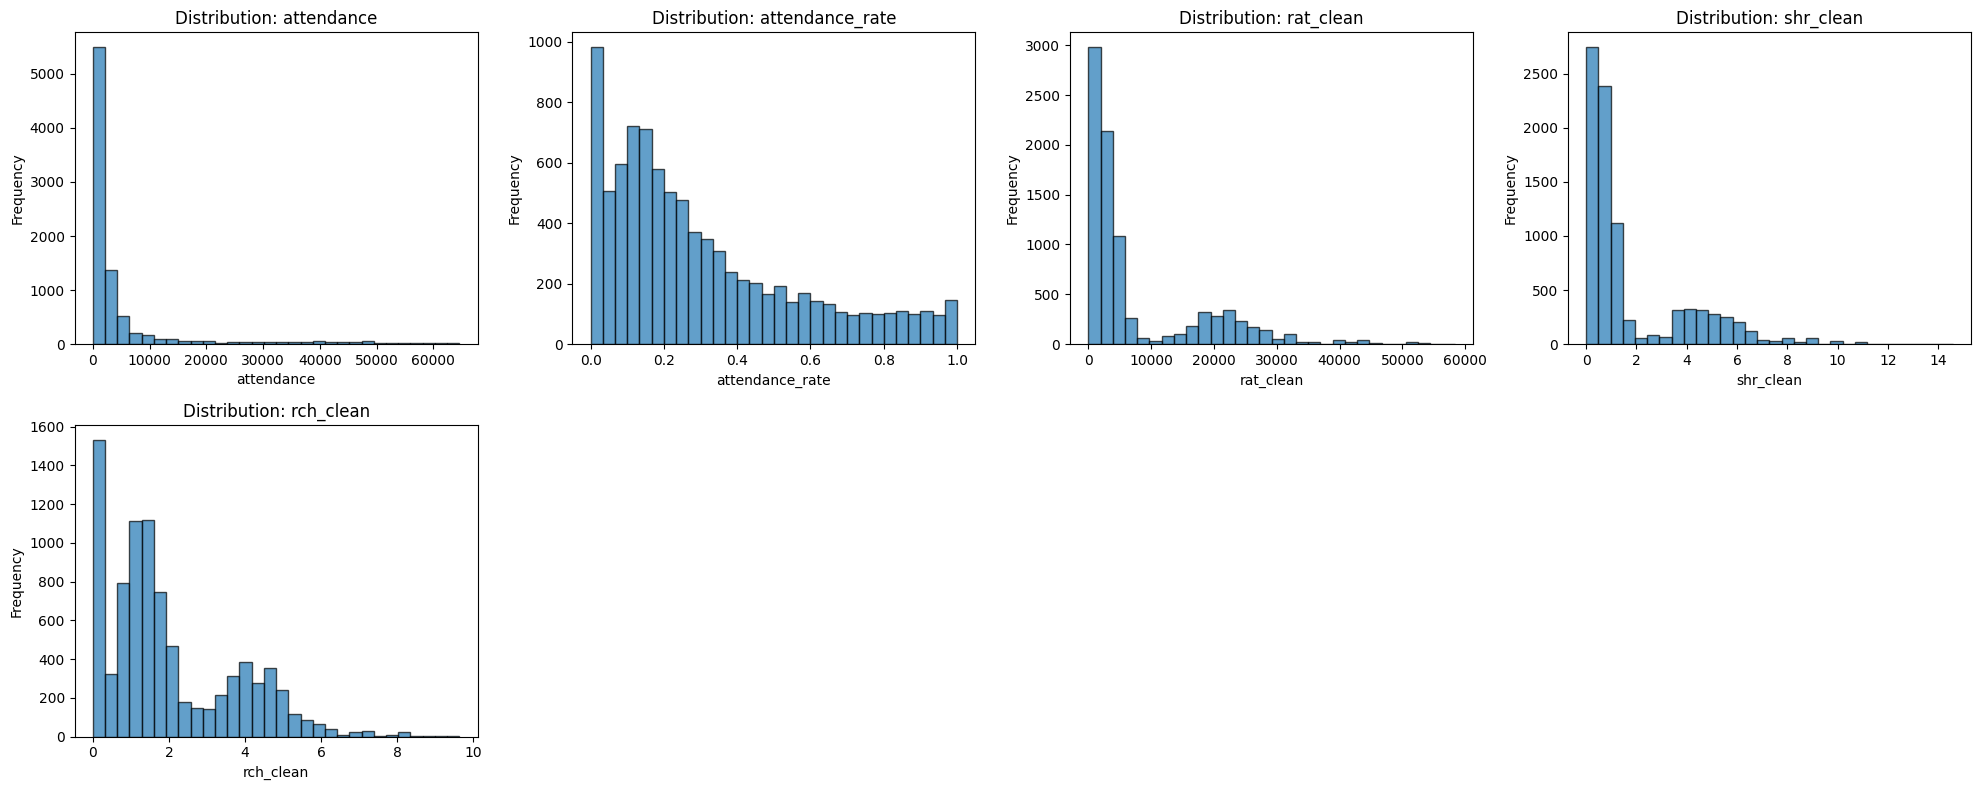

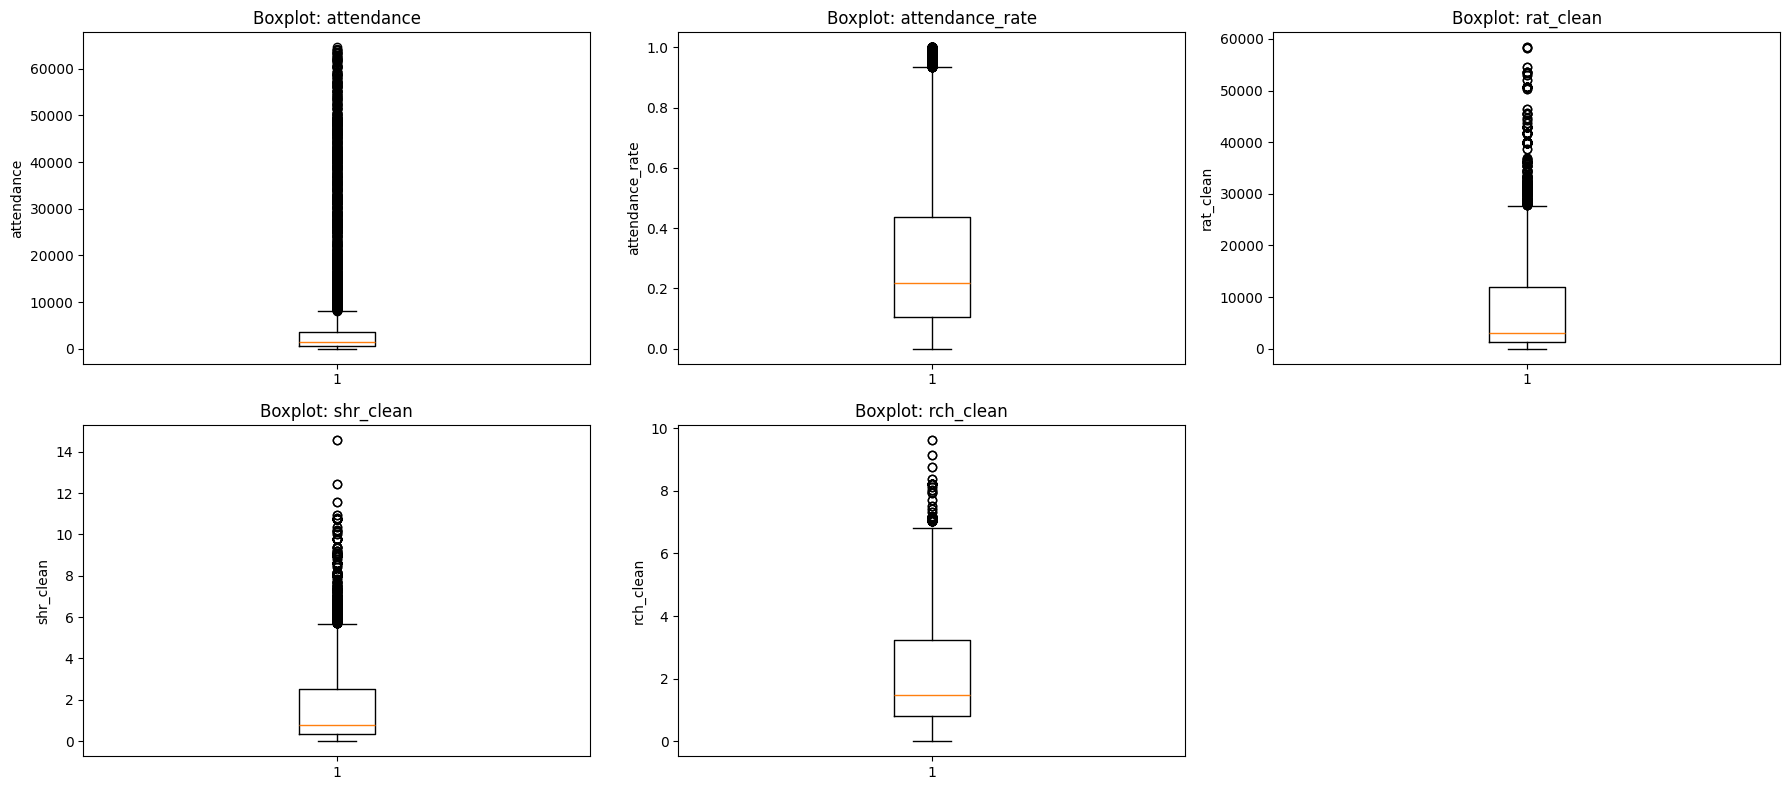

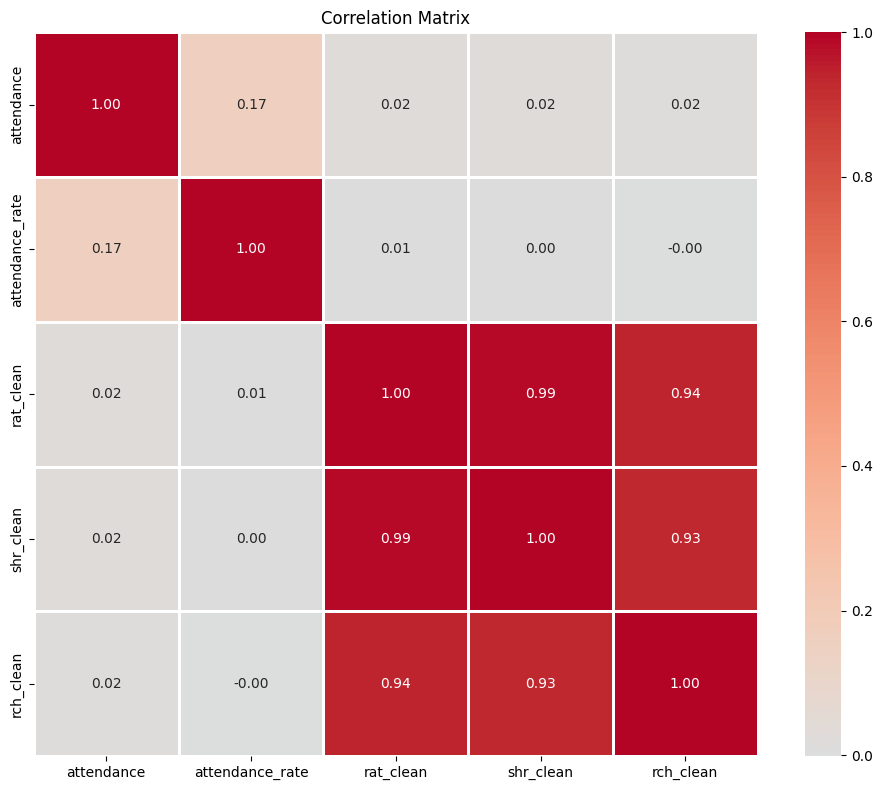

In [185]:
mask_not_allianz = (df_merged_data['league'] != 'Allianz Cup')

da.quick_summary(df_merged_data[mask_not_allianz][['attendance', 'attendance_rate', 'rat_clean', 'shr_clean', 'rch_clean']])

In [186]:
df_merged_data.dropna(subset=['date_time'], inplace=True)

In [187]:
# Agrupa por região e lista os clubes em cada região
clubes_por_regiao = df_merged_data.groupby('home_district')['home_team'].apply(list).reset_index()

# Exibe o resultado sem duplicados
print("\nClubes listados por Distrito:")
for index, row in clubes_por_regiao.iterrows():
    print(f"\nRegião: {row['home_district']}")
    # Converte a lista para um set para remover duplicados e depois de volta para uma lista para exibir
    clubes_unicos = sorted(list(set(row['home_team'])))
    for clube in clubes_unicos:
        print(f"   - {clube}")

del clubes_por_regiao  # Free memory

KeyError: 'home_district'

In [ ]:
df_processed = df_merged_data.copy()

del df_merged_data  # Free memory

display(df_processed.head(10))

,league_clean,season,round,home_team_clean,away_team_clean,date_time,attendance,attendance_rate,rat_clean,shr_clean,...,away_simple_region,game_stadium,game_stadium_clean,game_stadium_capacity,game_stadium_latitud,game_stadium_longitud,game_stadium_district,game_stadium_detailed_region,game_stadium_simple_region,game_stadium_timezone
0,allianz_cup,200708,<NA>,beiramar,boavista_fc,2007-08-12 19:45:00+00:00,1218,0.040429,0.0,0.000,...,Norte,NaN,NaN,30127.0,40.647935,-8.593699,Aveiro,Região de Aveiro,Centro,Europe/Lisbon
1,allianz_cup,200708,<NA>,beiramar,fc_penafiel,2008-01-09 19:30:00+00:00,404,0.013410,0.0,0.000,...,Norte,NaN,NaN,30127.0,40.647935,-8.593699,Aveiro,Região de Aveiro,Centro,Europe/Lisbon
2,allianz_cup,200708,<NA>,beiramar,fc_pferreira,2007-09-26 19:00:00+00:00,591,0.019617,0.0,0.000,...,Norte,NaN,NaN,30127.0,40.647935,-8.593699,Aveiro,Região de Aveiro,Centro,Europe/Lisbon
3,allianz_cup,200708,<NA>,beiramar,portimonense,2007-10-31 20:00:00+00:00,658,0.021841,0.0,0.000,...,Algarve,NaN,NaN,30127.0,40.647935,-8.593699,Aveiro,Região de Aveiro,Centro,Europe/Lisbon
4,allianz_cup,200708,<NA>,cd_trofense,cd_feirense,2007-08-04 17:00:00+00:00,622,0.113091,2162.5,0.580,...,Norte,NaN,NaN,5500.0,41.332180,-8.564484,Porto,Área Metropolitana do Porto,Norte,Europe/Lisbon
5,allianz_cup,200708,<NA>,cd_trofense,vitoria_sc,2007-08-12 18:00:00+00:00,2146,0.390182,1713.5,0.585,...,Norte,NaN,NaN,5500.0,41.332180,-8.564484,Porto,Área Metropolitana do Porto,Norte,Europe/Lisbon
6,allianz_cup,200708,<NA>,estoril_praia,cd_aves,2007-08-05 16:00:00+00:00,252,0.031500,0.0,0.000,...,Norte,NaN,NaN,8000.0,38.715188,-9.406336,Lisboa,Grande Lisboa,Área Metropolitana de Lisboa,Europe/Lisbon
7,allianz_cup,200708,<NA>,estoril_praia,estrela_amadora,2007-08-12 16:00:00+00:00,385,0.048125,0.0,0.000,...,Área Metropolitana de Lisboa,NaN,NaN,8000.0,38.715188,-9.406336,Lisboa,Grande Lisboa,Área Metropolitana de Lisboa,Europe/Lisbon
8,allianz_cup,200708,<NA>,estrela_amadora,sl_benfica,2007-09-26 20:30:00+00:00,2333,0.251184,1703.0,0.385,...,Área Metropolitana de Lisboa,NaN,NaN,9288.0,38.752024,-9.227897,Lisboa,Grande Lisboa,Área Metropolitana de Lisboa,Europe/Lisbon
9,allianz_cup,200708,<NA>,fatima,a_academica,2007-08-12 17:00:00+00:00,1250,0.809061,3887.0,0.860,...,Centro,NaN,NaN,1545.0,39.603489,-8.663106,Santarém,Lezíria do Tejo,Centro,Europe/Lisbon


In [ ]:
# Calcula a distância em km entre os estadios, recorre às coordenadas latitude e longitude (casa e fora)


logger_main.info("Cálculo da distância entre estádios iniciado.")
# Aplica a função para calcular a distância para cada linha do DataFrame
#df_processed['distancia_casa_jogo'] = df_processed.apply(dist.haversine_distance_from_row, axis=1)
# Com nomes de colunas personalizados
df_processed['home_game_distance'] = df_processed.apply(
    lambda r: dist.haversine_distance_from_row(
        r, 
        lat1_col='home_latitud', 
        lon1_col='home_longitud',
        lat2_col='game_stadium_latitud', 
        lon2_col='game_stadium_longitud'
    ), axis=1) # type: ignore

df_processed['away_game_distance'] = df_processed.apply(
    lambda r: dist.haversine_distance_from_row(
        r, 
        lat1_col='away_latitud', 
        lon1_col='away_longitud',
        lat2_col='game_stadium_latitud', 
        lon2_col='game_stadium_longitud'
    ), axis=1) # type: ignore

logger_main.info("Cálculo da distância entre estádios concluído.")

# Exibir as primeiras linhas com a nova coluna 'home_game_distance'
print("\nDataFrame com as colunas  novas 'home_game_distance' e 'away_game_distance':")
print(df_processed[['season', 'date_time', 'home_team_clean', 'away_team_clean', 'home_latitud', 'home_longitud', 'game_stadium_latitud',
                    'game_stadium_longitud', 'home_game_distance', 'away_game_distance']].head())

# Contar quantos jogos não tiveram a distância calculada devido a falta de coordenadas
num_distancia_nan = (df_processed['home_game_distance'].isna().sum()) + (df_processed['away_game_distance'].isna().sum())
logger_main.info(f"Número de jogos sem distância calculada (coordenadas em falta): {num_distancia_nan}")
print(f"\nNúmero de jogos sem distância calculada (coordenadas em falta): {num_distancia_nan}")


DataFrame com as colunas  novas 'home_game_distance' e 'away_game_distance':
   season                 date_time home_team_clean away_team_clean  \
0  200708 2007-08-12 19:45:00+00:00        beiramar     boavista_fc   
1  200708 2008-01-09 19:30:00+00:00        beiramar     fc_penafiel   
2  200708 2007-09-26 19:00:00+00:00        beiramar    fc_pferreira   
3  200708 2007-10-31 20:00:00+00:00        beiramar    portimonense   
4  200708 2007-08-04 17:00:00+00:00     cd_trofense     cd_feirense   

   home_latitud  home_longitud  game_stadium_latitud  game_stadium_longitud  \
0     40.647935      -8.593699             40.647935              -8.593699   
1     40.647935      -8.593699             40.647935              -8.593699   
2     40.647935      -8.593699             40.647935              -8.593699   
3     40.647935      -8.593699             40.647935              -8.593699   
4     41.332180      -8.564484             41.332180              -8.564484   

   home_game_distanc

In [ ]:
# Create a new boolean column 'Derby'
# It is True if the home and away teams are from the same district, and False otherwise.
df_processed['derby'] = df_processed['home_district'] == df_processed['away_district']

print("New 'Derby' column added to the DataFrame.")
print(df_processed[['home_team_clean', 'home_district', 'away_team_clean', 'away_district', 'derby']].head())
print("\nValue counts for the 'Derby' column:")
print(df_processed['derby'].value_counts())

New 'Derby' column added to the DataFrame.
  home_team_clean home_district away_team_clean away_district  derby
0        beiramar        Aveiro     boavista_fc         Porto  False
1        beiramar        Aveiro     fc_penafiel         Porto  False
2        beiramar        Aveiro    fc_pferreira         Porto  False
3        beiramar        Aveiro    portimonense          Faro  False
4     cd_trofense         Porto     cd_feirense        Aveiro  False

Value counts for the 'Derby' column:
derby
False    8435
True     1179
Name: count, dtype: int64


In [ ]:
# Display rows where 'Derby' is True
df_derby_games = df_processed[df_processed['derby'] == True]

print("Rows where Derby is True:")
display(df_derby_games[['home_team_clean', 'away_team_clean', 'home_district', 'away_district', 'home_game_distance', 'away_game_distance']].head())

# Calcular o valor mínimo e máximo de Distancia_km no dataframe df_derby_games
min_dist = df_derby_games['away_game_distance'].min()
max_dist = df_derby_games['away_game_distance'].max()

print(f"Distância mínima em jogos Derby: {min_dist:.2f} km")
print(f"Distância máxima em jogos Derby: {max_dist:.2f} km")

del df_derby_games  # Free memory

Rows where Derby is True:


,home_team_clean,away_team_clean,home_district,away_district,home_game_distance,away_game_distance
7,estoril_praia,estrela_amadora,Lisboa,Lisboa,0.0,16.010439
8,estrela_amadora,sl_benfica,Lisboa,Lisboa,0.0,3.747286
32,varzim_sc,leixoes_sc,Porto,Porto,0.0,24.329177
43,cd_aves,sc_freamunde,Porto,Porto,0.0,11.723848
52,fc_pferreira,rio_ave_fc,Porto,Porto,0.0,31.324738


Distância mínima em jogos Derby: 0.00 km
Distância máxima em jogos Derby: 80.95 km


## Add classification
---

In [ ]:
# Define the paths to the data files
betclic_classificacao_file = DataFilesPath + '/classificacao_simples_por_jornada_betclic.csv'
meu_super_classificacao_file = DataFilesPath + '/classificacao_simples_por_jornada_meu.csv'

logger_main.info("Iniciando processo de carga da classificação das equipas...")

# Bloco de tratamento de erros para carregamento do ficheiro
try:

  # Tentar carregar o ficheiro CSV Betclic
  logger_main.info(f"Tentando carregar ficheiro da liga betclic: {betclic_classificacao_file} com separador ';' e decimal '.'...")
  df_betclic_classificacao = fo.safe_read_csv(betclic_classificacao_file, logger_main, sep=';', decimal='.', low_memory=False)

  # Tentar carregar o ficheiro CSV Meu Super
  logger_main.info(f"Tentando carregar ficheiro do meu super: {meu_super_classificacao_file} com separador ';' e decimal '.'...")
  df_meusuper_classificacao = fo.safe_read_csv(meu_super_classificacao_file, logger_main, sep=';', decimal='.', low_memory=False)

  if df_betclic_classificacao.empty:
    logger_main.warning("O ficheiro de classificação da liga Betclic foi carregado mas está vazio.")
    raise ValueError("O ficheiro das classificações da liga Betclic está vazio.")

  if df_meusuper_classificacao.empty:
    logger_main.warning("O ficheiro de classificação da liga Meu Super foi carregado mas está vazio.")
    raise ValueError("O ficheiro das classificações da liga Meu Super está vazio.")

  # Verificar se as colunas necessárias existem
  required_columns = ['epoca', 'jornada', 'equipa', 'posicao', 'pontos']
  missing_columns_betclic = [col for col in required_columns if col not in df_betclic_classificacao.columns]
  missing_columns_meusuper = [col for col in required_columns if col not in df_meusuper_classificacao.columns]

  if missing_columns_betclic:
      logger_main.error(f"Colunas obrigatórias em falta: {missing_columns_betclic}")
      raise ValueError(f"O ficheiro estádios não contém as colunas necessárias: {required_columns}")

  if missing_columns_meusuper:
      logger_main.error(f"Colunas obrigatórias em falta: {missing_columns_meusuper}")
      raise ValueError(f"O ficheiro estádios não contém as colunas necessárias: {required_columns}")

  logger_main.info("Todas as colunas necessárias estão presentes no ficheiro.")

  # Add a 'League' column to each DataFrame to distinguish the source
  df_betclic_classificacao['league'] = 'Liga Portugal Betclic'
  df_betclic_classificacao['league_clean'] = dc.clean_text_series(df_betclic_classificacao['league'], remove_diacritics=True, to_lowercase=True, normalize_spaces=True)
  df_meusuper_classificacao['league'] = 'Liga Portugal Meu Super'
  df_meusuper_classificacao['league_clean'] = dc.clean_text_series(df_meusuper_classificacao['league'], remove_diacritics=True, to_lowercase=True, normalize_spaces=True)

  # Combine the two DataFrames
  df_classificacao = pd.concat([df_betclic_classificacao, df_meusuper_classificacao], ignore_index=True)

  # Convert data types

  df_classificacao['season'] = dc.clean_text_series(df_classificacao['epoca'], strip_whitespace=True, remove_non_ascii=False)

  df_classificacao['round'] = pd.to_numeric(df_classificacao['jornada'].apply(dc.convert_to_int), errors = 'coerce').fillna(0).astype(int)
  df_classificacao['round'] = df_classificacao['round'].fillna(0)

  df_classificacao['position'] = df_classificacao['posicao'].apply(dc.convert_to_int)
  df_classificacao['position'] = df_classificacao['position'].fillna(0)

  df_classificacao['points'] = df_classificacao['pontos'].apply(dc.convert_to_int)
  df_classificacao['points'] = df_classificacao['points'].fillna(0)

  # Clean team names in df_classificacao for merging
  df_classificacao['team_clean'] = dc.clean_text_series(df_classificacao['equipa'], remove_diacritics=True, to_lowercase=True, normalize_spaces=True)

  df_classificacao.drop('equipa', axis=1, inplace=True)
  df_classificacao.drop('epoca', axis=1, inplace=True)
  df_classificacao.drop('jornada', axis=1, inplace=True)
  df_classificacao.drop('posicao', axis=1, inplace=True)
  df_classificacao.drop('pontos', axis=1, inplace=True)
  print("\nDataFrame with classification information:")
  print(df_classificacao)

except pd.errors.ParserError as e:
    logger_main.error(f"Erro ao analisar o ficheiro CSV: {e}")
    raise
except Exception as e:
    logger_main.error(f"Erro desconhecido ao carregar o ficheiro: {e}")
    raise


DataFrame with classification information:
                        league             league_clean  season  round  \
0        Liga Portugal Betclic    liga_portugal_betclic  201213      1   
1        Liga Portugal Betclic    liga_portugal_betclic  201213      1   
2        Liga Portugal Betclic    liga_portugal_betclic  201213      1   
3        Liga Portugal Betclic    liga_portugal_betclic  201213      1   
4        Liga Portugal Betclic    liga_portugal_betclic  201213      1   
...                        ...                      ...     ...    ...   
17531  Liga Portugal Meu Super  liga_portugal_meu_super  202425     34   
17532  Liga Portugal Meu Super  liga_portugal_meu_super  202425     34   
17533  Liga Portugal Meu Super  liga_portugal_meu_super  202425     34   
17534  Liga Portugal Meu Super  liga_portugal_meu_super  202425     34   
17535  Liga Portugal Meu Super  liga_portugal_meu_super  202425     34   

       position  points      team_clean  
0             1       3  

In [ ]:
df_processed_classific = df_processed.copy()
display(df_processed_classific.head(10))

,league_clean,season,round,home_team_clean,away_team_clean,date_time,attendance,attendance_rate,rat_clean,shr_clean,...,game_stadium_capacity,game_stadium_latitud,game_stadium_longitud,game_stadium_district,game_stadium_detailed_region,game_stadium_simple_region,game_stadium_timezone,home_game_distance,away_game_distance,derby
0,allianz_cup,200708,<NA>,beiramar,boavista_fc,2007-08-12 19:45:00+00:00,1218,0.040429,0.0,0.000,...,30127.0,40.647935,-8.593699,Aveiro,Região de Aveiro,Centro,Europe/Lisbon,0.0,57.331950,False
1,allianz_cup,200708,<NA>,beiramar,fc_penafiel,2008-01-09 19:30:00+00:00,404,0.013410,0.0,0.000,...,30127.0,40.647935,-8.593699,Aveiro,Região de Aveiro,Centro,Europe/Lisbon,0.0,68.076055,False
2,allianz_cup,200708,<NA>,beiramar,fc_pferreira,2007-09-26 19:00:00+00:00,591,0.019617,0.0,0.000,...,30127.0,40.647935,-8.593699,Aveiro,Região de Aveiro,Centro,Europe/Lisbon,0.0,71.502115,False
3,allianz_cup,200708,<NA>,beiramar,portimonense,2007-10-31 20:00:00+00:00,658,0.021841,0.0,0.000,...,30127.0,40.647935,-8.593699,Aveiro,Região de Aveiro,Centro,Europe/Lisbon,0.0,390.569442,False
4,allianz_cup,200708,<NA>,cd_trofense,cd_feirense,2007-08-04 17:00:00+00:00,622,0.113091,2162.5,0.580,...,5500.0,41.332180,-8.564484,Porto,Área Metropolitana do Porto,Norte,Europe/Lisbon,0.0,45.123529,False
5,allianz_cup,200708,<NA>,cd_trofense,vitoria_sc,2007-08-12 18:00:00+00:00,2146,0.390182,1713.5,0.585,...,5500.0,41.332180,-8.564484,Porto,Área Metropolitana do Porto,Norte,Europe/Lisbon,0.0,26.085655,False
6,allianz_cup,200708,<NA>,estoril_praia,cd_aves,2007-08-05 16:00:00+00:00,252,0.031500,0.0,0.000,...,8000.0,38.715188,-9.406336,Lisboa,Grande Lisboa,Área Metropolitana de Lisboa,Europe/Lisbon,0.0,306.762134,False
7,allianz_cup,200708,<NA>,estoril_praia,estrela_amadora,2007-08-12 16:00:00+00:00,385,0.048125,0.0,0.000,...,8000.0,38.715188,-9.406336,Lisboa,Grande Lisboa,Área Metropolitana de Lisboa,Europe/Lisbon,0.0,16.010439,True
8,allianz_cup,200708,<NA>,estrela_amadora,sl_benfica,2007-09-26 20:30:00+00:00,2333,0.251184,1703.0,0.385,...,9288.0,38.752024,-9.227897,Lisboa,Grande Lisboa,Área Metropolitana de Lisboa,Europe/Lisbon,0.0,3.747286,True
9,allianz_cup,200708,<NA>,fatima,a_academica,2007-08-12 17:00:00+00:00,1250,0.809061,3887.0,0.860,...,1545.0,39.603489,-8.663106,Santarém,Lezíria do Tejo,Centro,Europe/Lisbon,0.0,70.165934,False


In [ ]:
# Prepare classification data for merging with home teams
df_classificacao_casa = df_classificacao[['season', 'league_clean', 'round', 'team_clean', 'position', 'points']].rename(
    columns={
        'team_clean': 'home_team_clean',
        'position': 'home_team_position',
        'points': 'home_team_points'
    }
)

display(df_classificacao_casa.head(10))


,season,league_clean,round,home_team_clean,home_team_position,home_team_points
0,201213,liga_portugal_betclic,1,sc_olhanense,1,3
1,201213,liga_portugal_betclic,1,maritimo_m,2,3
2,201213,liga_portugal_betclic,1,beiramar,3,1
3,201213,liga_portugal_betclic,1,a_academica,4,1
4,201213,liga_portugal_betclic,1,cd_nacional,5,1
5,201213,liga_portugal_betclic,1,vitoria_fc,6,1
6,201213,liga_portugal_betclic,1,sl_benfica,7,1
7,201213,liga_portugal_betclic,1,sc_braga,8,1
8,201213,liga_portugal_betclic,1,fc_pferreira,9,1
9,201213,liga_portugal_betclic,1,moreirense_fc,10,1


In [ ]:

# Merge with df_processed for home team's classification data

df_processed_classific = pd.merge(
    df_processed_classific,
    df_classificacao_casa,
    how='left',
    left_on=['season', 'league_clean', 'round', 'home_team_clean'],
    right_on=['season', 'league_clean', 'round', 'home_team_clean']
)#.drop(columns=['season', 'league_clean', 'round', 'home_team_clean'])  # Remove as colunas-chave duplicadas do df2

# Preenche os valores em falta com 0
df_processed_classific[['home_team_position', 'home_team_points']] = df_processed_classific[['home_team_position', 'home_team_points']].fillna(0)




In [ ]:
display(df_processed_classific.head(10))

,league_clean,season,round,home_team_clean,away_team_clean,date_time,attendance,attendance_rate,rat_clean,shr_clean,...,game_stadium_longitud,game_stadium_district,game_stadium_detailed_region,game_stadium_simple_region,game_stadium_timezone,home_game_distance,away_game_distance,derby,home_team_position,home_team_points
0,allianz_cup,200708,<NA>,beiramar,boavista_fc,2007-08-12 19:45:00+00:00,1218,0.040429,0.0,0.000,...,-8.593699,Aveiro,Região de Aveiro,Centro,Europe/Lisbon,0.0,57.331950,False,0.0,0.0
1,allianz_cup,200708,<NA>,beiramar,fc_penafiel,2008-01-09 19:30:00+00:00,404,0.013410,0.0,0.000,...,-8.593699,Aveiro,Região de Aveiro,Centro,Europe/Lisbon,0.0,68.076055,False,0.0,0.0
2,allianz_cup,200708,<NA>,beiramar,fc_pferreira,2007-09-26 19:00:00+00:00,591,0.019617,0.0,0.000,...,-8.593699,Aveiro,Região de Aveiro,Centro,Europe/Lisbon,0.0,71.502115,False,0.0,0.0
3,allianz_cup,200708,<NA>,beiramar,portimonense,2007-10-31 20:00:00+00:00,658,0.021841,0.0,0.000,...,-8.593699,Aveiro,Região de Aveiro,Centro,Europe/Lisbon,0.0,390.569442,False,0.0,0.0
4,allianz_cup,200708,<NA>,cd_trofense,cd_feirense,2007-08-04 17:00:00+00:00,622,0.113091,2162.5,0.580,...,-8.564484,Porto,Área Metropolitana do Porto,Norte,Europe/Lisbon,0.0,45.123529,False,0.0,0.0
5,allianz_cup,200708,<NA>,cd_trofense,vitoria_sc,2007-08-12 18:00:00+00:00,2146,0.390182,1713.5,0.585,...,-8.564484,Porto,Área Metropolitana do Porto,Norte,Europe/Lisbon,0.0,26.085655,False,0.0,0.0
6,allianz_cup,200708,<NA>,estoril_praia,cd_aves,2007-08-05 16:00:00+00:00,252,0.031500,0.0,0.000,...,-9.406336,Lisboa,Grande Lisboa,Área Metropolitana de Lisboa,Europe/Lisbon,0.0,306.762134,False,0.0,0.0
7,allianz_cup,200708,<NA>,estoril_praia,estrela_amadora,2007-08-12 16:00:00+00:00,385,0.048125,0.0,0.000,...,-9.406336,Lisboa,Grande Lisboa,Área Metropolitana de Lisboa,Europe/Lisbon,0.0,16.010439,True,0.0,0.0
8,allianz_cup,200708,<NA>,estrela_amadora,sl_benfica,2007-09-26 20:30:00+00:00,2333,0.251184,1703.0,0.385,...,-9.227897,Lisboa,Grande Lisboa,Área Metropolitana de Lisboa,Europe/Lisbon,0.0,3.747286,True,0.0,0.0
9,allianz_cup,200708,<NA>,fatima,a_academica,2007-08-12 17:00:00+00:00,1250,0.809061,3887.0,0.860,...,-8.663106,Santarém,Lezíria do Tejo,Centro,Europe/Lisbon,0.0,70.165934,False,0.0,0.0


In [ ]:

# Prepare classification data for merging with away teams
df_classificacao_fora = df_classificacao[['season', 'league_clean', 'round', 'team_clean', 'position', 'points']].rename(
    columns={
        'team_clean': 'away_team_clean',
        'position': 'away_team_position',
        'points': 'away_team_points'
    }
)

# Merge with df_processed for away team's classification data
df_processed_classific = pd.merge(
    df_processed_classific,
    df_classificacao_fora,
    how='left',
    left_on=['season', 'league_clean', 'round', 'away_team_clean'],
    right_on=['season', 'league_clean', 'round', 'away_team_clean']
)#.drop(columns=['season', 'league_clean', 'round', 'away_team_clean'])  # Remove as colunas-chave duplicadas do df2

# Preenche os valores em falta com 0
df_processed_classific[['away_team_position', 'away_team_points']] = df_processed_classific[['away_team_position', 'away_team_points']].fillna(0)

display(df_processed_classific)

# Calculate the absolute difference in points between home and away teams
df_processed_classific['delta_points'] = abs(df_processed_classific['home_team_points'] - df_processed_classific['away_team_points'])

# Calculate the absolute difference in positions between home and away teams
df_processed_classific['delta_position'] = abs(df_processed_classific['home_team_position'] - df_processed_classific['away_team_position'])

print("DataFrame after merging with classification data (Points and Position):")
print(df_processed_classific.head())
print(df_processed_classific.tail())

print("\nColumns and their types after merging:")
print(df_processed_classific.dtypes)

print("\nMissing values in new columns:")
print(df_processed_classific[['home_team_position', 'home_team_points', 'away_team_position', 'away_team_points', 'delta_points', 'delta_position']].isnull().sum())

df_processed = df_processed_classific.copy()

del df_processed_classific  # Free memory

,league_clean,season,round,home_team_clean,away_team_clean,date_time,attendance,attendance_rate,rat_clean,shr_clean,...,game_stadium_detailed_region,game_stadium_simple_region,game_stadium_timezone,home_game_distance,away_game_distance,derby,home_team_position,home_team_points,away_team_position,away_team_points
0,allianz_cup,200708,<NA>,beiramar,boavista_fc,2007-08-12 19:45:00+00:00,1218,0.040429,0.0,0.00,...,Região de Aveiro,Centro,Europe/Lisbon,0.0,57.331950,False,0.0,0.0,0.0,0.0
1,allianz_cup,200708,<NA>,beiramar,fc_penafiel,2008-01-09 19:30:00+00:00,404,0.013410,0.0,0.00,...,Região de Aveiro,Centro,Europe/Lisbon,0.0,68.076055,False,0.0,0.0,0.0,0.0
2,allianz_cup,200708,<NA>,beiramar,fc_pferreira,2007-09-26 19:00:00+00:00,591,0.019617,0.0,0.00,...,Região de Aveiro,Centro,Europe/Lisbon,0.0,71.502115,False,0.0,0.0,0.0,0.0
3,allianz_cup,200708,<NA>,beiramar,portimonense,2007-10-31 20:00:00+00:00,658,0.021841,0.0,0.00,...,Região de Aveiro,Centro,Europe/Lisbon,0.0,390.569442,False,0.0,0.0,0.0,0.0
4,allianz_cup,200708,<NA>,cd_trofense,cd_feirense,2007-08-04 17:00:00+00:00,622,0.113091,2162.5,0.58,...,Área Metropolitana do Porto,Norte,Europe/Lisbon,0.0,45.123529,False,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9609,liga_portugal_meu_super,202425,34,fc_penafiel,gd_chaves,2025-05-15 18:45:00+00:00,6125,0.104400,0.0,0.00,...,Tâmega e Sousa,Norte,Europe/Lisbon,0.0,90.421960,False,11.0,45.0,7.0,51.0
9610,liga_portugal_meu_super,202425,34,fc_porto_b,sl_benfica_b,2025-05-17 11:00:00+00:00,771,0.214000,0.0,0.00,...,Área Metropolitana do Porto,Norte,Europe/Lisbon,0.0,263.417829,False,14.0,35.0,4.0,55.0
9611,liga_portugal_meu_super,202425,34,leixoes_sc,cd_feirense,2025-05-14 20:15:00+00:00,553,0.295300,0.0,0.00,...,Área Metropolitana do Porto,Norte,Europe/Lisbon,0.0,30.353659,False,13.0,41.0,8.0,49.0
9612,liga_portugal_meu_super,202425,34,maritimo_m,fc_vizela,2025-05-16 20:30:00+00:00,2863,0.577600,0.0,0.00,...,Região Autónoma da Madeira,Região Autónoma da Madeira,Europe/Lisbon,0.0,1235.935510,False,12.0,43.0,3.0,62.0


DataFrame after merging with classification data (Points and Position):
  league_clean  season  round home_team_clean away_team_clean  \
0  allianz_cup  200708   <NA>        beiramar     boavista_fc   
1  allianz_cup  200708   <NA>        beiramar     fc_penafiel   
2  allianz_cup  200708   <NA>        beiramar    fc_pferreira   
3  allianz_cup  200708   <NA>        beiramar    portimonense   
4  allianz_cup  200708   <NA>     cd_trofense     cd_feirense   

                  date_time  attendance  attendance_rate  rat_clean  \
0 2007-08-12 19:45:00+00:00        1218         0.040429        0.0   
1 2008-01-09 19:30:00+00:00         404         0.013410        0.0   
2 2007-09-26 19:00:00+00:00         591         0.019617        0.0   
3 2007-10-31 20:00:00+00:00         658         0.021841        0.0   
4 2007-08-04 17:00:00+00:00         622         0.113091     2162.5   

   shr_clean  ...  game_stadium_timezone home_game_distance  \
0       0.00  ...          Europe/Lisbon       

## Add statistic game information
---

In [ ]:
# Define the paths to the data files
championship_stats_file = DataFilesPath + '/campeonatos_estatisticas.csv'

logger_main.info("Iniciando processo de carga da classificação das equipas...")

# Bloco de tratamento de erros para carregamento do ficheiro
try:

  # Load the championships statistics file
  df_campeonatos = fo.safe_read_csv(championship_stats_file, logger_main, sep=';')

  if df_campeonatos.empty:
    logger_main.warning("O ficheiro de estatísticas foi carregado mas está vazio.")
    raise ValueError("O ficheiro das estatísticas está vazio.")

  # Verificar se as colunas necessárias existem
  required_columns = ['Epoca','Competicao','Equipa', 'CampeaoEpocaAtual', 'CampeaoEpocaAnterior', 'CampeonatosUltimos5Anos', 'CampeonatosUltimos3Anos']
  missing_columns = [col for col in required_columns if col not in df_campeonatos.columns]

  if missing_columns:
      logger_main.error(f"Colunas obrigatórias em falta: {missing_columns}")
      raise ValueError(f"O ficheiro não contém as colunas necessárias: {required_columns}")

  logger_main.info("Todas as colunas necessárias estão presentes no ficheiro.")

  # Clean the 'Equipa' column in df_campeonatos for merging
  df_campeonatos['team_clean'] = dc.clean_text_series(df_campeonatos['Equipa'], remove_diacritics=True, to_lowercase=True, normalize_spaces=True)
  df_campeonatos.drop(columns=['Equipa'], inplace=True)

  # Clean the 'Epoca' column in df_campeonatos for merging
  df_campeonatos['season'] = dc.clean_text_series(df_campeonatos['Epoca'], strip_whitespace=True, remove_non_ascii=False)
  df_campeonatos.drop(columns=['Epoca'], inplace=True)

  # Clean the 'Competicao' column in df_campeonatos for merging
  df_campeonatos['league_clean'] = dc.clean_text_series(df_campeonatos['Competicao'], remove_diacritics=True, to_lowercase=True, normalize_spaces=True)
  df_campeonatos.drop(columns=['Competicao'], inplace=True)

  print("\nDataFrame with championship statistics information:")
  print(df_campeonatos)

except pd.errors.ParserError as e:
    logger_main.error(f"Erro ao analisar o ficheiro CSV: {e}")
    raise
except Exception as e:
    logger_main.error(f"Erro desconhecido ao carregar o ficheiro: {e}")
    raise


DataFrame with championship statistics information:
     CampeaoEpocaAtual  CampeaoEpocaAnterior  CampeonatosUltimos5Anos  \
0                    1                     0                        0   
1                    1                     0                        0   
2                    0                     1                        1   
3                    0                     1                        1   
4                    0                     0                        1   
..                 ...                   ...                      ...   
202                  0                     1                        1   
203                  0                     0                        1   
204                  0                     0                        1   
205                  0                     0                        1   
206                  0                     0                        1   

     CampeonatosUltimos3Anos      team_clean  season             leagu

In [ ]:
# Prepare championships data for merging with home teams
df_campeonatos_casa = df_campeonatos[[
    'season', 'league_clean', 'team_clean', 'CampeonatosUltimos5Anos', 'CampeonatosUltimos3Anos', 'CampeaoEpocaAnterior']].rename(
    columns={
        'team_clean': 'home_team_clean',
        'CampeonatosUltimos5Anos': 'home_team_champs_5_ytd',
        'CampeonatosUltimos3Anos': 'home_team_champs_3_ytd',
        'CampeaoEpocaAnterior': 'home_team_champ_last_year'
    }
)

# Merge with df_processed for home team's championships data
df_processed = pd.merge(
    df_processed,
    df_campeonatos_casa,
    how='left',
    on=['season', 'league_clean', 'home_team_clean']
)

# Prepare championships data for merging with away teams
df_campeonatos_fora = df_campeonatos[['season', 'league_clean', 'team_clean', 'CampeonatosUltimos5Anos', 'CampeonatosUltimos3Anos', 'CampeaoEpocaAnterior']].rename(
    columns={
        'team_clean': 'away_team_clean',
        'CampeonatosUltimos5Anos': 'away_team_champs_5_ytd',
        'CampeonatosUltimos3Anos': 'away_team_champs_3_ytd',
        'CampeaoEpocaAnterior': 'away_team_champ_last_year'
    }
)

# Merge with df_processed for away team's championships data
df_processed = pd.merge(
    df_processed,
    df_campeonatos_fora,
    how='left',
    on=['season', 'league_clean', 'away_team_clean']
)

# List of championship statistic columns to fill NaN values in
championship_cols = [
    'home_team_champs_5_ytd',
    'home_team_champs_3_ytd',
    'home_team_champ_last_year',
    'away_team_champs_5_ytd',
    'away_team_champs_3_ytd',
    'away_team_champ_last_year'
]

# Fill NaN values with 0 in the specified columns
df_processed[championship_cols] = df_processed[championship_cols].fillna(0)

#print("NaN values in championship statistics columns have been replaced with 0.")
print("\nMissing values after filling NaN:")
print(df_processed[championship_cols].isnull().sum())

del df_campeonatos, df_campeonatos_casa, df_campeonatos_fora  # Free memory


Missing values after filling NaN:
home_team_champs_5_ytd       0
home_team_champs_3_ytd       0
home_team_champ_last_year    0
away_team_champs_5_ytd       0
away_team_champs_3_ytd       0
away_team_champ_last_year    0
dtype: int64


## Add weather information to the dataframe:
---

In [ ]:
# Define the paths to the data files
weather_data_file = DataFilesPath + '/dados_meteo.csv'

logger_main.info("Iniciando processo de carga de dados meteorológicos...")

# Bloco de tratamento de erros para carregamento do ficheiro
try:

  # Load the weather data file
  df_weather = fo.safe_read_csv(weather_data_file, logger_main, sep=';')

  if df_weather.empty:
    logger_main.warning("O ficheiro de dados meteorológicos foi carregado mas está vazio.")
    raise ValueError("O ficheiro de dados meteorológicos está vazio.")

  # Verificar se as colunas necessárias existem
  required_columns = ['date_time', 'home_team', 'away_team', 'avg_temp', 'avg_rain', 'avg_wind']
  missing_columns = [col for col in required_columns if col not in df_weather.columns]

  if missing_columns:
      logger_main.error(f"Colunas obrigatórias em falta: {missing_columns}")
      raise ValueError(f"O ficheiro não contém as colunas necessárias: {required_columns}")

  # Ensure 'Data_Hora' in df_weather is in the correct datetime format with timezone
  df_weather['date_time'] = pd.to_datetime(df_weather['date_time'], utc=True)
  
  logger_main.info("Todas as colunas necessárias estão presentes no ficheiro de meteorologia.")

  # Clean the 'Equipa' column in df_weather for merging
  df_weather['home_team_clean'] = dc.clean_text_series(df_weather['home_team'], remove_diacritics=True, to_lowercase=True, normalize_spaces=True)
  df_weather['away_team_clean'] = dc.clean_text_series(df_weather['away_team'], remove_diacritics=True, to_lowercase=True, normalize_spaces=True)

except pd.errors.ParserError as e:
    logger_main.error(f"Erro ao analisar o ficheiro CSV: {e}")
    raise
except Exception as e:
    logger_main.error(f"Erro desconhecido ao carregar o ficheiro: {e}")
    raise

print(df_weather)

                     date_time     home_team      away_team   avg_temp  \
0    2012-08-17 20:15:00+00:00  SC Olhanense  Estoril Praia  27.795513   
1    2012-08-18 18:14:00+00:00    Rio Ave FC     Marítimo M  25.178453   
2    2012-08-18 20:15:00+00:00    SL Benfica       SC Braga  23.832981   
3    2012-08-19 16:00:00+00:00   CD Nacional     Vitória FC  25.424820   
4    2012-08-19 18:00:00+00:00  FC PFerreira  Moreirense FC  26.165865   
...                        ...           ...            ...        ...   
9609 2024-10-29 20:15:00+00:00      FC Porto  Moreirense FC  17.660557   
9610 2024-10-30 20:15:00+00:00      SC Braga     Vitória SC  15.753470   
9611 2024-10-31 18:45:00+00:00   Sporting CP    CD Nacional  17.546597   
9612 2024-10-31 20:45:00+00:00    SL Benfica    Santa Clara  15.709077   
9613 2025-03-09 15:30:00+00:00   Santa Clara  Moreirense FC   6.106076   

      avg_rain   avg_wind home_team_clean away_team_clean  
0        0.000   7.981209    sc_olhanense   estoril

In [ ]:
# Merge df_weather into df_processed based on common columns
df_processed = pd.merge(
    df_processed,
    df_weather[['date_time', 'home_team_clean', 'away_team_clean', 'avg_temp', 'avg_rain', 'avg_wind']],
    on=['date_time', 'home_team_clean', 'away_team_clean'],
    how='left'  # Use a left merge to keep all rows from df_processed
)

print("Weather data merged into df_processed.")
print(df_processed[['date_time', 'home_team_clean', 'away_team_clean', 'avg_temp', 'avg_rain', 'avg_wind']].head())

# Check for missing values in the new weather columns
print("\nMissing values in weather columns after merge:")
print(df_processed[['avg_temp', 'avg_rain', 'avg_wind']].isnull().sum())

#del df_weather  # Free memory

Weather data merged into df_processed.
                  date_time home_team_clean away_team_clean   avg_temp  \
0 2007-08-12 19:45:00+00:00        beiramar     boavista_fc  19.672991   
1 2008-01-09 19:30:00+00:00        beiramar     fc_penafiel  11.974820   
2 2007-09-26 19:00:00+00:00        beiramar    fc_pferreira  19.742063   
3 2007-10-31 20:00:00+00:00        beiramar    portimonense  13.217622   
4 2007-08-04 17:00:00+00:00     cd_trofense     cd_feirense  32.534986   

   avg_rain   avg_wind  
0       0.0  21.616033  
1       0.0   6.267990  
2       0.0  20.629133  
3       0.0  11.259079  
4       0.0   9.441633  

Missing values in weather columns after merge:
avg_temp    0
avg_rain    0
avg_wind    0
dtype: int64


In [ ]:
# Create a mask for rows where any weather metric is null
weather_null_mask = df_processed[['avg_temp', 'avg_rain', 'avg_wind']].isnull().any(axis=1)

if weather_null_mask.any():
    # Create a DataFrame with only the rows where weather data is missing
    df_missing_weather = df_processed[weather_null_mask][['date_time', 'league', 'home_team_clean', 'away_team_clean',\
                                                           'game_stadium_latitud', 'game_stadium_longitud']]
    
    total_missing = len(df_missing_weather)
    print(f"\nTotal matches with missing weather data: {total_missing}")

    # Show the count of missing values for each weather metric
    print("\nMissing values count for each weather metric:")
    print(df_processed[['avg_temp', 'avg_rain', 'avg_wind']].isnull().sum())
    
    # Show the first few rows of matches with missing weather data
    print("\nSample of matches with missing weather data (first 5):")
    display(df_missing_weather.head())

    # --- 2. Lógica de Iteraçao por Blocos ---
    
    # Definir o tamanho do bloco
    block_size = 100
    
    # O ficheiro será criado na primeira iteração e anexado nas seguintes
    first_block = True
    wi_instance = wi()
      
    # Iterar em blocos de 'block_size' até ao número total de linhas em falta
    # A função range vai de 0 até total_missing, com incrementos de block_size (100)
    for i in range(0, total_missing, block_size):
        
        # Calcular o índice final do bloco
        end_index = min(i + block_size, total_missing)
        
        # Selecionar o bloco atual usando .iloc
        current_block = df_missing_weather.iloc[i:end_index]
        
        print(f"\nProcessing block from index {i} to {end_index} (Size: {len(current_block)})")
        
        # Chamar a função para obter os dados meteorológicos para o bloco
        weather_missing_data = wi_instance.obter_dados_meteorologicos(current_block) # type: ignore
        
        # Selecionar as colunas desejadas do resultado
        missing_data = weather_missing_data[['date_time', 'home_team_clean', 'away_team_clean', 'avg_temp', \
                                             'avg_rain', 'avg_wind']]

        # --- 3. Guardar para CSV (Append) ---
        
        output_filename = DataFilesPath + '/meteo_temp.csv'
        
        if first_block:
            # Se for o primeiro bloco, cria o ficheiro (inclui cabeçalho)
            missing_data.to_csv(
                output_filename, 
                index=False, 
                encoding='utf-8', 
                sep=';', 
                decimal='.', 
                mode='w' # 'w' de write, para criar/substituir
            )
            first_block = False # Marcar que o primeiro bloco já foi processado
        else:
            # Se não for o primeiro bloco, anexa os dados (sem cabeçalho)
            missing_data.to_csv(
                output_filename, 
                index=False, 
                encoding='utf-8', 
                sep=';', 
                decimal='.', 
                mode='a', # 'a' de append, para anexar
                header=False # Não incluir o cabeçalho nas iterações seguintes
            )

    print(f"\nFinished processing. Data saved/appended to: {output_filename}") # type: ignore

    del df_missing_weather  # Free memory

QUICK DATA SUMMARY
Shape: (9614, 62)
Memory usage: 20.66 MB

Data Types:
object                 28
float64                28
Int64                   2
int64                   2
datetime64[ns, UTC]     1
bool                    1
Name: count, dtype: int64

Missing Values:
                    Missing Count  Missing %
round                         848   8.820470
game_stadium                 1862  19.367589
game_stadium_clean           1862  19.367589

Numeric Columns Summary:
           round    attendance  attendance_rate     rat_clean    shr_clean  \
count     8766.0   9614.000000      9614.000000   9614.000000  9614.000000   
mean    18.73979   5234.807364         0.288785   7506.210110     1.710797   
std    10.934277  10766.716022         0.261274  10097.921651     2.194963   
min          1.0      0.000000         0.000000      0.000000     0.000000   
25%          9.0    611.000000         0.095795   1084.000000     0.310000   
50%         18.0   1309.500000         0.204923   2911

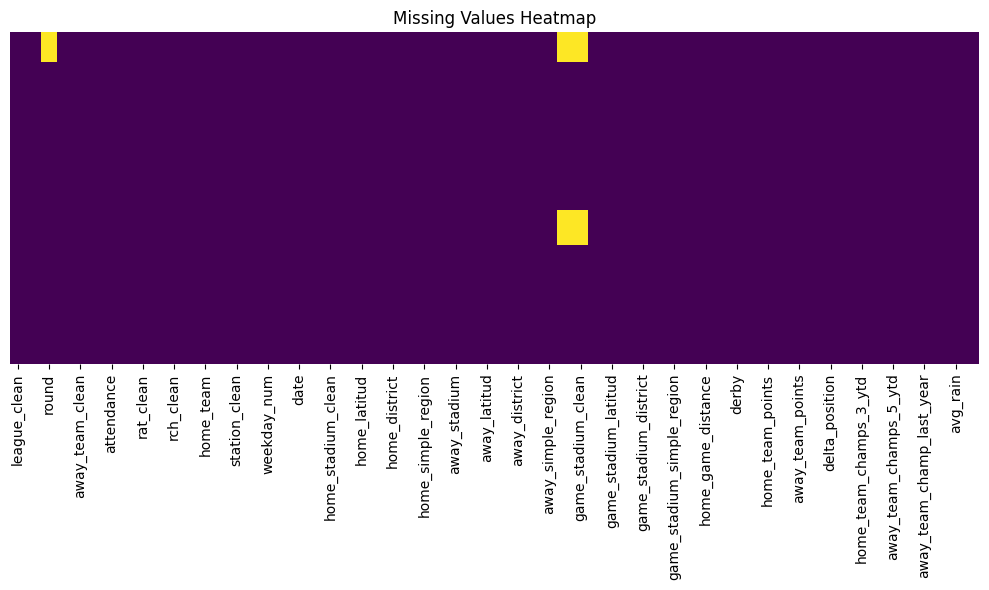

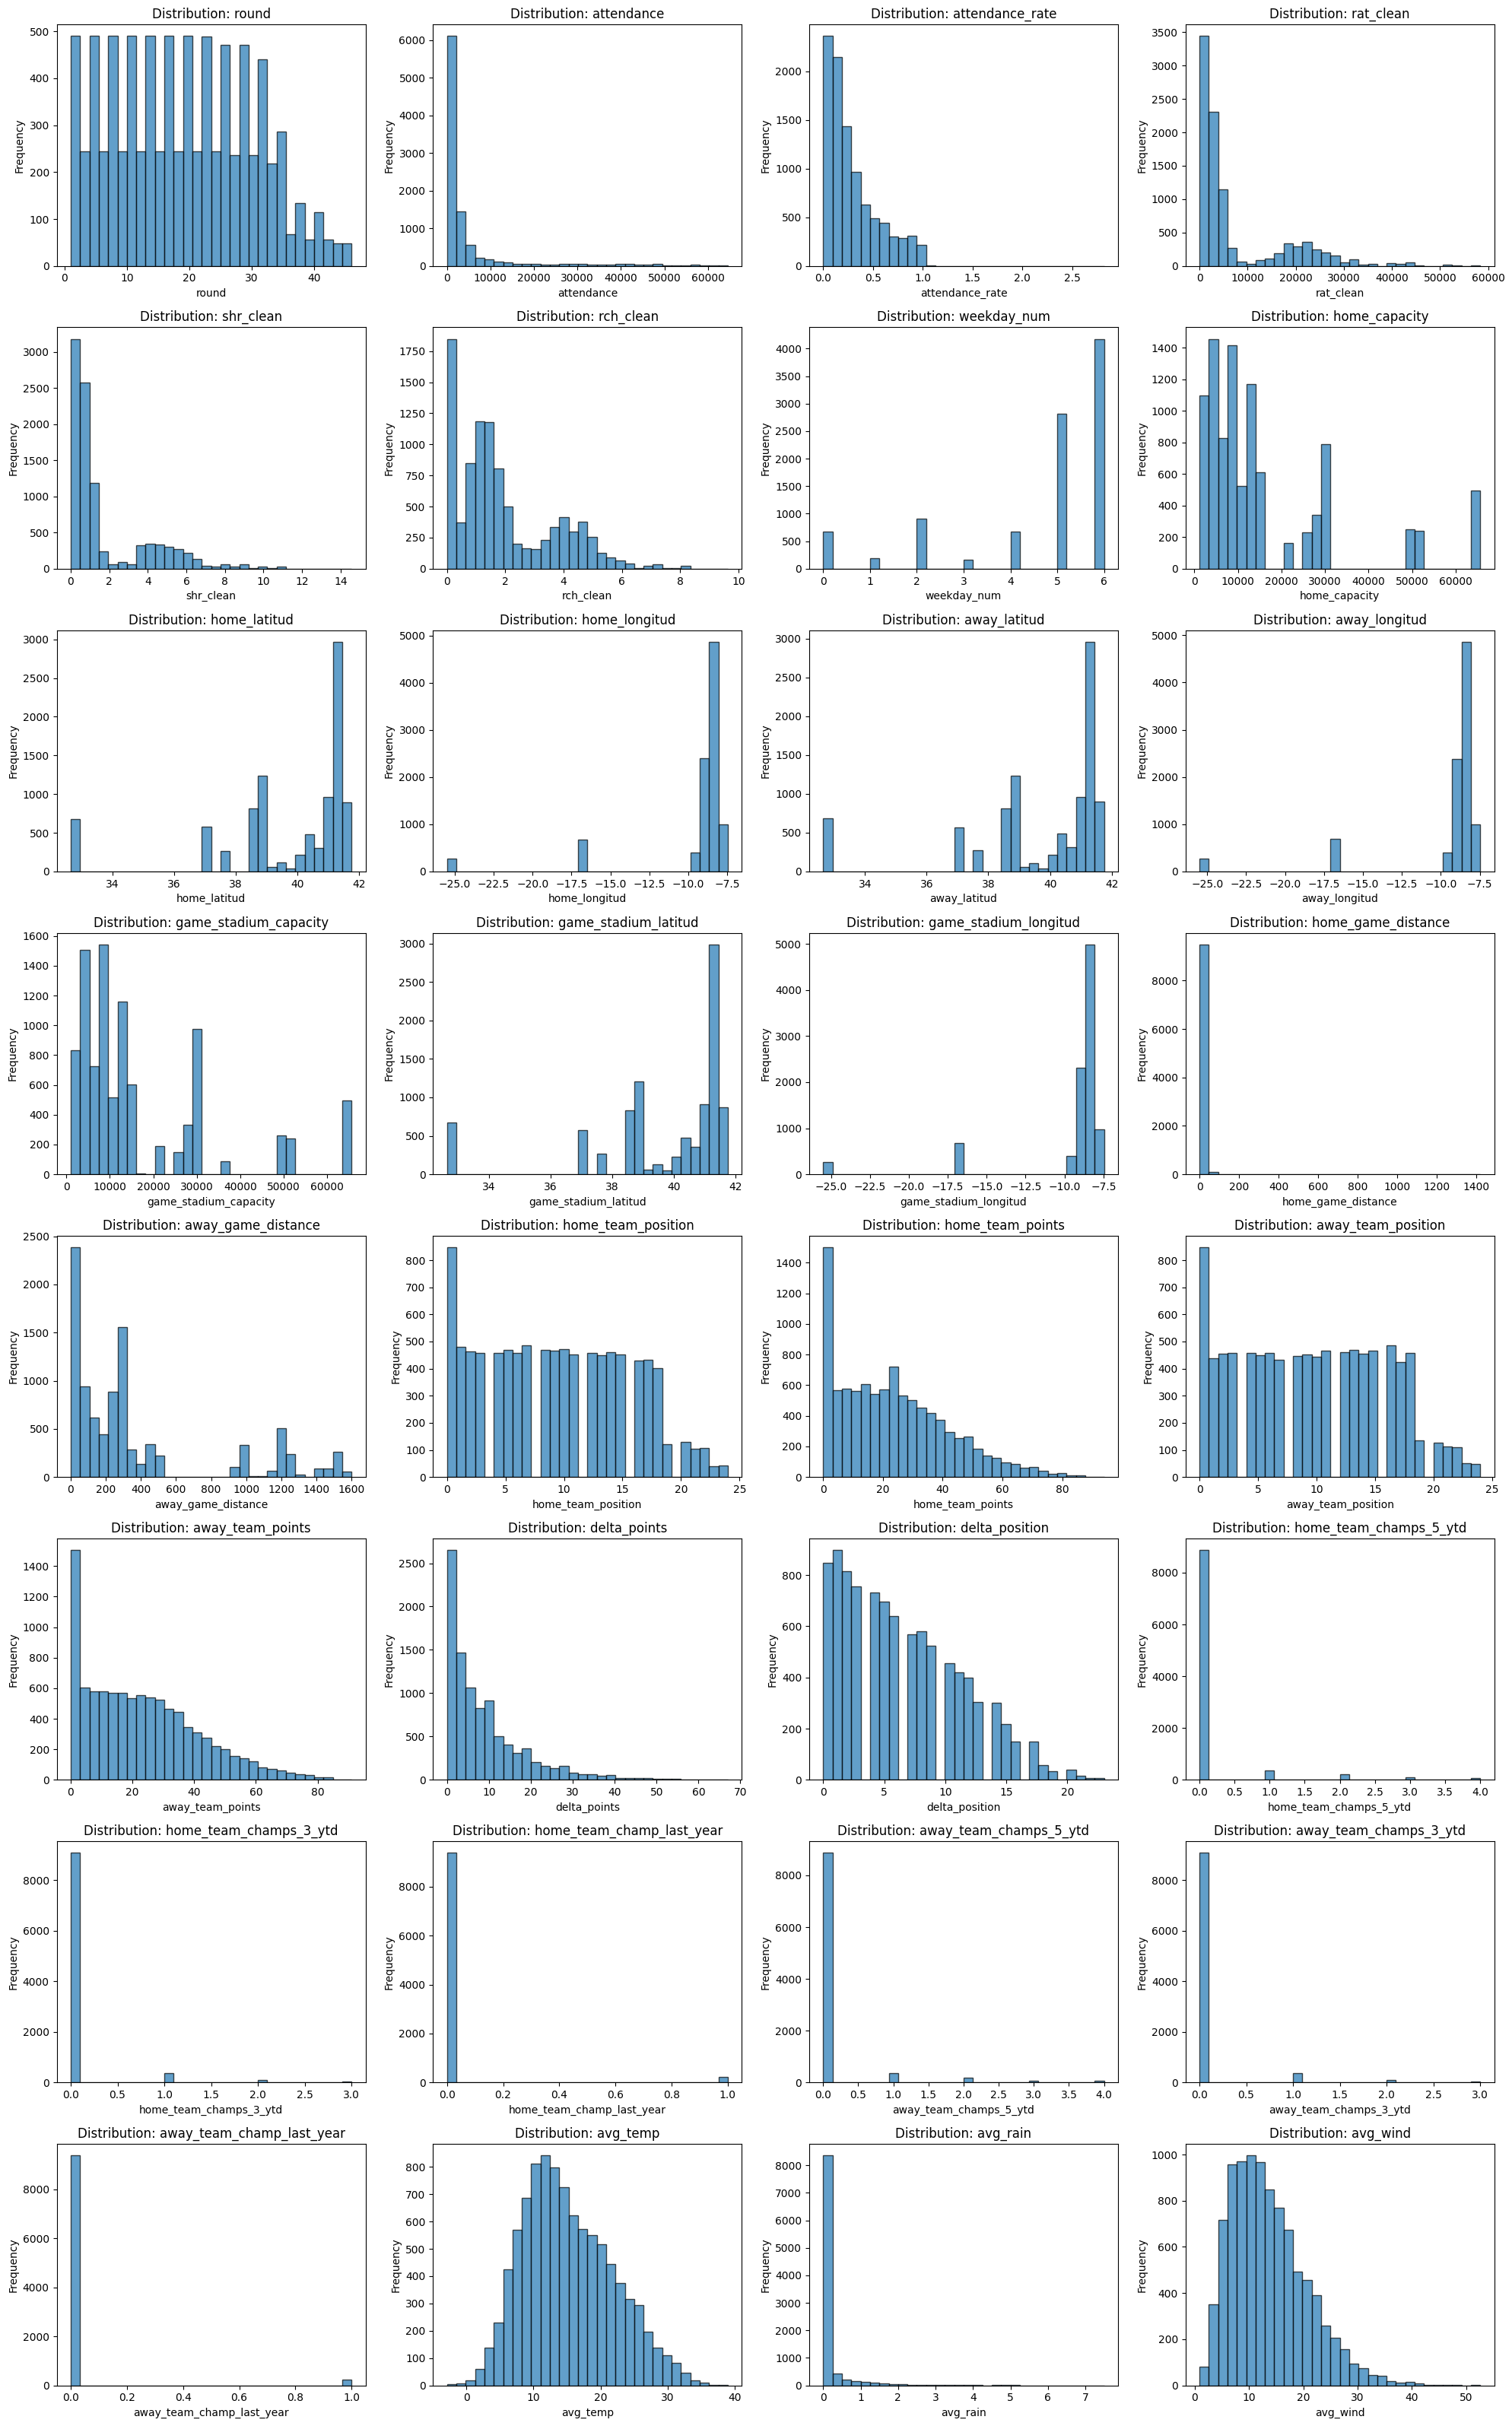

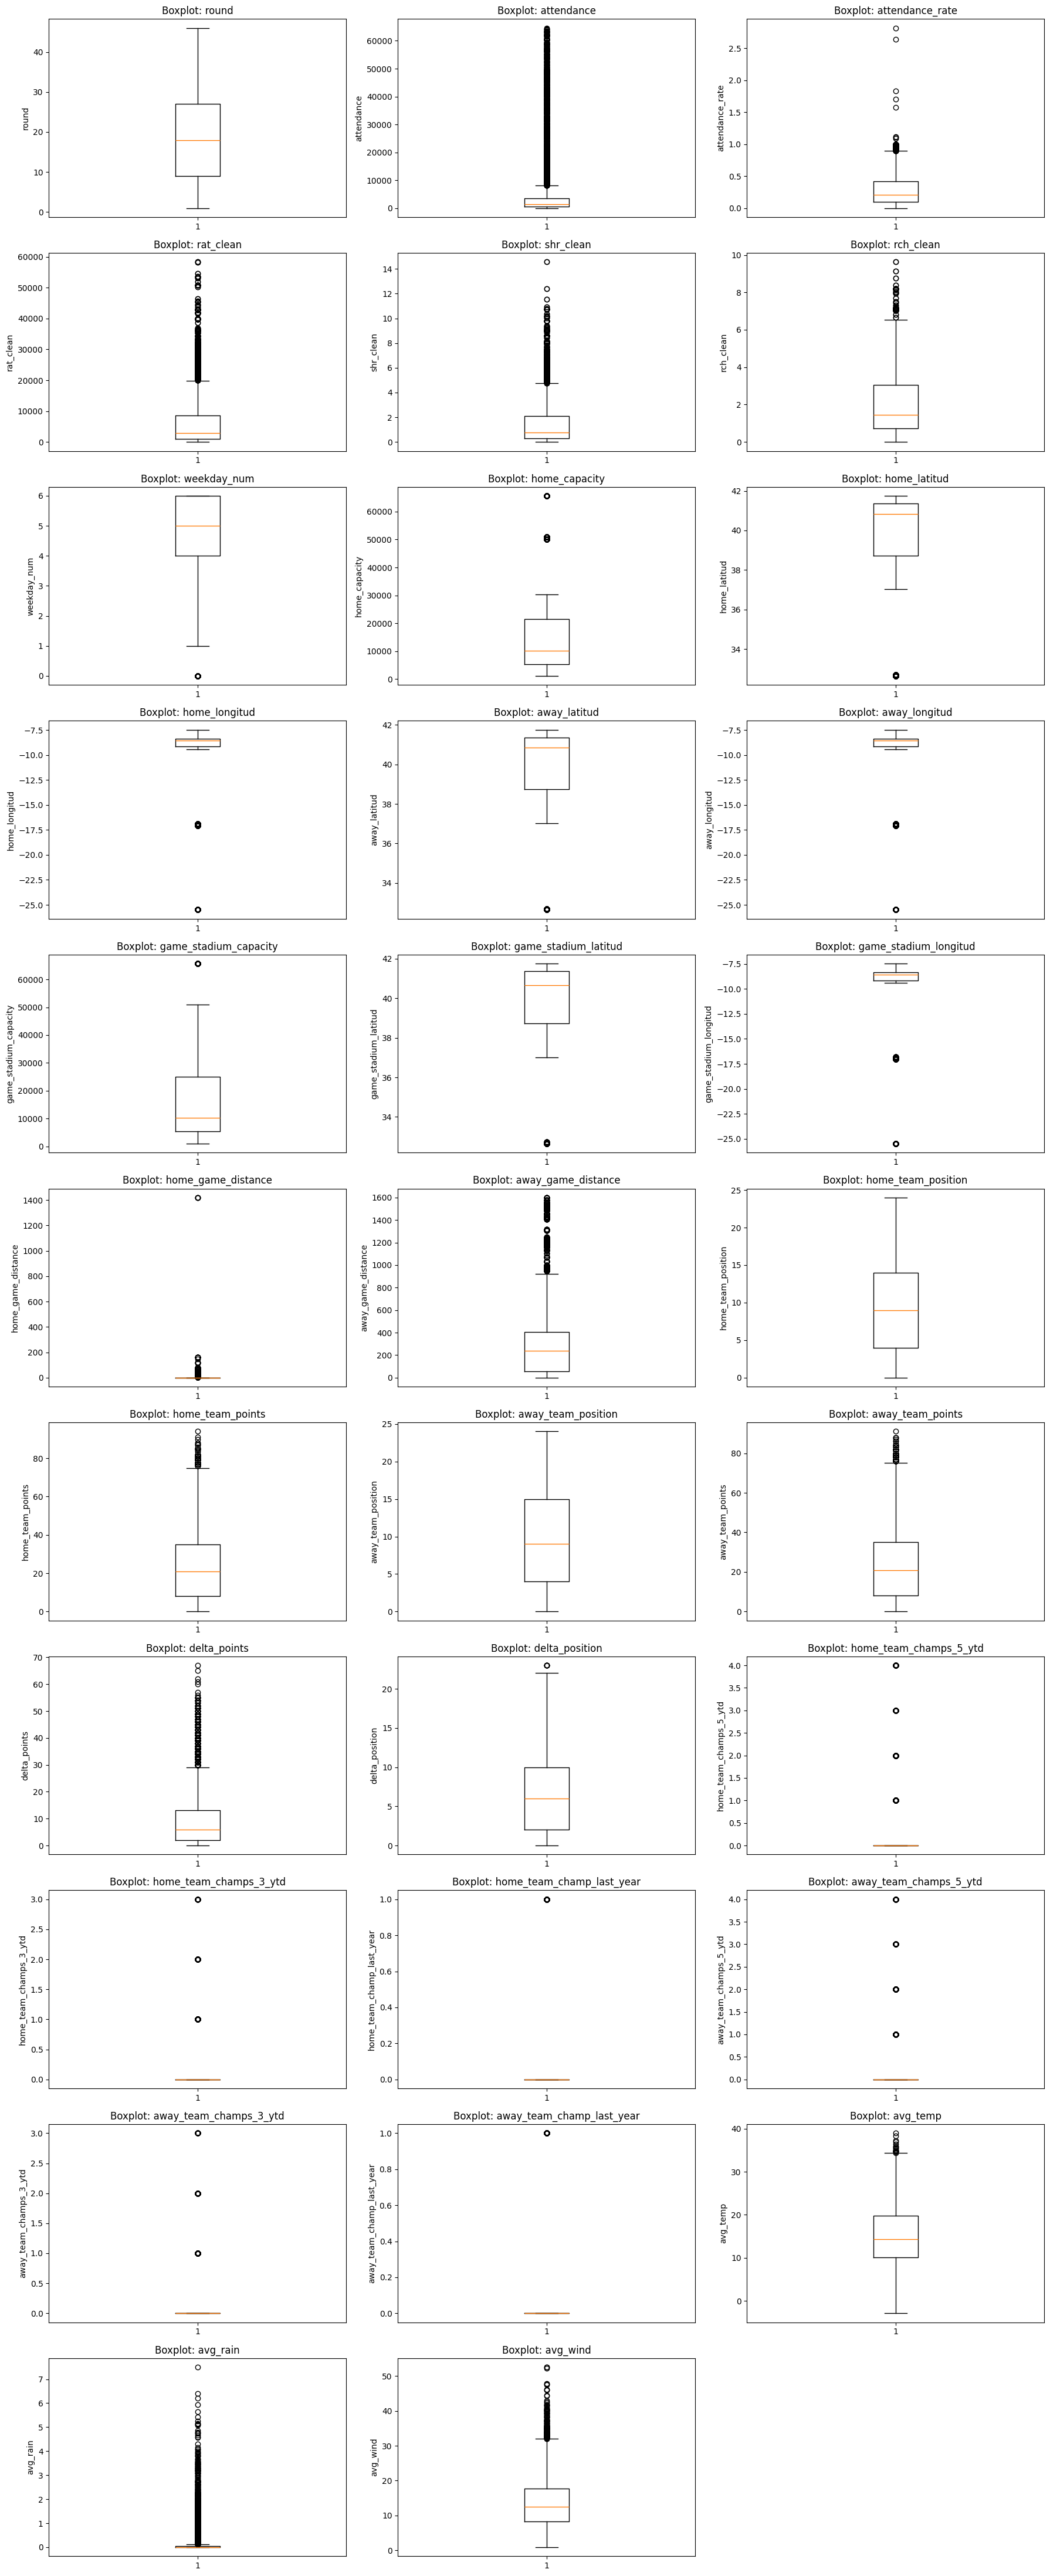

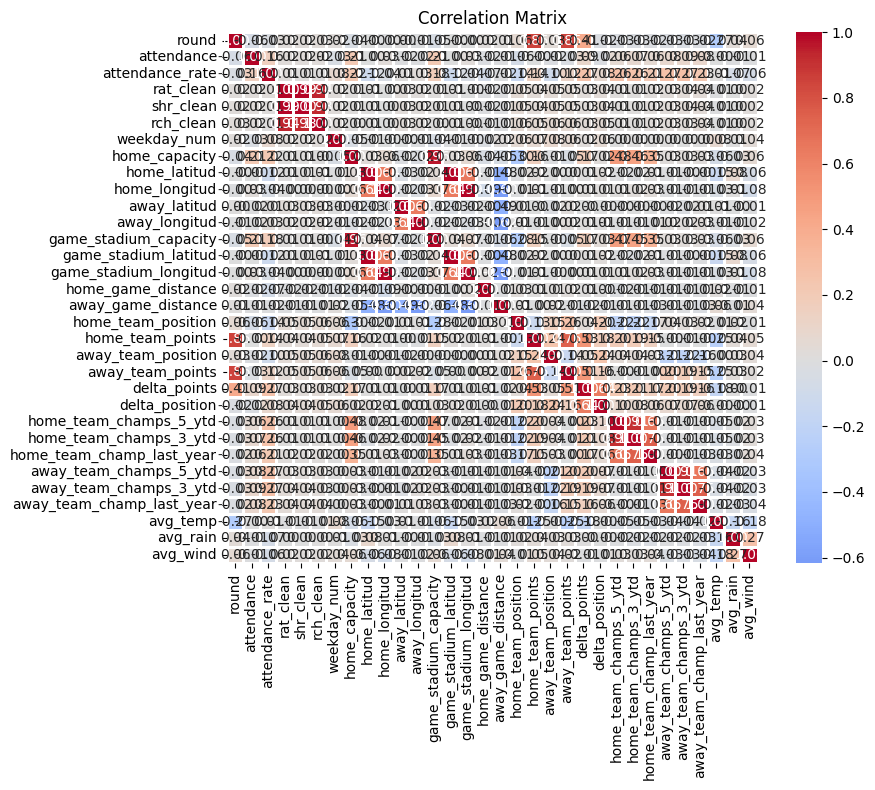

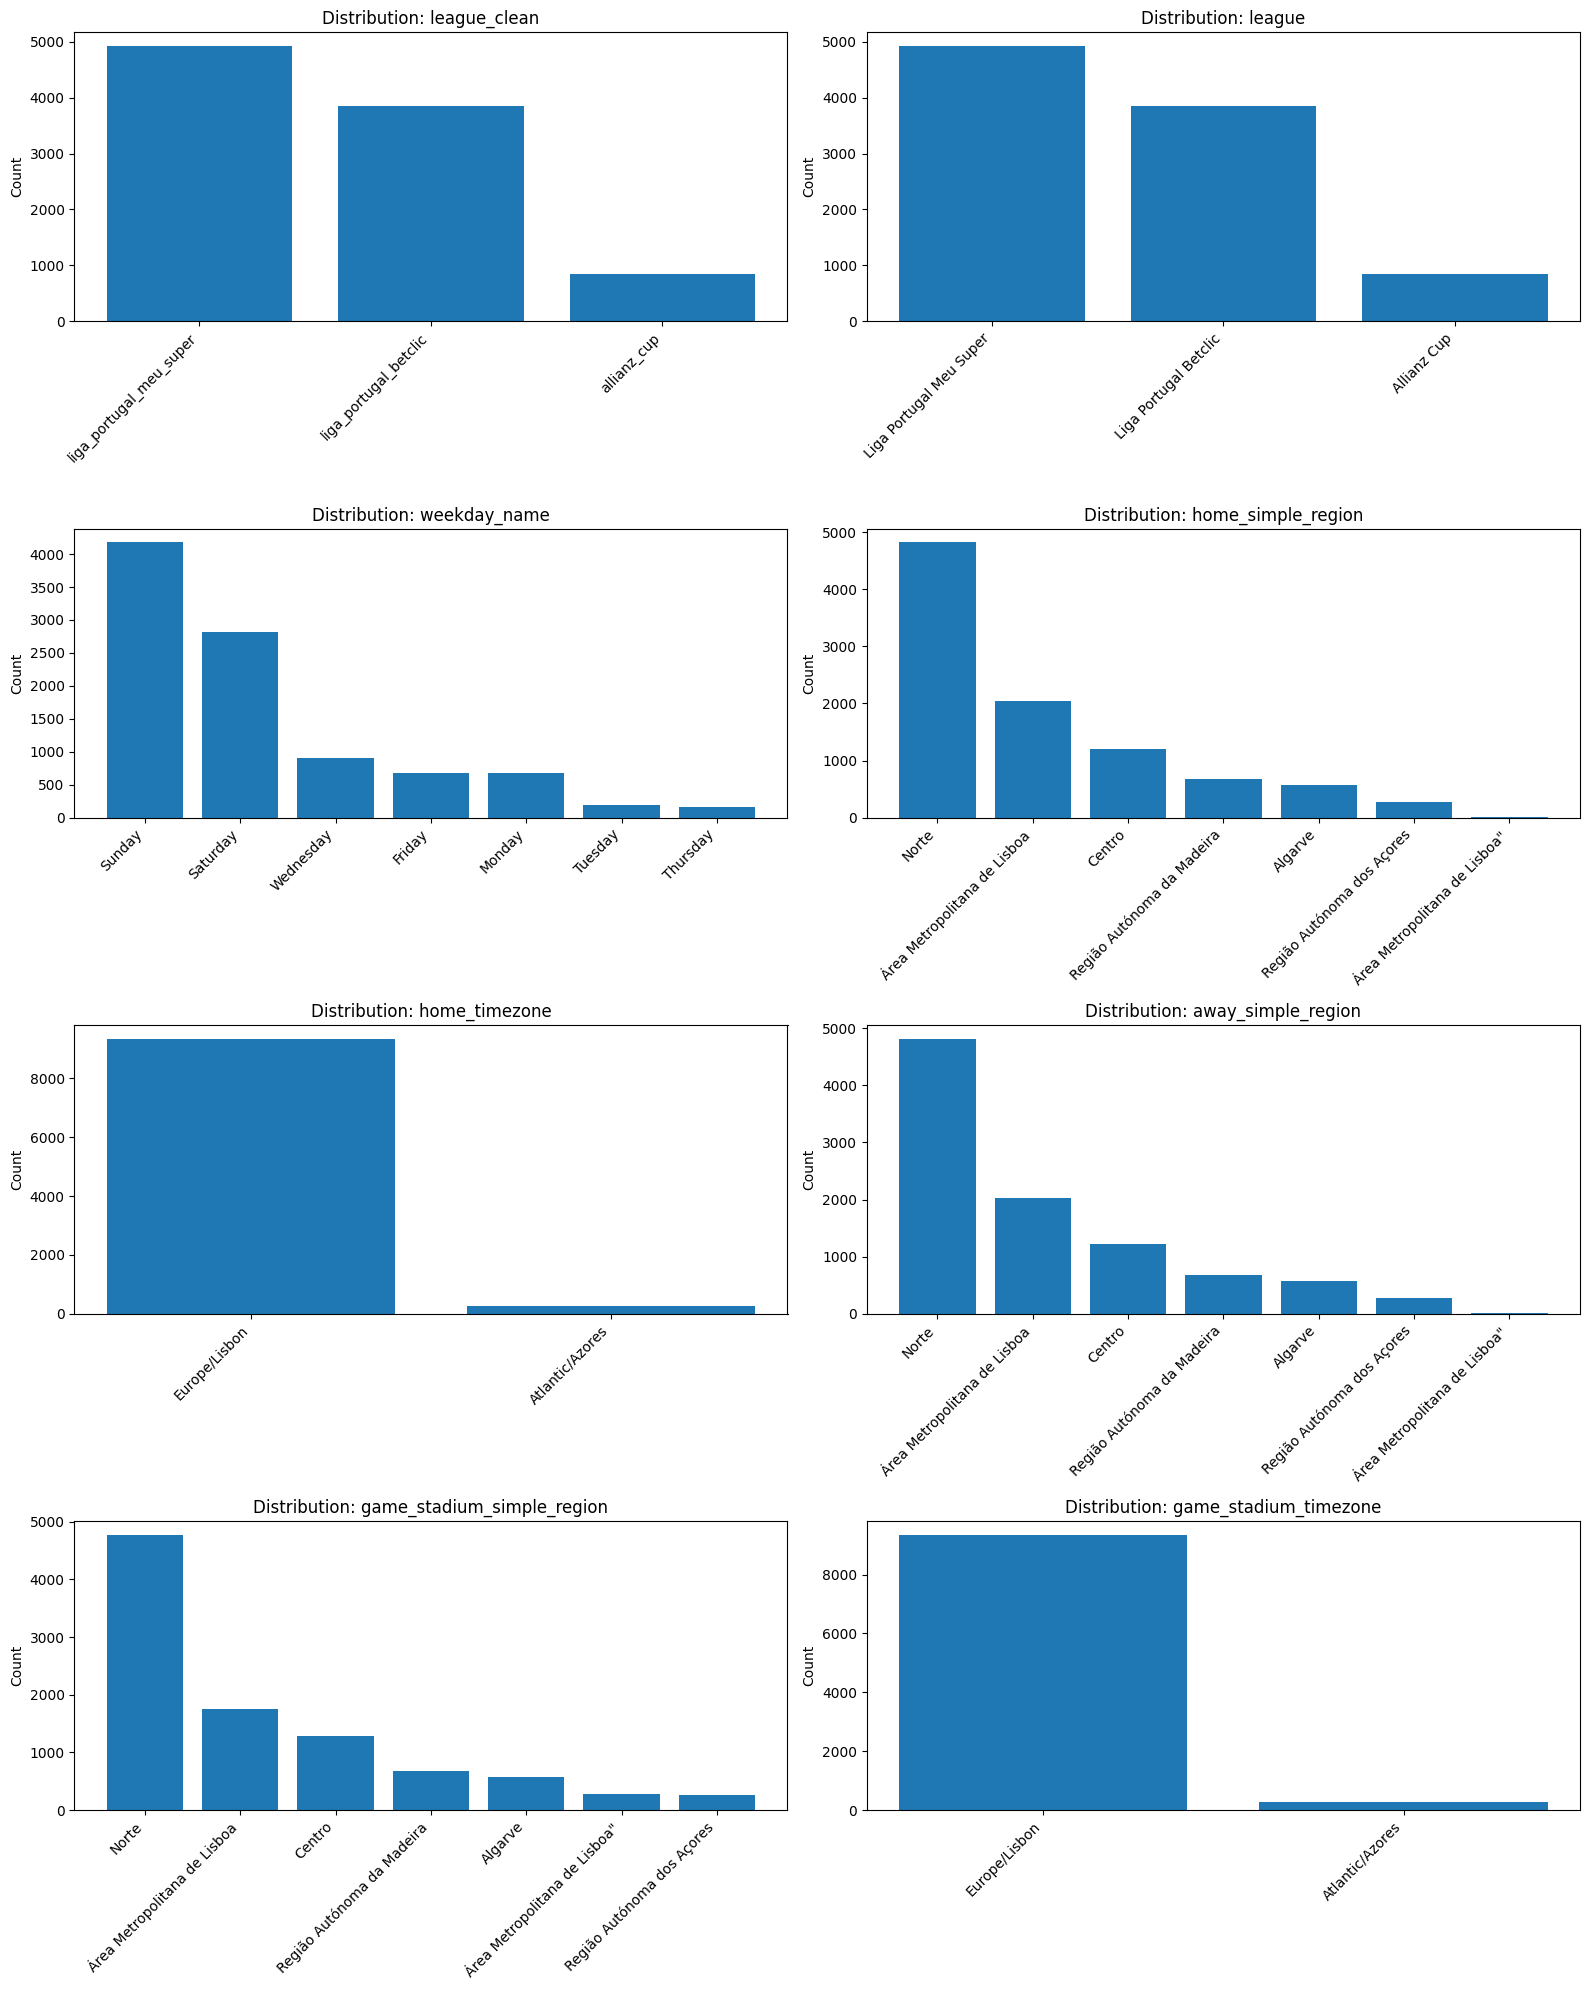

In [ ]:
da.quick_summary(df_processed)  # type: ignore

In [ ]:
display(df_processed.head(10))

,league_clean,season,round,home_team_clean,away_team_clean,date_time,attendance,attendance_rate,rat_clean,shr_clean,...,delta_position,home_team_champs_5_ytd,home_team_champs_3_ytd,home_team_champ_last_year,away_team_champs_5_ytd,away_team_champs_3_ytd,away_team_champ_last_year,avg_temp,avg_rain,avg_wind
0,allianz_cup,200708,<NA>,beiramar,boavista_fc,2007-08-12 19:45:00+00:00,1218,0.040429,0.0,0.000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,19.672991,0.0,21.616033
1,allianz_cup,200708,<NA>,beiramar,fc_penafiel,2008-01-09 19:30:00+00:00,404,0.013410,0.0,0.000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,11.974820,0.0,6.267990
2,allianz_cup,200708,<NA>,beiramar,fc_pferreira,2007-09-26 19:00:00+00:00,591,0.019617,0.0,0.000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,19.742063,0.0,20.629133
3,allianz_cup,200708,<NA>,beiramar,portimonense,2007-10-31 20:00:00+00:00,658,0.021841,0.0,0.000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,13.217622,0.0,11.259079
4,allianz_cup,200708,<NA>,cd_trofense,cd_feirense,2007-08-04 17:00:00+00:00,622,0.113091,2162.5,0.580,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,32.534986,0.0,9.441633
5,allianz_cup,200708,<NA>,cd_trofense,vitoria_sc,2007-08-12 18:00:00+00:00,2146,0.390182,1713.5,0.585,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,22.358493,0.0,14.910527
6,allianz_cup,200708,<NA>,estoril_praia,cd_aves,2007-08-05 16:00:00+00:00,252,0.031500,0.0,0.000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,21.737788,0.0,23.693433
7,allianz_cup,200708,<NA>,estoril_praia,estrela_amadora,2007-08-12 16:00:00+00:00,385,0.048125,0.0,0.000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,20.228193,0.0,23.241466
8,allianz_cup,200708,<NA>,estrela_amadora,sl_benfica,2007-09-26 20:30:00+00:00,2333,0.251184,1703.0,0.385,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,17.327491,0.0,19.945956
9,allianz_cup,200708,<NA>,fatima,a_academica,2007-08-12 17:00:00+00:00,1250,0.809061,3887.0,0.860,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,20.885190,0.0,19.097040


In [ ]:
# Apply the function to process the df_processed DataFrame
df_processed = ls.process_dataframe_slots(
    df_processed,
    liga_col='league',       # Column containing the league name
    weekday_col='weekday_num',   # Column containing the weekday number (0-6)
    hora_col='hour'              # Column containing the hour
)

print("DataFrame 'df_processed' updated with corrected slot information.")
print(df_processed[['league', 'weekday_num', 'hour', 'valid_slot', 'slot_weekday', 'slot_hour']].head())

# Combine corrected weekday and hour into a single column for easier grouping
df_processed['final_slot'] = df_processed['slot_weekday'].astype(str) + ' ' + df_processed['slot_hour'].astype(str)

# Check for missing values in the 'final_slot' column
missing_final_slots = df_processed['final_slot'].isnull().sum()

if missing_final_slots > 0:
    print(f"There are {missing_final_slots} games with no final slot.")
    # Optionally display the rows with missing final slots
    # print(df_processed[df_processed['final_slot'].isnull()])
else:
    print("All games have a final slot.")

# Group by competition and the new schedule column, then count the number of games
schedule_counts = df_processed.groupby(['league', 'final_slot']).size().unstack(fill_value=0)

# Sort the columns (new_schedule) based on weekday and time
# Create a sort key based on weekday number and time object
def sort_key(col_name):
    weekday_str, time_str = col_name.split(' ')
    weekday_num = int(weekday_str)
    time_obj = datetime.strptime(time_str, '%H:%M:%S').time()
    return (weekday_num, time_obj)

# Apply the sort key to the columns
sorted_columns = sorted(schedule_counts.columns, key=sort_key)
schedule_counts = schedule_counts[sorted_columns]

print("Number of games per corrected schedule slot by competition:")
display(schedule_counts)

display(df_processed)

del schedule_counts, missing_final_slots  # Free memory

DataFrame 'df_processed' updated with corrected slot information.
        league  weekday_num      hour  valid_slot  slot_weekday slot_hour
0  Allianz Cup            6  19:45:00        True             6  19:45:00
1  Allianz Cup            2  19:30:00        True             2  19:30:00
2  Allianz Cup            2  19:00:00        True             2  19:00:00
3  Allianz Cup            2  20:00:00        True             2  20:00:00
4  Allianz Cup            5  17:00:00        True             5  17:00:00
All games have a final slot.
Number of games per corrected schedule slot by competition:


final_slot,0 16:00:00,0 18:00:00,0 19:00:00,0 19:15:00,0 19:45:00,0 20:00:00,0 20:15:00,0 20:30:00,0 20:45:00,0 21:15:00,...,6 18:15:00,6 18:30:00,6 19:00:00,6 19:15:00,6 19:30:00,6 19:45:00,6 20:00:00,6 20:15:00,6 20:30:00,6 20:45:00
league,,,,,,,,,,,,,,,,,,,,,
Allianz Cup,1,2,2,1,2,3,6,1,4,1,...,5,2,5,4,1,6,1,10,4,4
Liga Portugal Betclic,0,0,0,0,0,0,484,0,0,0,...,0,0,0,0,0,0,0,0,362,0
Liga Portugal Meu Super,0,291,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


,league_clean,season,round,home_team_clean,away_team_clean,date_time,attendance,attendance_rate,rat_clean,shr_clean,...,away_team_champs_5_ytd,away_team_champs_3_ytd,away_team_champ_last_year,avg_temp,avg_rain,avg_wind,valid_slot,slot_weekday,slot_hour,final_slot
0,allianz_cup,200708,<NA>,beiramar,boavista_fc,2007-08-12 19:45:00+00:00,1218,0.040429,0.0,0.00,...,0.0,0.0,0.0,19.672991,0.000,21.616033,True,6,19:45:00,6 19:45:00
1,allianz_cup,200708,<NA>,beiramar,fc_penafiel,2008-01-09 19:30:00+00:00,404,0.013410,0.0,0.00,...,0.0,0.0,0.0,11.974820,0.000,6.267990,True,2,19:30:00,2 19:30:00
2,allianz_cup,200708,<NA>,beiramar,fc_pferreira,2007-09-26 19:00:00+00:00,591,0.019617,0.0,0.00,...,0.0,0.0,0.0,19.742063,0.000,20.629133,True,2,19:00:00,2 19:00:00
3,allianz_cup,200708,<NA>,beiramar,portimonense,2007-10-31 20:00:00+00:00,658,0.021841,0.0,0.00,...,0.0,0.0,0.0,13.217622,0.000,11.259079,True,2,20:00:00,2 20:00:00
4,allianz_cup,200708,<NA>,cd_trofense,cd_feirense,2007-08-04 17:00:00+00:00,622,0.113091,2162.5,0.58,...,0.0,0.0,0.0,32.534986,0.000,9.441633,True,5,17:00:00,5 17:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9609,liga_portugal_meu_super,202425,34,fc_penafiel,gd_chaves,2025-05-15 18:45:00+00:00,6125,0.104400,0.0,0.00,...,0.0,0.0,0.0,16.003418,0.000,14.047393,False,4,18:00:00,4 18:00:00
9610,liga_portugal_meu_super,202425,34,fc_porto_b,sl_benfica_b,2025-05-17 11:00:00+00:00,771,0.214000,0.0,0.00,...,0.0,0.0,0.0,24.762830,0.000,5.042508,True,5,11:00:00,5 11:00:00
9611,liga_portugal_meu_super,202425,34,leixoes_sc,cd_feirense,2025-05-14 20:15:00+00:00,553,0.295300,0.0,0.00,...,0.0,0.0,0.0,11.430386,0.000,15.077205,False,4,18:00:00,4 18:00:00
9612,liga_portugal_meu_super,202425,34,maritimo_m,fc_vizela,2025-05-16 20:30:00+00:00,2863,0.577600,0.0,0.00,...,0.0,0.0,0.0,17.609247,0.275,3.535532,False,4,18:00:00,4 18:00:00


In [ ]:
# Filter the DataFrame to show rows where 'slot_valido' is False (invalid slots) AND the weekday is Tuesday, Wednesday, or Thursday
# Weekday_num: Monday=0, Tuesday=1, Wednesday=2, Thursday=3, Friday=4, Saturday=5, Sunday=6
df_invalid_slots_tue_thu = df_processed[(df_processed['valid_slot'] == False) & (df_processed['slot_weekday'].isin([1, 2, 3]))].copy()

print("Rows with invalid original slots from Tuesday to Thursday and their corrected slot information:")
# Display relevant columns
print(df_invalid_slots_tue_thu[['league', 'weekday_num', 'hour', 'slot_weekday', 'slot_hour', 'final_slot']].head())
print("...")
print(df_invalid_slots_tue_thu[['league', 'weekday_num', 'hour', 'slot_weekday', 'slot_hour', 'final_slot']].tail())

print(f"\nTotal number of games with invalid original slots from Tuesday to Thursday: {len(df_invalid_slots_tue_thu)}")

del df_invalid_slots_tue_thu  # Free memory

Rows with invalid original slots from Tuesday to Thursday and their corrected slot information:
Empty DataFrame
Columns: [league, weekday_num, hour, slot_weekday, slot_hour, final_slot]
Index: []
...
Empty DataFrame
Columns: [league, weekday_num, hour, slot_weekday, slot_hour, final_slot]
Index: []

Total number of games with invalid original slots from Tuesday to Thursday: 0


In [ ]:
# Adiciona a coluna calculada ao df_processed original
df_processed = ls.calcular_data_hora_final(df_processed)

# Filtra e imprime apenas os casos onde houve mudança de dia
# Compara weekday da Data_Hora original com Data_Hora_Final
mudanca_dia = df_processed[df_processed['date_time'].dt.weekday != df_processed['final_weekday_num']].copy()

if len(mudanca_dia) > 0:
    print(f"\nJogos com mudança de dia: {len(mudanca_dia)}")
    display(mudanca_dia[['league', 'date_time', 'final_weekday_num', 'final_slot']])
else:
    print("\nNenhum jogo teve mudança de dia.")

print("\nColunas finais do DataFrame:")
print(df_processed.columns.tolist())

del mudanca_dia  # Free memory


Jogos com mudança de dia: 896


,league,date_time,final_weekday_num,final_slot
923,Liga Portugal Betclic,2012-11-27 20:15:00+00:00,0,0 20:15:00
943,Liga Portugal Betclic,2013-01-23 20:15:00+00:00,4,4 20:15:00
1196,Liga Portugal Betclic,2013-12-19 20:00:00+00:00,4,4 20:15:00
1218,Liga Portugal Betclic,2014-02-05 20:00:00+00:00,4,4 20:15:00
1230,Liga Portugal Betclic,2014-02-11 20:15:00+00:00,0,0 20:15:00
...,...,...,...,...
9581,Liga Portugal Meu Super,2025-04-29 20:00:00+00:00,0,0 18:00:00
9585,Liga Portugal Meu Super,2025-04-30 18:00:00+00:00,4,4 18:00:00
9606,Liga Portugal Meu Super,2025-05-15 20:45:00+00:00,4,4 18:00:00
9609,Liga Portugal Meu Super,2025-05-15 18:45:00+00:00,4,4 18:00:00



Colunas finais do DataFrame:
['league_clean', 'season', 'round', 'home_team_clean', 'away_team_clean', 'date_time', 'attendance', 'attendance_rate', 'rat_clean', 'shr_clean', 'rch_clean', 'league', 'home_team', 'away_team', 'station_clean', 'weekday_name', 'weekday_num', 'hour', 'date', 'home_stadium', 'home_stadium_clean', 'home_capacity', 'home_latitud', 'home_longitud', 'home_district', 'home_detailed_region', 'home_simple_region', 'home_timezone', 'away_stadium', 'away_stadium_clean', 'away_latitud', 'away_longitud', 'away_district', 'away_detailed_region', 'away_simple_region', 'game_stadium', 'game_stadium_clean', 'game_stadium_capacity', 'game_stadium_latitud', 'game_stadium_longitud', 'game_stadium_district', 'game_stadium_detailed_region', 'game_stadium_simple_region', 'game_stadium_timezone', 'home_game_distance', 'away_game_distance', 'derby', 'home_team_position', 'home_team_points', 'away_team_position', 'away_team_points', 'delta_points', 'delta_position', 'home_team_cha

In [ ]:
# Create a subset with unique combinations of EquipaCasa and EquipaCasa_cleaned
df_unique_teams = df_processed[['home_team', 'home_team_clean']].drop_duplicates().sort_values('home_team')

print("\nTotal unique teams:", len(df_unique_teams))
display(df_unique_teams)

# Save to CSV
output_filename = DataFilesPath + '/lista_equipas.csv'
fo.safe_to_csv(df_unique_teams, output_filename, index=False, encoding='utf-8', sep=';', decimal='.')


Total unique teams: 64


,home_team,home_team_clean
38,A. Académica,a_academica
529,AD Fafe,ad_fafe
708,AFS,afs
328,Académico,academico
202,Atlético CP,atletico_cp
...,...,...
32,Varzim SC,varzim_sc
7887,Vilafranquense,vilafranquense
33,Vitória FC,vitoria_fc
37,Vitória SC,vitoria_sc


Successfully saved to /home/jovyan/Base de Dados/lista_equipas.csv


True

In [ ]:
#Normalize 'Espetadores', Rat, Rch and Shr using log transformation

# 1. Coluna Espetadores
df_processed['attendance_log'] = np.log1p(df_processed['attendance'])

# 2. Coluna RAT
df_processed['rat_log'] = np.log1p(df_processed['rat_clean'])

# 3. Coluna RCH
df_processed['rch_log'] = np.log1p(df_processed['rch_clean'])

# 4. Coluna SHR
df_processed['rhr_log'] = np.log1p(df_processed['shr_clean'])

In [ ]:
# Define bins for Distancia_km (e.g., every 100 km)

bins_casa = range(0, int(df_processed['home_game_distance'].max()) + 100, 100)
bins_fora = range(0, int(df_processed['away_game_distance'].max()) + 100, 100)

# Create the 'distancia_casa_jogo_bin' column in df_processed
df_processed['home_game_distance_bin'] = pd.cut(df_processed['home_game_distance'], bins=bins_casa, right=False)

# Create the 'distancia_fora_jogo_bin' column in df_processed
df_processed['away_game_distance_bin'] = pd.cut(df_processed['away_game_distance'], bins=bins_fora, right=False)

In [ ]:
display(df_processed)

,league_clean,season,round,home_team_clean,away_team_clean,date_time,attendance,attendance_rate,rat_clean,shr_clean,...,slot_hour,final_slot,final_weekday_num,final_date_time,attendance_log,rat_log,rch_log,rhr_log,home_game_distance_bin,away_game_distance_bin
0,allianz_cup,200708,<NA>,beiramar,boavista_fc,2007-08-12 19:45:00+00:00,1218,0.040429,0.0,0.00,...,19:45:00,6 19:45:00,6,2007-08-12 19:45:00+00:00,7.105786,0.000000,0.000000,0.000000,"[0, 100)","[0, 100)"
1,allianz_cup,200708,<NA>,beiramar,fc_penafiel,2008-01-09 19:30:00+00:00,404,0.013410,0.0,0.00,...,19:30:00,2 19:30:00,2,2008-01-09 19:30:00+00:00,6.003887,0.000000,0.000000,0.000000,"[0, 100)","[0, 100)"
2,allianz_cup,200708,<NA>,beiramar,fc_pferreira,2007-09-26 19:00:00+00:00,591,0.019617,0.0,0.00,...,19:00:00,2 19:00:00,2,2007-09-26 19:00:00+00:00,6.383507,0.000000,0.000000,0.000000,"[0, 100)","[0, 100)"
3,allianz_cup,200708,<NA>,beiramar,portimonense,2007-10-31 20:00:00+00:00,658,0.021841,0.0,0.00,...,20:00:00,2 20:00:00,2,2007-10-31 20:00:00+00:00,6.490724,0.000000,0.000000,0.000000,"[0, 100)","[300, 400)"
4,allianz_cup,200708,<NA>,cd_trofense,cd_feirense,2007-08-04 17:00:00+00:00,622,0.113091,2162.5,0.58,...,17:00:00,5 17:00:00,5,2007-08-04 17:00:00+00:00,6.434547,7.679483,1.080109,0.457425,"[0, 100)","[0, 100)"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9609,liga_portugal_meu_super,202425,34,fc_penafiel,gd_chaves,2025-05-15 18:45:00+00:00,6125,0.104400,0.0,0.00,...,18:00:00,4 18:00:00,4,2025-05-16 18:00:00+00:00,8.720297,0.000000,0.000000,0.000000,"[0, 100)","[0, 100)"
9610,liga_portugal_meu_super,202425,34,fc_porto_b,sl_benfica_b,2025-05-17 11:00:00+00:00,771,0.214000,0.0,0.00,...,11:00:00,5 11:00:00,5,2025-05-17 11:00:00+00:00,6.648985,0.000000,0.000000,0.000000,"[0, 100)","[200, 300)"
9611,liga_portugal_meu_super,202425,34,leixoes_sc,cd_feirense,2025-05-14 20:15:00+00:00,553,0.295300,0.0,0.00,...,18:00:00,4 18:00:00,4,2025-05-16 18:00:00+00:00,6.317165,0.000000,0.000000,0.000000,"[0, 100)","[0, 100)"
9612,liga_portugal_meu_super,202425,34,maritimo_m,fc_vizela,2025-05-16 20:30:00+00:00,2863,0.577600,0.0,0.00,...,18:00:00,4 18:00:00,4,2025-05-16 18:00:00+00:00,7.959975,0.000000,0.000000,0.000000,"[0, 100)","[1200, 1300)"


In [ ]:
# --- Guardar para CSV ---


normalized_output_filename = DataFilesPath + '/liga_base_data_normalized.csv'
fo.safe_to_csv(df_processed, normalized_output_filename, index=False, encoding='utf-8', sep=';', decimal='.')

Successfully saved to /home/jovyan/Base de Dados/liga_base_data.csv
Successfully saved to /home/jovyan/Base de Dados/liga_base_data_normalized.csv


True